# 13 · Classifieurs — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookIA/blob/main/chapitres/ch13_classifieurs/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wb.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | 13.Q1 à 13.Q12, 13.R1 à 13.R3, 13.1 à 13.7, 13.9 | vérifier tes réponses courtes | 🧠 🔁 ✏️ 🧮 | ★ à ★★★ | |
| A | 13.12 | Prédire la frontière de cinq classifieurs avant de l'afficher | 🔮 | ★ | 15 |
|  | 13.13 | Choisir k : de la frontière en dents de scie à l'érosion | 🔬 | ★★ | 30 |
|  | 13.14 | Coder pairwise_distances et KNeighborsClassifier | 🔨 | ★★★ | 45 |
|  | 13.15 | kNN et malédiction de la dimension | 🔬 | ★★★ | 35 |
| B | 13.16 | SVM linéaire : vecteurs de support et paramètre C | 📦 | ★★ | 25 |
|  | 13.17 | Relever les cercles en 3D pour les séparer par un plan | 🎨 | ★★ | 30 |
|  | 13.18 | Noyau RBF : régler C et gamma par validation croisée | 📦 | ★★★ | 35 |
| C | 13.19 | Instabilité et profondeur d'un arbre | 🔬 | ★★ | 30 |
|  | 13.20 | Coder les impuretés et le gain d'un split | 🔨 | ★★ | 25 |
|  | 13.21 | L'arbre parfait qui triche : une colonne identifiant | 🐛 | ★★ | 20 |
|  | 13.22 | Coder la recherche du meilleur split | 🔨 | ★★★ | 45 |
|  | 13.23 | Arbres scikit-learn : plot_tree, export_text et élagage ccp_alpha | 📦 | ★★★ | 35 |
|  | 13.24 | Coder un arbre de décision récursif | 🔨 | ★★★★ | 100 |
|  | 13.25 | Préparer l'arbre pour les ensembles : poids, features tirées, importances | 🔨 | ★★★ | 50 |
|  | 13.26 | Arbre de régression : même squelette, autre critère | 🔨 | ★★ | 30 |
| D | 13.27 | Naïve Bayes sur des blobs gaussiens puis sur des lunes | 🔮 | ★ | 10 |
|  | 13.28 | Coder GaussianNB avec log-densités et logsumexp | 🔨 | ★★★ | 40 |
|  | 13.29 | Coder MultinomialNB avec lissage | 🔨 | ★★ | 30 |
|  | 13.30 | Dialogue ou narration ? Classer des phrases de Holmes : sac de mots, TF-IDF et Naïve Bayes | 📦 | ★★★ | 40 |
| E | 13.31 | Régression logistique scikit-learn : coefficients et probabilités | 📦 | ★★ | 25 |
|  | 13.32 | Coder la régression logistique par descente de gradient | 🔨 | ★★★ | 50 |
| F | 13.33 | Associer quatre frontières à leurs classifieurs | 📈 | ★ | 15 |
|  | 13.34 | Mesurer et vectoriser : accélérer son kNN | 🛠️ | ★★ | 25 |
|  | 13.35 | Comparatif mylearn contre scikit-learn : accuracy et temps | 🔬 | ★★★ | 45 |
|  | 13.36 | Défi : 96 % sur MNIST avec un classifieur classique | 🏆 | ★★★★ | 100 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (CPU, a few minutes); False = full version
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookIA.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookIA")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WB_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wb").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wb").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier du workbook.")

os.environ["WB_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wb  # noqa: E402

cfg = wb.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mylearn = wb.load_mylearn("ref")  # reference implementation

🧪 Deep Learning Workbook : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.13 | numpy 2.1.3 | pandas 2.2.3 | matplotlib 3.10.0 | scikit-learn 1.6.1 | scipy 1.16.3 | torch 2.11.0+cpu | torchvision 0.26.0+cpu
   Device : cpu | Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Calculer à la main un vote de k plus proches voisins, une marge, une impureté, un gain de split et un posterior de Naïve Bayes.
- Écrire et vérifier contre scikit-learn les classifieurs de ta librairie : `KNeighborsClassifier`, les arbres de `mylearn.tree` (prêts pour les ensembles du ch. 14), `GaussianNB`, `MultinomialNB` et `LogisticRegression`.
- Régler $k$, C, $\gamma$ et la profondeur d'un arbre par validation croisée, et limiter l'overfitting d'un arbre.
- Comparer les classifieurs (accuracy, temps, mémoire, explicabilité) et choisir une baseline.

**Rappel express.** Distances : $\sqrt{\sum_j (x_j - z_j)^2}$ et $\sum_j \lvert x_j - z_j \rvert$ ; distance à un hyperplan : $\lvert \mathbf{w} \cdot \mathbf{x} + b \rvert / \lVert \mathbf{w} \rVert$, largeur de la bande $2/\lVert \mathbf{w} \rVert$ ; noyau RBF : $e^{-\gamma \lVert \mathbf{x} - \mathbf{z} \rVert^2}$ ; Gini : $1 - \sum_c p_c^2$ ; entropie : $-\sum_c p_c \log_2 p_c$ ; gain : $I(\text{parent}) - \frac{n_G}{n} I(G) - \frac{n_D}{n} I(D)$ ; Naïve Bayes : $\log P(c) + \sum_j \log P(x_j \mid c)$, normalisé par logsumexp ; lissage : $\frac{N_{cj} + \alpha}{N_c + \alpha d}$ ; régression logistique : $\hat p = \sigma(\mathbf{w} \cdot \mathbf{x} + b)$, gradient $\frac1n \mathbf{X}^\top (\hat{\mathbf{p}} - \mathbf{y})$. En Python : `sklearn.neighbors.KNeighborsClassifier`, `sklearn.svm.SVC`, `sklearn.tree` (`DecisionTreeClassifier`, `plot_tree`, `export_text`), `sklearn.naive_bayes` (`GaussianNB`, `MultinomialNB`), `sklearn.linear_model.LogisticRegression`, `sklearn.model_selection.GridSearchCV`.

## Partie 0 · Vérifier tes réponses courtes (quiz, rappels, ✏️ 13.1 à 13.7 et 🧮 13.9)

Fais d'abord les quiz, les rappels et les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse courte ici : **la valeur** que tu as trouvée, pas l'expression Python, sinon tu ne vérifies rien. Un nombre : `42` ou `0.3` (en Python, le séparateur décimal est un **point** ; `0,3` sans guillemets serait un couple de deux nombres) ; un vrai ou faux : `True` ou `False` ; un choix : la lettre seule, entre guillemets (`"E"`) ; une suite de codes : les lettres dans l'ordre (`"XYZ"`) ; plusieurs nombres : une liste (`[4, 7]`). Arrondis comme l'énoncé le demande, et seulement à la fin du calcul. Les réponses pas encore remplies affichent ⏳. Les questions « dans ta copie », la preuve ∂ 13.8, la réflexion (🗣️ 13.10, ⚖️ 13.11) et l'entretien se corrigent avec `05_solutions.md`.

In [2]:
# The short answers only use the numbers of their statements (02_exercices.md)
import math

import numpy as np
from scipy.stats import norm


def gini(counts):
    p = np.asarray(counts, dtype=float) / np.sum(counts)
    return float(1 - np.sum(p ** 2))


def entropy_bits(probs):
    p = np.asarray(probs, dtype=float)
    p = p[p > 0]
    return float(-np.sum(p * np.log2(p)))


def posterior_first(l_first, l_second):
    """P(first class | x) from two joint log-probabilities."""
    return float(1 / (1 + math.exp(l_second - l_first)))


# R1: three penguins (flipper in mm, mass in g) and the training standard deviations
A_R1, B_R1, C_R1 = np.array([190.0, 3700.0]), np.array([210.0, 3750.0]), np.array([192.0, 3800.0])
SD_R1 = np.array([14.0, 800.0])

# 13.1: seven training samples, the query (0, 0)
X_131 = np.array([[1, 1], [-1.5, 0], [0, 2], [2, -1.5], [-2, -2], [3, 0], [0, -3.5]])
Y_131 = np.array([1, 0, 0, 1, 2, 2, 2])
D_131 = np.linalg.norm(X_131, axis=1)          # euclidean distances to (0, 0)
M_131 = np.abs(X_131).sum(axis=1)              # manhattan distances
ORDER_131 = np.argsort(D_131, kind="stable")


def vote_131(k, weighted=False):
    """Class shares of the k nearest samples (euclidean), uniform or 1/d votes."""
    idx = ORDER_131[:k]
    w = 1 / D_131[idx] if weighted else np.ones(k)
    share = np.array([w[Y_131[idx] == c].sum() for c in range(3)])
    return share / share.sum()


# 13.3: ten flippers, Adelie (0) and Gentoo (1)
FL_133 = np.array([181, 186, 190, 193, 197, 210, 205, 215, 217, 228])
SP_133 = np.array([0, 0, 0, 0, 0, 0, 1, 1, 1, 1])
VALUES_133 = np.unique(FL_133)
THRESHOLDS_133 = (VALUES_133[:-1] + VALUES_133[1:]) / 2


def gain_133(s, impurity="gini"):
    left, right = SP_133[FL_133 <= s], SP_133[FL_133 > s]
    if impurity == "gini":
        f = lambda y: gini(np.bincount(y, minlength=2))
    else:
        f = lambda y: entropy_bits(np.bincount(y, minlength=2) / len(y))
    return f(SP_133) - len(left) / 10 * f(left) - len(right) / 10 * f(right)


BEST_133 = float(max(THRESHOLDS_133, key=gain_133))

# 13.4: six points, w = (0.5, 0.5), b = -2
P_134 = np.array([[3, 3], [5, 4], [4, 5], [1, 1], [0, 1], [2, 0]], dtype=float)
Y_134 = np.array([1, 1, 1, -1, -1, -1])
W_134, B_134 = np.array([0.5, 0.5]), -2.0
F_134 = P_134 @ W_134 + B_134
NORM_134 = float(np.linalg.norm(W_134))

# 13.5: x = (1, 2), z = (3, 1)
X_135, Z_135 = np.array([1.0, 2.0]), np.array([3.0, 1.0])
PHI = lambda v: np.array([v[0] ** 2, math.sqrt(2) * v[0] * v[1], v[1] ** 2])
K_135 = lambda a, b: float(a @ b) ** 2

# 13.6: letter counts e, h, q, w
EN_136, FR_136 = np.array([30, 12, 1, 7]), np.array([38, 4, 8, 0])
TH_EN = (EN_136 + 1) / (EN_136.sum() + 4)
TH_FR = (FR_136 + 1) / (FR_136.sum() + 4)
WHERE, QUE = np.array([2, 1, 0, 1]), np.array([1, 0, 1, 0])
L_EN = math.log(0.6) + WHERE @ np.log(TH_EN)
L_FR = math.log(0.4) + WHERE @ np.log(TH_FR)

# 13.7: Gaussian naive Bayes, flipper and bill depth
G_137 = np.array([210.0, 215.0, 220.0, 225.0])
LA_FL, LP_FL = norm.logpdf(205, 190, 6.5), norm.logpdf(205, 217, 6.5)
LA_BD, LP_BD = norm.logpdf(16.5, 18.3, 1.2), norm.logpdf(16.5, 15.0, 1.0)
JA_137 = math.log(0.55) + LA_FL + LA_BD
JP_137 = math.log(0.45) + LP_FL + LP_BD

# 13.9: MNIST, 60 000 training and 10 000 test images of 784 pixels
N_TRAIN, N_TEST, P_PIX = 60_000, 10_000, 784

**13.Q1 — Pourquoi essayer des classifieurs classiques d'abord ?**

In [3]:
wb.record("13.Q1a", True, mistakes={"relis le §13.1 : à quoi sert un score obtenu en quelques secondes, quand on envisage un modèle coûteux ?": False})
wb.record("13.Q1b", "B", mistakes={"sur 2 000 lignes, que t'apprend un modèle aussi coûteux, et que coûte-t-il ?": "A",
          "attendre d'autres données n'apprend rien sur celles qu'on a : que peut-on mesurer dès maintenant ?": "C",
          "un réglage fixé au hasard et aucune évaluation : comment saurais-tu ce que vaut le modèle ?": "D"})
wb.record("13.Q1c", False, mistakes={"quelque chose garantit-il qu'un modèle plus complexe fasse mieux sur des données de cette taille ?": True})
wb.record("13.Q1d", True, mistakes={"qu'apprends-tu si un kNN bat nettement une régression logistique sur les mêmes données ?": False})

WB_ANSWER {"hash": "1e9f945bb34eb81e1a4fdfa9a7fa4433b44545e1b3a91ed53368a47524e30673", "id": "13.Q1a", "kind": "bool", "mistakes": {"103c93d9c163e089dd9be95b7331f6f95a5b38c78267bf1e918563cbf30eacfb": "relis le §13.1 : à quoi sert un score obtenu en quelques secondes, quand on envisage un modèle coûteux ?"}}
📝 Ex 13.Q1a : réponse enregistrée (bool).
WB_ANSWER {"hash": "14b96a210d424e3f85cf8ffbbdc71068644b8cc2d3a6c538176ba944c42cf063", "id": "13.Q1b", "kind": "str", "mistakes": {"1be8d32bb50acbdc75aeb2973fdd06d38beaa4f037181e229f3ac6bb079a2eb8": "attendre d'autres données n'apprend rien sur celles qu'on a : que peut-on mesurer dès maintenant ?", "4160c62fb177c6bd6a0f2bdb388a97efbda81cf1905676a00ce4dee7417c96d0": "un réglage fixé au hasard et aucune évaluation : comment saurais-tu ce que vaut le modèle ?", "9c40bb3216f0be3f34c38c8d05517e3d1b1d4961c23c551df44fc6f22d6fb1a2": "sur 2 000 lignes, que t'apprend un modèle aussi coûteux, et que coûte-t-il ?"}}
📝 Ex 13.Q1b : réponse enregistrée (s

**13.Q2 — Paramétrique ou non paramétrique ?**

In [4]:
wb.record("13.Q2a", "PNPNPN", mistakes={"élément 6 (le SVM RBF) : relis la formule de prédiction du §13.4 ; de quoi est faite la somme, et ce nombre dépend-il de n ?": "PNPNPP",
          "élément 3 (Naïve Bayes) : combien de nombres garde-t-il, et ce nombre dépend-il de n ?": "PNNNPN",
          "élément 4 (l'arbre sans limite) : que devient son nombre de feuilles quand les données bruitées doublent ?": "PNPPPN",
          "élément 5 (le SVM linéaire) : que garde-t-il après l'entraînement, à part w et b ?": "PNPNNN",
          "élément 1 (la régression logistique) : combien de nombres garde-t-elle ?": "NNPNPN",
          "tu as inversé les deux familles : relis la définition du §13.2": "NPNPNP"})
wb.record("13.Q2b", "B", mistakes={"que garde ce modèle après l'entraînement : des poids, ou les exemples ?": "A",
          "que garde ce modèle après l'entraînement : des statistiques par classe, ou les exemples ?": "C",
          "que garde ce modèle après l'entraînement : un hyperplan, ou les exemples ?": "D"})
wb.record("13.Q2c", True, mistakes={"relis la définition d'un modèle paramétrique : son nombre de paramètres dépend-il de n ?": False})
wb.record("13.Q2d", False, mistakes={"un arbre ou un SVM à noyau n'apprend-il vraiment aucun nombre ? Relis la définition d'un classifieur non paramétrique (§13.2)": True})

WB_ANSWER {"hash": "210e380454201317b4e9c825702d13b431ae68875bb559a169c32adcd0ea29cf", "id": "13.Q2a", "kind": "str", "mistakes": {"2e01ba82b847891bf3cbe3cb22fa98e0f22f3a45b824a4e7ff1f41566f34db31": "tu as inversé les deux familles : relis la définition du §13.2", "5861d2139c9f56fb25248d3f4d4d821c0ee6b29b6124ba86ed0e2cbfc6c6a7cf": "élément 1 (la régression logistique) : combien de nombres garde-t-elle ?", "6e4ae1fdf6b47f70df5bfb95a2f1fde3f5de034b4bdddfaeb0c9b889946cfb30": "élément 6 (le SVM RBF) : relis la formule de prédiction du §13.4 ; de quoi est faite la somme, et ce nombre dépend-il de n ?", "7ae87479f06ba0874424c0745b68512cab6c60728c297c7802d0747fbab9a7bc": "élément 3 (Naïve Bayes) : combien de nombres garde-t-il, et ce nombre dépend-il de n ?", "be9abe75cb6e60b00e15b78d691b4b2fc55ee7b8e8d85d88898173d067fe0cc3": "élément 4 (l'arbre sans limite) : que devient son nombre de feuilles quand les données bruitées doublent ?", "c0789fec1fd66bd35295fba7fae9cd579890ab967ed79d9012731329bd

**13.Q3 — kNN n'est pas k-means**

In [5]:
wb.record("13.Q3a", "A", mistakes={"un algorithme non supervisé regarde-t-il les labels ?": "B",
          "l'un des deux est non supervisé : lequel ?": "C",
          "que fait voter le kNN ?": "D"})
wb.record("13.Q3b", "B", mistakes={"c'est le k du k-means ; relis le pseudo-code du kNN": "A",
          "le nombre de features est p ; relis le pseudo-code du kNN": "C",
          "le nombre de classes ne se choisit pas ; relis le pseudo-code du kNN": "D"})
wb.record("13.Q3c", True, mistakes={"relis ce que fait fit dans le pseudo-code du kNN : quel calcul y vois-tu ?": False})
wb.record("13.Q3d", True, mistakes={"un algorithme non supervisé connaît-il le nom des classes ?": False})

WB_ANSWER {"hash": "2e6e64a778af3da0608b5944e4669540f82c23fce7a4a97c32c27fbcb107f531", "id": "13.Q3a", "kind": "str", "mistakes": {"0cd7bf9d30d1ea9ec7ab84294378141253ad993c0bc018ec5a9d2f0cf84536fb": "un algorithme non supervisé regarde-t-il les labels ?", "ab114e0d9db325f7534a89d81777cdd56a948633cf88653a83be83d077859482": "que fait voter le kNN ?", "fc3be2ab5246f088797903eb1ff2c772ca03b8338d27d4a68954a8a10974a42d": "l'un des deux est non supervisé : lequel ?"}}
📝 Ex 13.Q3a : réponse enregistrée (str).
WB_ANSWER {"hash": "a5c95267dd45ccb7baee17a234bc0394cc03956cf80cc02e7d8ccafb3c96f728", "id": "13.Q3b", "kind": "str", "mistakes": {"7228460f5cd261cca7090573478cd10167810e3a6dac9900481f4010f315c984": "c'est le k du k-means ; relis le pseudo-code du kNN", "73445aaa33bbb1d496659c1eb6344b5588f3320a1ca743dfabe924ec0ac69286": "le nombre de classes ne se choisit pas ; relis le pseudo-code du kNN", "9dfa7187203713b8696d3e604af015fd4caf12fe11f73cfdaddaf4fa8b9a19e2": "le nombre de features est p ; 

**13.Q4 — Petit k, grand k**

In [6]:
wb.record("13.Q4a", 1.0, decimals=2, mistakes={"sans doublon, quel est le plus proche voisin d'un point d'entraînement, cherché dans l'entraînement ?": 0.0,
          "une accuracy s'écrit ici entre 0 et 1, pas en pourcentage": 100.0,
          "sans doublon, sur quel point d'entraînement un 1-NN pourrait-il se tromper ?": 0.99})
wb.record("13.Q4b", "C", mistakes={"avec k = 1, un point du groupe a-t-il un voisin du groupe ? Qui gagne le vote ?": "A",
          "avec k = 3, combien de voisins d'un point du groupe peuvent venir du groupe, sur 6 points ?": "B"})
wb.record("13.Q4c", "B", mistakes={"avec k = n, combien d'exemples votent, et le résultat dépend-il encore du point ?": "A",
          "le vote est déterministe : qui vote quand k = n ?": "C",
          "k = n est permis : qui vote alors ?": "D"})
wb.record("13.Q4d", False, mistakes={"quelle valeur de k maximise toujours l'accuracy d'entraînement, et que dit-elle de la généralisation ?": True})
wb.record("13.Q4e", True, mistakes={"avec deux classes, un nombre impair de votes peut-il se partager en deux moitiés égales ?": False})

WB_ANSWER {"decimals": 2, "hash": "a22dd5d8d92adda8c72e37ab50e014b2dbced1bc325f178a32e28a98d2509da5", "hash_coarse": "fb55eda404970093091380d908724c2da8f8e0afea09bd11f8d91a1d61e39f71", "id": "13.Q4a", "kind": "float", "magnitude": 0, "mistakes": {"5f90ff26ef81ab9699630c9507281447e92963674b75d6370d211a00a3747e0f": "sans doublon, sur quel point d'entraînement un 1-NN pourrait-il se tromper ?", "96f2b7057ce157e6084b41bb416302554fd956e606d5b864905624e0a34cd4ff": "une accuracy s'écrit ici entre 0 et 1, pas en pourcentage", "c1fa708457600e7849d984ffeb705bce44fe063a4662760cbdba04812a68f761": "sans doublon, quel est le plus proche voisin d'un point d'entraînement, cherché dans l'entraînement ?"}, "sign": 1}
📝 Ex 13.Q4a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"hash": "8b8959ac0e1c55cf8997d3c6f7cc38b1131e14d0b0d1b1ac66bdbd96c69230fe", "id": "13.Q4b", "kind": "str", "mistakes": {"0d5472a60b1dc0b21263ba6c56e43dbbeca7286c6d31d2382ce3c5dfc519cc23": "avec k = 3, combien de voisins d'

**13.Q5 — Marge, vecteurs de support et C**

In [7]:
wb.record("13.Q5a", True, mistakes={"relis la définition des vecteurs de support : quels points fixent la solution ?": False})
wb.record("13.Q5b", "B", mistakes={"C multiplie les violations dans la loss : quand elles coûtent plus cher, l'optimisation en tolère-t-elle plus ?": "A",
          "C est un poids de la loss : peut-il ne rien changer ?": "C"})
wb.record("13.Q5c", "B", mistakes={"avec une marge souple, que deviennent les points dans la bande ou du mauvais côté ? Relis le §13.4": "A",
          "un point loin de la frontière, du bon côté, influence-t-il la solution ?": "C"})
wb.record("13.Q5d", True, mistakes={"le noyau RBF dépend d'une distance : une feature en grands nombres la dominerait-elle ?": False})

WB_ANSWER {"hash": "87f55b9f9021b27edfba7fdfae36894b3c909258ffd49efc10b510683e7eed7f", "id": "13.Q5a", "kind": "bool", "mistakes": {"2ca716b0e3f85e30cdd3b6e7f313e9524e7decca48447320bf19feb4e452eb28": "relis la définition des vecteurs de support : quels points fixent la solution ?"}}
📝 Ex 13.Q5a : réponse enregistrée (bool).
WB_ANSWER {"hash": "10d71ecf7e1b5bed078f7a2ea4f938c9e49496e2aaa0e54322fd34e19a1fc0f5", "id": "13.Q5b", "kind": "str", "mistakes": {"19656b54110d5884dcc294bb6f8a9f6b634b534cef75c76f11349a3f157ddec0": "C multiplie les violations dans la loss : quand elles coûtent plus cher, l'optimisation en tolère-t-elle plus ?", "b30376315c78ae82da7cd1d70eb5d64ceaace2c7091d231b6bceffe86c3cc4d6": "C est un poids de la loss : peut-il ne rien changer ?"}}
📝 Ex 13.Q5b : réponse enregistrée (str).
WB_ANSWER {"hash": "448eaf3b7a1a48f5ebcab3c4e5f22f4020fc6c73b6b7042f2f518a5f04d60768", "id": "13.Q5c", "kind": "str", "mistakes": {"8f46732ff7f2816a57eac94b0c3e6e54dbd336f04bd0b0d25add097245b1d

**13.Q6 — Ce que l'astuce du noyau évite de calculer**

In [8]:
wb.record("13.Q6a", "B", mistakes={"c'est justement ce que l'astuce évite de construire : relis l'encadré 🧮 sur l'astuce du noyau": "A",
          "le noyau calcule une ressemblance dans l'espace relevé, pas seulement dans l'espace de départ": "C",
          "le noyau ne choisit rien : relis l'encadré ⚠️ sur l'astuce du noyau": "D"})
wb.record("13.Q6b", 36, mistakes={"relis la définition du noyau polynomial : où est le degré 2 ?": 6})
wb.record("13.Q6c", 1, decimals=2, mistakes={"quelle est la distance d'un point à lui-même ? Remplace-la dans la formule": 0})
wb.record("13.Q6d", True, mistakes={"avec un grand γ, la ressemblance chute-t-elle vite ou lentement avec la distance ? Relis la figure du noyau RBF": False})
wb.record("13.Q6e", False, mistakes={"qui choisit le noyau, C et γ ? Relis l'encadré ⚠️ sur l'astuce du noyau": True})

WB_ANSWER {"hash": "6db7c4710be53e4ff2a6766c4353db3c11c6bfa1310a97857e4aeaac89093cc6", "id": "13.Q6a", "kind": "str", "mistakes": {"531657582ab585c5d3059be49b5f069c13f0a0c00f1d6d276108a1c465616eb3": "le noyau calcule une ressemblance dans l'espace relevé, pas seulement dans l'espace de départ", "79a1596b3a3de7d89e198ac6362026a0b59c987cf99115df19e362c354458173": "c'est justement ce que l'astuce évite de construire : relis l'encadré 🧮 sur l'astuce du noyau", "d6a620c47344af71ea1d666da958e78fd59fdf473dcf8259227d07a627e9c55f": "le noyau ne choisit rien : relis l'encadré ⚠️ sur l'astuce du noyau"}}
📝 Ex 13.Q6a : réponse enregistrée (str).
WB_ANSWER {"hash": "74db0ef590badad54e61540b33b572363d11b2a55e16c92c3c85dcf4b63f6494", "id": "13.Q6b", "kind": "int", "magnitude": 1, "mistakes": {"515a2914cf77cf318cc06a3f46479bc05c341b53161d303b8f37b38ccb2dcdc4": "relis la définition du noyau polynomial : où est le degré 2 ?"}, "sign": 1}
📝 Ex 13.Q6b : réponse enregistrée (int).
WB_ANSWER {"hash": "9f204

**13.Q7 — Racine, feuilles, profondeur : le vocabulaire des arbres**

In [9]:
wb.record("13.Q7a", 3, mistakes={"compte aussi la feuille de la branche « non » de la racine": 2,
          "une feuille n'a pas d'enfant : la racine et le second nœud n'en sont pas": 5})
wb.record("13.Q7b", 2, mistakes={"la profondeur compte les arêtes, pas les nœuds, du chemin le plus long": 3,
          "la profondeur se lit sur le chemin le plus long, pas le plus court": 1})
wb.record("13.Q7c", 2, mistakes={"un nœud interne pose une question ; les feuilles n'en posent pas": 5,
          "compte aussi la racine": 1})
wb.record("13.Q7d", 8, mistakes={"combien de feuilles au plus à la profondeur 1, puis 2 ? Que fait chaque niveau de plus ?": 6,
          "à la profondeur 3, combien de niveaux d'arêtes y a-t-il sous la racine ?": 16})
wb.record("13.Q7e", True, mistakes={"combien d'arêtes sépare la racine d'elle-même ?": False})

WB_ANSWER {"hash": "6177737b97bdcfc84a8a9eb9c7987c4796394f13a85f15f5bd232c38ac233cc8", "id": "13.Q7a", "kind": "int", "magnitude": 0, "mistakes": {"4c41b702780be1c2fb56489d2233eacd78787710dd6946d8c5daec29bf6c96e6": "compte aussi la feuille de la branche « non » de la racine", "54938419ab0bec2d0232148f5ec3fb93c4a8ad3e909dcb23ff2ff7c9a346685b": "une feuille n'a pas d'enfant : la racine et le second nœud n'en sont pas"}, "sign": 1}
📝 Ex 13.Q7a : réponse enregistrée (int).
WB_ANSWER {"hash": "bfc58fa2b4345bd411b5955e97ddd42eef5d8b18946c031a9effa1fa3d2a7c47", "id": "13.Q7b", "kind": "int", "magnitude": 0, "mistakes": {"069b5435ad85e6341353815abb80d6b41644536321749640a0ebdac77e549af9": "la profondeur compte les arêtes, pas les nœuds, du chemin le plus long", "8b2fdb357cd623ce1b9f8785aefcc211b619585268066a0b7156c96285a5dcc7": "la profondeur se lit sur le chemin le plus long, pas le plus court"}, "sign": 1}
📝 Ex 13.Q7b : réponse enregistrée (int).
WB_ANSWER {"hash": "aebb4c89276808695ce1813cd7

**13.Q8 — Pourquoi un arbre surapprend-il ?**

In [10]:
wb.record("13.Q8a", 1.0, decimals=2, mistakes={"un arbre sans limite s'arrête-t-il avant d'avoir des feuilles pures ?": 0.5,
          "une accuracy s'écrit ici entre 0 et 1, pas en pourcentage": 100.0,
          "sur quel exemple d'entraînement un arbre aux feuilles pures pourrait-il se tromper ?": 0.99})
wb.record("13.Q8b", False, mistakes={"une question « x_j ≤ s ? » dépend-elle de l'unité de x_j, ou seulement de l'ordre de ses valeurs ?": True})
wb.record("13.Q8c", "B", mistakes={"relis l'expérience du livre sur deux tirages de 70 % de données bruitées (§13.5.1)": "A",
          "si la première question change, que devient le reste de l'arbre ?": "C"})
wb.record("13.Q8d", "B", mistakes={"une question ne regarde qu'une feature : peut-elle tracer une droite oblique ?": "A",
          "une question ne regarde qu'une feature : peut-elle tracer une courbe ?": "C",
          "une seule droite, c'est un arbre de profondeur 1 ; et ensuite ?": "D"})

WB_ANSWER {"decimals": 2, "hash": "2bb54f1e8b878a7ec5caa2702276a27eb10a9c4e388e307ee5f674985910ff78", "hash_coarse": "910d0fd2b2b268af80a650d115b89912d6f73104c1f95030235904334813d596", "id": "13.Q8a", "kind": "float", "magnitude": 0, "mistakes": {"e1e15547fd944b61eff24731a87a5f25a2d18819030a7fcce3619ea207e67aa1": "sur quel exemple d'entraînement un arbre aux feuilles pures pourrait-il se tromper ?", "e65ca1fe393c5866dcd9f9957695e18ee8779e71f32a7210541be1c8d45ff541": "un arbre sans limite s'arrête-t-il avant d'avoir des feuilles pures ?", "f0b0ecf4214f2ddc2db3422836931f9b557c0691872a054c3c52ca763b602bb2": "une accuracy s'écrit ici entre 0 et 1, pas en pourcentage"}, "sign": 1}
📝 Ex 13.Q8a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"hash": "f339e94cd8012f1121b552d220bb3485c43578fc8c436ddada45237695f31c4c", "id": "13.Q8b", "kind": "bool", "mistakes": {"dd8938b620956205d96632a004f43838b9588ac9767790b7fbced1d1794b9295": "une question « x_j ≤ s ? » dépend-elle de l'unité de x_j

**13.Q9 — Gini ou gain d'information ?**

In [11]:
wb.record("13.Q9a", gini([1, 1]), decimals=2, mistakes={"relis la formule de Gini : 1 − Σ p²": 1})
wb.record("13.Q9b", entropy_bits([0.5, 0.5]), decimals=2, mistakes={"relis la formule de l'entropie : −Σ p log₂ p": 0.5, "en bits, le logarithme est en base 2": 0.69})
wb.record("13.Q9c", gini([1, 0]), decimals=2, mistakes={"dans un nœud pur, que vaut la proportion de sa classe, et donc Σ p² ?": 1})
wb.record("13.Q9d", "B", mistakes={"sans pondération, un enfant d'un seul exemple compterait autant que l'autre : relis la formule du gain": "A",
          "relis la formule du gain : quelle fraction multiplie I(gauche) ?": "C",
          "relis la formule du gain : le nombre de classes y apparaît-il ?": "D"})
wb.record("13.Q9e", True, mistakes={"relis le paragraphe « Gini ou entropie ? » et compare les courbes de la figure des impuretés": False})

WB_ANSWER {"decimals": 2, "hash": "be610bb8efea36f9f6755ee1a7973082d85571de27a0405b22edf365ff1f4614", "hash_coarse": "027e85f7eda66c45d2e82f225717159df68ce1f03b63cbbda383dd8940ff405e", "id": "13.Q9a", "kind": "float", "magnitude": -1, "mistakes": {"694395344a33b895ed9dc9c852ceff0687005edffade42783ae0295bbf0028e0": "relis la formule de Gini : 1 − Σ p²"}, "sign": 1}
📝 Ex 13.Q9a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 2, "hash": "e15e8807e5a7f325cf5a749c98ab0e4eb9415e504ac6bfc197b53ca5a4bcf242", "hash_coarse": "1126feaae6da55344dfb4fe6f66449be46ca95181fe42fdfcedca2275b27d72e", "id": "13.Q9b", "kind": "float", "magnitude": 0, "mistakes": {"ecea5d3a4602baf1af49b0254ad5dc2f1d77759b350b8620b954de47f6b043f7": "relis la formule de l'entropie : −Σ p log₂ p", "eda07e1095c5cb460932d64f889ff16702c6c41145e45e3f9c4afa83e529a638": "en bits, le logarithme est en base 2"}, "sign": 1}
📝 Ex 13.Q9b : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 2, "hash": 

**13.Q10 — Limiter la profondeur ou élaguer ?**

In [12]:
wb.record("13.Q10a", "PPEPE", mistakes={"élément 3 (ccp_alpha) : agit-il pendant la croissance, ou sur l'arbre complet ? Relis le §13.5.3": "PPPPE",
          "élément 5 : on retire des sous-arbres d'un arbre déjà construit ; pendant ou après la croissance ?": "PPEPP",
          "élément 2 (min_samples_leaf) : interdit-il une coupe pendant la croissance, ou retire-t-il une branche après ?": "PEEPE",
          "élément 4 (min_samples_split) : interdit-il une coupe pendant la croissance, ou retire-t-il une branche après ?": "PPEEE",
          "élément 1 (max_depth) : interdit-il une coupe pendant la croissance, ou retire-t-il une branche après ?": "EPEPE",
          "tu as inversé les deux familles : relis les deux paragraphes du §13.5.3": "EEPEP"})
wb.record("13.Q10b", True, mistakes={"dans R_α(T) = R(T) + α|T|, chaque feuille coûte α : quand α grandit, un arbre à beaucoup de feuilles devient-il plus intéressant ?": False})
wb.record("13.Q10c", "B", mistakes={"un réglage choisi sur le test rend le score de test optimiste (ch. 8)": "A",
          "le plus profond, c'est l'arbre sans limite : relis le §13.5.1": "C",
          "quelle profondeur maximise toujours l'accuracy d'entraînement ?": "D"})

WB_ANSWER {"hash": "db57df5da1d33c7500bf58b684a28ac3b261ed438de7f0d295c62b75e1aa0596", "id": "13.Q10a", "kind": "str", "mistakes": {"7b68b3db23489c010eca7ded3ee04a5b6d159058e809c49a13c5cb52199c8b33": "élément 2 (min_samples_leaf) : interdit-il une coupe pendant la croissance, ou retire-t-il une branche après ?", "8511d2e260c9e1ea45e358a31dbcbd6332185cd1283495c357c45a6c3a8a8fa0": "élément 3 (ccp_alpha) : agit-il pendant la croissance, ou sur l'arbre complet ? Relis le §13.5.3", "93eff01e43070901134812752b0941209b507afc7c751e38878f4ce6965f2f9e": "élément 1 (max_depth) : interdit-il une coupe pendant la croissance, ou retire-t-il une branche après ?", "acef144e61e8ef385b4376677ede5d6f81fca764c6bef01a261bc66b0807eb57": "élément 4 (min_samples_split) : interdit-il une coupe pendant la croissance, ou retire-t-il une branche après ?", "d5c6a6851fc633041823941b7b04cc7e1493e60a10174c7dfb82c49bd7e28b1d": "élément 5 : on retire des sous-arbres d'un arbre déjà construit ; pendant ou après la crois

**13.Q11 — Ce qui est vraiment « naïf » dans Naïve Bayes**

In [13]:
wb.record("13.Q11a", "B", mistakes={"c'est l'explication du livre ; relis l'encadré ⚠️ sur ce qui est « naïf »": "A",
          "la forme gaussienne est un choix de modèle, il y a d'autres variantes : quelle hypothèse leur est commune ?": "C",
          "les priors sont les fréquences des classes : quelle hypothèse permet le produit des P(x_j | c) ?": "D"})
wb.record("13.Q11b", True, mistakes={"d'où viennent les moyennes et les variances des gaussiennes ?": False})
wb.record("13.Q11c", 2 * 4 * 3, mistakes={"tu as compté une loi par classe et par feature : combien de nombres faut-il pour une loi normale ?": 12,
          "compte une loi par classe et par feature, pas par feature seulement": 8,
          "relis la question : quels nombres compte-t-on, et lesquels sont exclus ?": 27})
wb.record("13.Q11d", False, mistakes={"des features corrélées comptent plusieurs fois la même information : vers où cela pousse-t-il les probabilités ?": True})
wb.record("13.Q11e", True, mistakes={"que vaut le logarithme de 0, et un produit qui contient un facteur nul ?": False})

WB_ANSWER {"hash": "27430e86801b9439892af2230bfd7a5907fb4133c08208c55bd7a2191d3b8966", "id": "13.Q11a", "kind": "str", "mistakes": {"0af2ab3849cd4ff3740847181ab185fee9f1d445cad2776426752de1cdba1843": "la forme gaussienne est un choix de modèle, il y a d'autres variantes : quelle hypothèse leur est commune ?", "535e5d91e5614eb3e9454d4d8acde8fb13c43f1f9932e20676116ef64f80b18e": "les priors sont les fréquences des classes : quelle hypothèse permet le produit des P(x_j | c) ?", "6c7e1418e2c38f8868e5e186c1fbad1fa1486114b4c3a00ad5e9c5f25d7bcefc": "c'est l'explication du livre ; relis l'encadré ⚠️ sur ce qui est « naïf »"}}
📝 Ex 13.Q11a : réponse enregistrée (str).
WB_ANSWER {"hash": "c8abdff30a9d14a98fe7abdefd6049e0035de423cbfd5019cbe6c358d3b4bec7", "id": "13.Q11b", "kind": "bool", "mistakes": {"55f96ae593792c4077b16d90783bd232671d7c2a38365c7b8e6d96348a66dbcf": "d'où viennent les moyennes et les variances des gaussiennes ?"}}
📝 Ex 13.Q11b : réponse enregistrée (bool).
WB_ANSWER {"hash": "cf9

**13.Q12 — Quel classifieur pour quelle situation ?**

In [14]:
wb.record("13.Q12a", "ANKLS", mistakes={"situations 3 et 5 : lequel intègre un exemple sans réentraînement, et lequel a deux hyperparamètres à régler pour une frontière non linéaire ?": "ANSLK",
          "situations 1 et 4 : lequel donne des règles « si … alors … », et lequel un poids par feature et des probabilités fiables ?": "LNKAS",
          "situations 2 et 4 : lequel est la baseline de quelques secondes sur des comptes de mots ?": "ALKNS",
          "situations 4 et 5 : lequel donne un poids par feature et des probabilités fiables, et lequel a deux hyperparamètres pour une frontière non linéaire ?": "ANKSL"})
wb.record("13.Q12b", True, mistakes={"avec des folds différents, l'écart entre deux scores mesure-t-il seulement la différence entre les modèles ?": False})

WB_ANSWER {"hash": "50f524d03a3e17107521e7505b7413a22e15dda68c763233897d3c380f0b5866", "id": "13.Q12a", "kind": "str", "mistakes": {"487a06a99f6592bbfe0dce21e0562fd0d5325ce7dec754c53cf27e890665f096": "situations 2 et 4 : lequel est la baseline de quelques secondes sur des comptes de mots ?", "65f52e4f04a9896f01b42cdca7a412ec84fcd3a4bea4b6a74069135ff9ed7ef0": "situations 3 et 5 : lequel intègre un exemple sans réentraînement, et lequel a deux hyperparamètres à régler pour une frontière non linéaire ?", "a0b8a2b4c943ac6ff954e2991ba52df131b010c161b5f73e8af3571a4dc6a123": "situations 1 et 4 : lequel donne des règles « si … alors … », et lequel un poids par feature et des probabilités fiables ?", "c22c9306b68cb31779ff1ba5d67506bbf2e0c9fce0401e4fd2a98be5443d983e": "situations 4 et 5 : lequel donne un poids par feature et des probabilités fiables, et lequel a deux hyperparamètres pour une frontière non linéaire ?"}}
📝 Ex 13.Q12a : réponse enregistrée (str).
WB_ANSWER {"hash": "21ca572edfe87b3

**13.R1 — Pourquoi standardiser avant de mesurer des distances**

In [15]:
wb.record("13.R1a", float(np.linalg.norm(C_R1 - A_R1)), decimals=2, mistakes={"tu as la distance au carré : prends sa racine": 10004,
          "c'est la distance de Manhattan ; l'euclidienne prend la racine de la somme des carrés": 102})
wb.record("13.R1b", float(np.linalg.norm(C_R1 - B_R1)), decimals=2, mistakes={"tu as la distance au carré : prends sa racine": 2824,
          "c'est la distance de Manhattan ; l'euclidienne prend la racine de la somme des carrés": 68})
wb.record("13.R1c", "B", mistakes={"compare les deux distances brutes que tu viens de calculer": "A"})
wb.record("13.R1d", float(np.linalg.norm((C_R1 - A_R1) / SD_R1)), decimals=3, mistakes={"tu as la distance au carré : prends sa racine": 0.036,
          "divise chaque différence par l'écart-type de sa propre feature": 7.143,
          "vérifie quel manchot tu as pris : la question porte sur C et A": 1.287})
wb.record("13.R1e", "A", mistakes={"calcule aussi la distance standardisée entre C et B, puis compare": "B"})
wb.record("13.R1f", True, mistakes={"relis la règle d'or du ch. 12 : où s'apprennent les paramètres d'un scaler ?": False})

WB_ANSWER {"decimals": 2, "hash": "892115a5418398dee52607d593e513a37d974aabd580b7cb7686ed8e2f815d62", "hash_coarse": "2bfaccd4b02aca3f4ae7d34b5d78cc806293c8f8d86cea348860fe6e1a135c14", "id": "13.R1a", "kind": "float", "magnitude": 2, "mistakes": {"8babb5e788c7d5639f27659f7e826ffc322b40338219dbf7735f71195e17ab2e": "tu as la distance au carré : prends sa racine", "db26a5a0f9a1bfa98b28de8b98dd5b469b475dc7c8c80cef8c9574850dcc2c74": "c'est la distance de Manhattan ; l'euclidienne prend la racine de la somme des carrés"}, "sign": 1}
📝 Ex 13.R1a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 2, "hash": "ff4b386a6c62b4cd8a9bc41eff16b2888a166542b2f90bb2649db01c09e26632", "hash_coarse": "6394579e0ea4d4e5e818eda71b48e2394bc99e050e5d534255fa2da66977a61f", "id": "13.R1b", "kind": "float", "magnitude": 1, "mistakes": {"5f37bca6a37ce977712638b18e4f7388351f316808844bee08fb34d667f06dbf": "c'est la distance de Manhattan ; l'euclidienne prend la racine de la somme des carrés", "9135

**13.R2 — L'équation de la frontière d'un perceptron**

In [16]:
wb.record("13.R2a", 1, mistakes={"calcule w·x + b pour cette entrée : quel est son signe, et que sort alors le perceptron ?": 0, "la sortie d'un perceptron vaut 0 ou 1": 2})
wb.record("13.R2b", 0, mistakes={"calcule w·x + b pour cette entrée : quel est son signe, et que sort alors le perceptron ?": 1, "la sortie d'un perceptron vaut 0 ou 1": -1})
wb.record("13.R2c", "A", mistakes={"le OU sort 1 dès qu'une entrée vaut 1 : est-ce le cas pour (0, 1) ?": "B",
          "le OU exclusif n'est pas linéairement séparable (ch. 10) : un perceptron peut-il le réaliser ?": "C",
          "le NON-ET sort 1 pour (0, 0) : est-ce le cas ici ?": "D"})
wb.record("13.R2d", -1, decimals=2, mistakes={"isole x₂ dans x₁ + x₂ − 1,5 = 0 : quel coefficient multiplie x₁ ?": 1})
wb.record("13.R2e", 1.5, decimals=2, mistakes={"isole x₂ dans x₁ + x₂ − 1,5 = 0 : quel est le signe de l'ordonnée à l'origine ?": -1.5})
wb.record("13.R2f", 0.5 / math.sqrt(2), decimals=3, mistakes={"as-tu divisé par la norme de w ?": 0.5, "recalcule la norme de (1, 1)": 0.25})
wb.record("13.R2g", True, mistakes={"pour quelle valeur de z a-t-on σ(z) = 0,5 ?": False})

WB_ANSWER {"hash": "0537b73aef82eb8f922e222b3ae334345f1c595cebf0d7e4f692f8213470d9c0", "id": "13.R2a", "kind": "int", "magnitude": 0, "mistakes": {"6cf31472e76131e8928416a0beb41f9704ec1affaa033266fcde2ed333581212": "calcule w·x + b pour cette entrée : quel est son signe, et que sort alors le perceptron ?", "c729561bc7f348c7013afabf48e5577569b4fb48d4074c2aa56b1894cf8faa76": "la sortie d'un perceptron vaut 0 ou 1"}, "sign": 1}
📝 Ex 13.R2a : réponse enregistrée (int).
WB_ANSWER {"hash": "6d7a2934e976dbc27ed7e8c2f07935f5434f432ecb0d864bfa785aa1167f7eee", "id": "13.R2b", "kind": "int", "magnitude": null, "mistakes": {"5ceda18211149ff089d9d79c4937aae4d4e190f0a23fbd5e899bc44ca39714b1": "calcule w·x + b pour cette entrée : quel est son signe, et que sort alors le perceptron ?", "93782f72b1f6da0b6b972b0825974c4484dae41faf5b54d5395a2cad71df2627": "la sortie d'un perceptron vaut 0 ou 1"}, "sign": 0}
📝 Ex 13.R2b : réponse enregistrée (int).
WB_ANSWER {"hash": "70fe62171128e566fefdc79c0d74720a5cd87

**13.R3 — Entropie de deux distributions**

In [17]:
wb.record("13.R3a", entropy_bits([0.5, 0.25, 0.25]), decimals=2, mistakes={"en bits, log₂ 0,25 vaut −2 : vérifie ce terme": 1, "le logarithme est en base 2, pas népérien": 1.04})
wb.record("13.R3b", entropy_bits([0.8, 0.2]), decimals=3, mistakes={"le logarithme est en base 2, pas népérien": 0.5, "le signe moins rend l'entropie positive": -0.722})
wb.record("13.R3c", 2.0, decimals=2, mistakes={"c'est le nombre de valeurs ; l'entropie maximale est son logarithme en base 2": 4.0, "en bits, le logarithme est en base 2": 1.39})
wb.record("13.R3d", float(-0.5 * math.log2(0.8) - 0.5 * math.log2(0.2)), decimals=3, mistakes={"dans H(p, q), quels nombres sont les poids, et lesquels sont dans le log ?": 0.722,
          "dans H(p, q), les logarithmes sont-ils ceux des p_i ou des q_i ?": 1,
          "le logarithme est en base 2, pas népérien": 0.916})
wb.record("13.R3e", True, mistakes={"que vaut H(p, q) − H(p), et quel est son signe (ch. 6) ?": False})

WB_ANSWER {"decimals": 2, "hash": "ebb94f4f89face062ebca9973a15bab18c7aa18ff4fa918ef997db3894531471", "hash_coarse": "c8d85567a4e31a9ae36a3e85a326ee5fe5bdb3e968acdc30c8dad7fa875f44ae", "id": "13.R3a", "kind": "float", "magnitude": 0, "mistakes": {"5db5510d50695f4f4363d98f3b8ffeb4d7ff11d06d85b7caa6fd169bd2ae2459": "en bits, log₂ 0,25 vaut −2 : vérifie ce terme", "c348e5e8bf5e155cea9cc3ea531fb3e63818eda046cb6aa2f942f8167308a1ed": "le logarithme est en base 2, pas népérien"}, "sign": 1}
📝 Ex 13.R3a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 3, "hash": "e1864ac4c7807b5a17ea6d9978a1774ecc7451c2038085585a36398256f2e508", "hash_coarse": "f00e537b393348b451f3def9db4d3570b4ddb7525a1342068e08d9bb6c756f4d", "id": "13.R3b", "kind": "float", "magnitude": -1, "mistakes": {"168e4d0f9bbf34335dd55b803a54b3d5c75e52faeb13516910603c95953c7d53": "le signe moins rend l'entropie positive", "c2e523a672927b1acd4c8e121c5bc36c3e3f75bfc40b6a1f044d878d564fa751": "le logarithme est en base

**Ex 13.1 — Vote des k plus proches voisins à la main**

In [18]:
wb.record("13.1a", int(ORDER_131[0]), mistakes={"as-tu calculé les distances euclidiennes, et numéroté les exemples à partir de 0 ?": 1})
wb.record("13.1b", int(Y_131[ORDER_131[0]]), mistakes={"refais le calcul en distance euclidienne": 0, "lis la classe du plus proche voisin dans le tableau": 2})
wb.record("13.1c", int(np.argmax(vote_131(3))), mistakes={"compte les classes des trois plus proches, pas seulement celle du premier": 1})
wb.record("13.1d", float(vote_131(3)[0]), decimals=3, mistakes={"c'est la part de l'autre classe représentée parmi les trois voisins": 0.333})
wb.record("13.1e", int(np.argmax(vote_131(5))), mistakes={"compte les votes des cinq plus proches : y a-t-il une égalité, et quelle classe la gagne dans scikit-learn ?": 1,
          "la classe 2 n'a qu'un vote parmi les cinq plus proches : compte à nouveau": 2})
wb.record("13.1f", int(np.argmax(vote_131(7))), mistakes={"avec k = 7, tous les exemples votent : compte les classes de tout l'entraînement": 0,
          "avec k = 7, tous les exemples votent : compte à nouveau les classes de tout l'entraînement": 1})
wb.record("13.1g", float(vote_131(3, weighted=True)[1]), decimals=3, mistakes={"c'est la part des votes uniformes ; pondère chaque voisin par 1/d": 0.333,
          "divise par la somme des poids, pas par k": 0.236,
          "tu as la part de l'autre classe": 0.623})
wb.record("13.1h", int(np.argmax(vote_131(7, weighted=True))), mistakes={"as-tu pondéré chaque vote par 1/d, puis additionné les poids de chaque classe ?": 2,
          "additionne aussi le poids du second exemple de cette classe, puis compare les sommes": 1})
wb.record("13.1i", [int(np.argsort(M_131, kind='stable')[0]), int(Y_131[np.argsort(M_131, kind='stable')[0]])], mistakes={"en Manhattan, additionne |x₁| + |x₂| pour chaque exemple": [0, 1]})

WB_ANSWER {"hash": "941d3e59e093b2bb561e4369cc73ce1a2b5e6258910319e27a3065ce97783e86", "id": "13.1a", "kind": "int", "magnitude": null, "mistakes": {"7a6a8bbcae0b01ab0d9d9883b125b8d57451c7ec389a40f17fd816d424aeea95": "as-tu calculé les distances euclidiennes, et numéroté les exemples à partir de 0 ?"}, "sign": 0}
📝 Ex 13.1a : réponse enregistrée (int).
WB_ANSWER {"hash": "fbaf78b50153eeb12a1ac4f7501e080646c74e767b09eed2537e536523af8e2a", "id": "13.1b", "kind": "int", "magnitude": 0, "mistakes": {"15b4fa9001c7aeb0880d0c8a35dddca93077525ef74149b6e6aebbeeec6bdc2e": "refais le calcul en distance euclidienne", "503eaa255e4680d02c648b0dd55144a72eec6c7b16ccde0e0e34144b19041e1b": "lis la classe du plus proche voisin dans le tableau"}, "sign": 1}
📝 Ex 13.1b : réponse enregistrée (int).
WB_ANSWER {"hash": "666dd2873cc9990435d7eb1f4e4deeaf748d95cea2f0a315ad9b8dbd496ffcb1", "id": "13.1c", "kind": "int", "magnitude": null, "mistakes": {"c226085351935795231d73519a4625ce0fbf57878e5412a57ccb988ea35fad

**Ex 13.2 — Gini et entropie d'une feuille**

In [19]:
wb.record("13.2a", gini([10, 90]), decimals=2, mistakes={"c'est la somme des carrés ; Gini, c'est 1 moins cette somme": 0.82,
          "relis la formule de Gini : 1 − Σ p²": 0.1})
wb.record("13.2b", entropy_bits([0.1, 0.9]), decimals=3, mistakes={"le logarithme est en base 2, pas népérien": 0.325})
wb.record("13.2c", 0.1, decimals=2, mistakes={"en répondant toujours B, sur quels exemples se trompe-t-on ?": 0.9})
wb.record("13.2d", 0.9, decimals=2, mistakes={"en répondant toujours A, sur quels exemples se trompe-t-on ? (Le livre se trompe ici, p. 527.)": 0.1})
wb.record("13.2e", 0.1 * 0.9 + 0.9 * 0.1, decimals=3, mistakes={"on se trompe de deux façons (vrai A et tiré B, vrai B et tiré A) : additionne-les": 0.09,
          "c'est la probabilité de tomber juste ; on demande celle de se tromper": 0.82})
wb.record("13.2f", gini([50, 30, 20]), decimals=2, mistakes={"c'est la somme des carrés ; Gini, c'est 1 moins cette somme": 0.38})
wb.record("13.2g", entropy_bits([0.5, 0.3, 0.2]), decimals=3, mistakes={"le logarithme est en base 2, pas népérien": 1.03})
wb.record("13.2h", gini([1, 1, 1]), decimals=3, mistakes={"c'est le maximum à deux classes ; que vaut chaque proportion avec trois classes à égalité ?": 0.5})
wb.record("13.2i", math.log2(3), decimals=3, mistakes={"le logarithme est en base 2, pas népérien": 1.099, "c'est le maximum à deux classes": 1})

WB_ANSWER {"decimals": 2, "hash": "e6103997af9464b5d23461a572ad56a7c92b13724dba6ff16624acff362a5dfd", "hash_coarse": "3bd346be3ef6a7c2afe097783c6397bba9f07a303dd1a4279080801554e50445", "id": "13.2a", "kind": "float", "magnitude": -1, "mistakes": {"8e25d97c996f7d6b189d7cf8e12fe4320ed1fa70bbef6125bcd84cf8297e08b0": "c'est la somme des carrés ; Gini, c'est 1 moins cette somme", "b8d2cec00b82c49b96e5ae160d9a3176fe277bb72bf54816ca0a245009151307": "relis la formule de Gini : 1 − Σ p²"}, "sign": 1}
📝 Ex 13.2a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 3, "hash": "a7e9842c87b03265b4580dad8d5f031af3147aaa7042f4a99415884d5d63ef64", "hash_coarse": "62a94867d9a673e33d8c3122962f7dbd345d3b67798ad9195efba714fbe22314", "id": "13.2b", "kind": "float", "magnitude": -1, "mistakes": {"74ed1ff7eef1d18cf29d2967424c872a792cb039b3025f27ea97ec9613601766": "le logarithme est en base 2, pas népérien"}, "sign": 1}
📝 Ex 13.2b : réponse enregistrée (float, 3 décimale(s)).
WB_ANSWER {"decim

**Ex 13.3 — Choisir le meilleur seuil sur la longueur des nageoires**

In [20]:
wb.record("13.3a", len(THRESHOLDS_133), mistakes={"compte les intervalles entre valeurs consécutives, pas les valeurs": 10})
wb.record("13.3b", gini([6, 4]), decimals=2, mistakes={"c'est la somme des carrés ; Gini, c'est 1 moins cette somme": 0.52})
wb.record("13.3c", gain_133(201), decimals=2, mistakes={"pondère l'impureté de chaque enfant par sa part des exemples (5 sur 10)": 0.16})
wb.record("13.3d", gain_133(212.5), decimals=3, mistakes={"pondère l'impureté de chaque enfant par sa part des exemples": 0.235})
wb.record("13.3e", gain_133(207.5), decimals=3, mistakes={"pondère l'impureté de chaque enfant par sa part des exemples": -0.173})
wb.record("13.3f", BEST_133, decimals=1, mistakes={"calcule les gains au lieu de prendre le seuil « au milieu » des deux espèces": 207.5,
          "as-tu calculé le gain de tous les seuils candidats ?": 212.5})
wb.record("13.3g", gain_133(201, impurity='entropy'), decimals=3, mistakes={"pondère l'entropie de chaque enfant par sa part des exemples": 0.249,
          "le logarithme est en base 2, pas népérien": 0.423})
wb.record("13.3h", 1, mistakes={"chaque feuille prédit sa classe majoritaire : à droite du seuil, combien de manchots ne l'ont pas ?": 0})
wb.record("13.3i", 1, mistakes={"seul compte le côté du seuil : 203 est-il au plus égal au seuil ?": 0, "réponds 0 (Adélie) ou 1 (Papou)": 2, "réponds 0 (Adélie) ou 1 (Papou) ; quelle classe prédit la feuille où tombe 203 mm ?": -1})
wb.record("13.3j", int(sum(5 <= (FL_133 <= s).sum() <= 5 for s in THRESHOLDS_133)), mistakes={"chaque enfant doit recevoir au moins 5 manchots : sur 10, quel découpage reste possible ?": 0,
          "vérifie aussi l'enfant de droite": 5})

WB_ANSWER {"hash": "30fea9a6e81fa5a12d125b408ec327dbffd428caab5bd419cbafe2f12e5f61dd", "id": "13.3a", "kind": "int", "magnitude": 0, "mistakes": {"6136621a7c87534c416eb7878eab4fc8eeef2d11c59f400a8776bab4029c08fc": "compte les intervalles entre valeurs consécutives, pas les valeurs"}, "sign": 1}
📝 Ex 13.3a : réponse enregistrée (int).
WB_ANSWER {"decimals": 2, "hash": "60b82d83dc4782565628c93ca58bfbd5ef08243db11fd87f264097d324f84230", "hash_coarse": "0a933049a91e5c8c94d76ed163e00ec6b63b6604d121577b3d423102170cdb74", "id": "13.3b", "kind": "float", "magnitude": -1, "mistakes": {"e9b06e409cdbbb9422aed0e66aafbed080c317c4a0367eda49aa14e99afd3b6f": "c'est la somme des carrés ; Gini, c'est 1 moins cette somme"}, "sign": 1}
📝 Ex 13.3b : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 2, "hash": "b7cd3639763ca09bfd01bf191ce79fc769928b1654b8ec1830290879296a4f51", "hash_coarse": "278684f3eb2a8f367626ce3f2cd4a5eebbb74ec2f6fe342edea621ccc905eca0", "id": "13.3c", "kind": "float", 

**Ex 13.4 — Distance à une droite et marge d'un SVM**

In [21]:
wb.record("13.4a", NORM_134, decimals=4, mistakes={"c'est la norme au carré : prends sa racine": 0.5, "c'est la norme de Manhattan ; prends la racine de la somme des carrés": 1})
wb.record("13.4b", float(F_134[1]), decimals=2, mistakes={"n'oublie pas b = −2": 4.5})
wb.record("13.4c", float(abs(F_134[1]) / NORM_134), decimals=3, mistakes={"as-tu divisé par la norme de w ?": 2.5, "divise par la norme de w, pas par son carré": 5})
wb.record("13.4d", float(np.min(Y_134 * F_134)), decimals=2, mistakes={"multiplie f par y : pour les points de la classe −1, le signe change": -1.5})
wb.record("13.4e", [int(i) for i in np.flatnonzero(np.isclose(Y_134 * F_134, 1))], mistakes={"le point 4 vérifie y f = 1,5 : est-il sur le bord de la bande ?": [0, 3, 4, 5],
          "calcule y f pour les points de la classe −1 aussi": [0]})
wb.record("13.4f", 2 / NORM_134, decimals=3, mistakes={"c'est la demi-largeur 1/‖w‖ ; la bande va de f = −1 à f = +1": 1.414})
wb.record("13.4g", 1, mistakes={"calcule f(2, 3) et regarde son signe": -1, "réponds +1 ou −1 : le signe de f": 0})
wb.record("13.4h", True, mistakes={"compare |f(2, 3)| à 1": False})
wb.record("13.4i", False, mistakes={"le numérateur |f| et le dénominateur ‖w‖ sont multipliés par le même nombre : que devient le rapport ?": True})
wb.record("13.4j", True, mistakes={"le point 1 est-il sur le bord de la bande ?": False})

WB_ANSWER {"decimals": 4, "hash": "451676270a6928a981e2640d2d7828403f401bffe599697aef4bda08f0ce7e60", "hash_coarse": "ebedb77f6271b2833a90ef642c2caf80c5b6f5961a04111f46e2d5f6bbc6d701", "id": "13.4a", "kind": "float", "magnitude": -1, "mistakes": {"4453dd30399c7cf13229529c1b4117936f82b81dada19cea374229c4c8897d01": "c'est la norme au carré : prends sa racine", "56ad4171cb2f021d1f09c07372dd27bf40ba82a3905b973ce154ce9fc800fe58": "c'est la norme de Manhattan ; prends la racine de la somme des carrés"}, "sign": 1}
📝 Ex 13.4a : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"decimals": 2, "hash": "3965f9b0d586d329c3636a468fa569d9351f0e6639ea2be1188284edef6213be", "hash_coarse": "66aa6f3a7db4eeac8a67c8f09c283e87af0ce366eb8bcd64dd05a26260f4b532", "id": "13.4b", "kind": "float", "magnitude": 0, "mistakes": {"0245b119aa24e95893635517dc13b94535d560370b2d8a1bd0e9b5bd37fa9dba": "n'oublie pas b = −2"}, "sign": 1}
📝 Ex 13.4b : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 

**Ex 13.5 — L'astuce du noyau vérifiée à la main**

In [22]:
wb.record("13.5a", float(X_135 @ Z_135), decimals=2, mistakes={"multiplie les coordonnées de même rang : la première avec la première, la seconde avec la seconde": 7})
wb.record("13.5b", K_135(X_135, Z_135), decimals=2, mistakes={"relis la définition du noyau polynomial : où est le degré 2 ?": 5})
wb.record("13.5c", float(PHI(X_135)[1]), decimals=3, mistakes={"n'oublie pas le facteur √2": 2})
wb.record("13.5d", float(PHI(X_135) @ PHI(Z_135)), decimals=2, mistakes={"n'oublie pas le facteur √2 dans la deuxième coordonnée de chaque vecteur": 19})
wb.record("13.5e", K_135(X_135, X_135) - 2 * K_135(X_135, Z_135) + K_135(Z_135, Z_135), decimals=2, mistakes={"c'est la distance au carré dans l'espace de départ ; on la demande dans l'espace relevé": 5,
          "n'oublie pas le facteur 2 devant K(x, z)": 100})
wb.record("13.5f", math.exp(-0.5 * float((X_135 - Z_135) @ (X_135 - Z_135))), decimals=4, mistakes={"prends le carré de la distance dans l'exposant": 0.3269, "prends le carré de la distance dans l'exposant, pas la distance": 0.327,
          "n'oublie pas le signe moins dans l'exposant": 12.1825})
wb.record("13.5g", math.exp(-1.5 * float((X_135 - Z_135) @ (X_135 - Z_135))) * 1e5, decimals=2, mistakes={"multiplie le résultat par 100 000": 0.0})
wb.record("13.5h", 1000 + 1000 * 999 // 2, mistakes={"compte chaque paire j < l une seule fois": 1_000_000,
          "ajoute les 1 000 carrés x_j²": 499_500,
          "il n'y a pas de paire j = l parmi les produits croisés": 501_500})

WB_ANSWER {"decimals": 2, "hash": "7d6b1e56522a2d48a384b27a7819155f339023340c5feeeedb322f4022d4ea14", "hash_coarse": "f61db8f3cae432458567d7880542eaddb02b29861cc1ee4cf023d8c3eb08ddd7", "id": "13.5a", "kind": "float", "magnitude": 0, "mistakes": {"04babd68f7d454be3db0c9a3ea9b26d6cf3f5ce655ce96832cfc78515ebed4ac": "multiplie les coordonnées de même rang : la première avec la première, la seconde avec la seconde"}, "sign": 1}
📝 Ex 13.5a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 2, "hash": "9bf607f0088f9bcafe7f5e93873e5b29c01e2e154458927b32bfc9049ab4558d", "hash_coarse": "bd650806f2affc7525da7bcb2a382cfaa14d035bdbbb6d7db6764cd0fdd2471f", "id": "13.5b", "kind": "float", "magnitude": 1, "mistakes": {"6a378c73ca461b14614b31e50165d787aca5fb4cd7a2487d1bae7766ba386bc1": "relis la définition du noyau polynomial : où est le degré 2 ?"}, "sign": 1}
📝 Ex 13.5b : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 3, "hash": "8531dbf5d2f98ae7eb072e480e6f6e89e

**Ex 13.6 — Anglais ou français ? Naïve Bayes multinomial sur des lettres**

In [23]:
wb.record("13.6a", 0.0, decimals=2, mistakes={"sans lissage, compte de w en français divisé par le total français : combien de w en français ?": 0.02})
wb.record("13.6b", float(TH_EN[3]), decimals=3, mistakes={"c'est la valeur sans lissage": 0.14,
          "le total gagne α p = 4, pas 1": 0.157,
          "le compte gagne aussi α = 1": 0.13})
wb.record("13.6c", float(TH_FR[3]), decimals=4, mistakes={"la question est posée avec lissage : le compte gagne-t-il α ?": 0, "le total gagne α p = 4, pas 1": 0.0196})
wb.record("13.6d", float(TH_FR[0]), decimals=4, mistakes={"c'est la valeur sans lissage": 0.76, "le total gagne α p = 4, pas 1": 0.7647})
wb.record("13.6e", float(L_EN), decimals=3, mistakes={"multiplie log θ_e par le compte de e, 2": -4.399,
          "n'oublie pas le log du prior": -4.443,
          "les logarithmes sont népériens": -2.152})
wb.record("13.6f", float(L_FR), decimals=3, mistakes={"multiplie log θ_e par le compte de e, 2": -7.61,
          "n'oublie pas le log du prior": -7.019,
          "les logarithmes sont népériens": -3.447})
wb.record("13.6g", posterior_first(L_EN, L_FR), decimals=3, mistakes={"tu as le posterior de l'autre langue": 0.048,
          "normalise les probabilités, pas les log-probabilités": 0.384})
wb.record("13.6h", 0.0, decimals=2, mistakes={"quelle langue la question vise-t-elle ? Reprends ta réponse a) dans la vraisemblance de cette langue": 1.0,
          "la question est posée sans lissage : que vaut P(w | FR) ?": 0.05})
wb.record("13.6i", posterior_first(math.log(0.6) + QUE @ np.log(TH_EN), math.log(0.4) + QUE @ np.log(TH_FR)), decimals=3, mistakes={"tu as le posterior de l'autre langue": 0.791,
          "n'oublie pas les priors 0,6 et 0,4": 0.15})

WB_ANSWER {"decimals": 2, "hash": "d88ffdcd5d07dbaa52518b244374544fc9b49ecabdf104960af62b186ec72a74", "hash_coarse": "04cbd73d9174e69bbce2d2452c9127b9a380f344f57c7b343724ee3a75a7013e", "id": "13.6a", "kind": "float", "magnitude": null, "mistakes": {"1e12246b72b5db99691ab682ab3cbdc0ba517a6d5dbba3f3dc5246c959a22a98": "sans lissage, compte de w en français divisé par le total français : combien de w en français ?"}, "sign": 0}
📝 Ex 13.6a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 3, "hash": "f2796733f9ec4e9eb1606403e384cf57983cbc48638fa42dd53021410c696dad", "hash_coarse": "81ff58efddd1f880f44362902138db0d40a57270dd7c77241cd8530f141d1599", "id": "13.6b", "kind": "float", "magnitude": -1, "mistakes": {"b49b320ce067d3edd3831fbcb458f6462bd61c60add9727484de5ac38b107e15": "c'est la valeur sans lissage", "b70b5f39c59fb56f811788bfb6b37ad785fa98d6ced0a216bc67e7a727c13f8e": "le compte gagne aussi α = 1", "bd25bc89cd1b11afb29f95e4b353ccb56515083e36e1a677f2f97beab6540823": "

**Ex 13.7 — Posterior d'un Naïve Bayes gaussien**

In [24]:
wb.record("13.7a", float(G_137.mean()), decimals=2, mistakes={})
wb.record("13.7b", float(G_137.var()), decimals=2, mistakes={"Naïve Bayes divise par n, pas par n − 1": 41.67, "c'est l'écart-type ; on demande la variance": 5.59})
wb.record("13.7c", float(LA_FL), decimals=3, mistakes={"dans 2πσ², σ² est la variance 6,5², pas l'écart-type": -4.518,
          "n'oublie pas le facteur ½ devant le logarithme": -8.244,
          "n'oublie pas le terme −½ log(2πσ²)": -2.663})
wb.record("13.7d", float(LP_FL), decimals=3, mistakes={"dans 2πσ², σ² est la variance 6,5², pas l'écart-type": -3.559,
          "n'oublie pas le facteur ½ devant le logarithme": -7.286,
          "n'oublie pas le terme −½ log(2πσ²)": -1.704})
wb.record("13.7e", float(LA_BD), decimals=3, mistakes={"dans 2πσ², σ² est la variance 1,2², pas l'écart-type": -2.135,
          "n'oublie pas le terme −½ log(2πσ²)": -1.125})
wb.record("13.7f", float(LP_BD), decimals=3, mistakes={"n'oublie pas le facteur ½ devant le logarithme": -2.963,
          "n'oublie pas le terme −½ log(2π)": -1.125})
wb.record("13.7g", float(JA_137), decimals=3, mistakes={"n'oublie pas le log du prior": -7.68,
          "additionne le log du prior, ne le multiplie pas": 4.591})
wb.record("13.7h", float(JP_137), decimals=3, mistakes={"n'oublie pas le log du prior": -6.539,
          "additionne le log du prior, ne le multiplie pas": 5.221})
wb.record("13.7i", posterior_first(JP_137, JA_137), decimals=3, mistakes={"tu as le posterior de l'autre espèce": 0.281,
          "n'oublie pas les priors 0,55 et 0,45": 0.758})
wb.record("13.7j", posterior_first(math.log(0.45) + LP_FL, math.log(0.55) + LA_FL), decimals=3, mistakes={"tu as le posterior de l'autre espèce": 0.319,
          "n'oublie pas les priors 0,55 et 0,45": 0.723})
wb.record("13.7k", False, mistakes={"que suppose le produit des deux densités ? Relis l'encadré sur l'indépendance conditionnelle (§13.6)": True})

WB_ANSWER {"decimals": 2, "hash": "99909aa2362b087c30dca46be3eb6b681602d1054440d6503246ff7042492500", "hash_coarse": "740ef33c9013ca1cbcd14cafbf4275ffab93055e8a10e07f1e59838d8d8a5cc1", "id": "13.7a", "kind": "float", "magnitude": 2, "sign": 1}
📝 Ex 13.7a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"alt_coarse": ["b9dcfadd3c6b0422dc491eca95d71c81ea62410eb4d83bec9e5b2746a698bfe5"], "decimals": 2, "hash": "e218e081d4a876c79a9d5c464af1a8e737144b6a3919f88ccbd2c9644a6c2f77", "hash_coarse": "e3765170a54d84e955052485dd20f527986bf831bee720f9a632b48fcf0cd574", "id": "13.7b", "kind": "float", "magnitude": 1, "mistakes": {"6a5c8418fb44b8ca9f2f12ccf6174ccbede145868dd02446294659b60cee10da": "c'est l'écart-type ; on demande la variance", "fea8b78341ca591fdafbe6b653191d494bbd9f4b17c2f23c422f3b91cce83343": "Naïve Bayes divise par n, pas par n − 1"}, "sign": 1}
📝 Ex 13.7b : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 3, "hash": "c5189216e83801e8e44a14058890eec9f86cf93

**Ex 13.9 — Mémoire et temps d'un kNN sur MNIST complet**

In [25]:
wb.record("13.9a", N_TRAIN * P_PIX, mistakes={"le kNN garde l'entraînement, pas le test": 7_840_000,
          "tu as compté l'entraînement et le test ; le kNN ne garde que l'entraînement": 54_880_000})
wb.record("13.9b", N_TRAIN * P_PIX * 8 / 1e6, decimals=2, mistakes={"l'énoncé définit le Mo comme 10⁶ octets, pas 2²⁰": 358.89,
          "combien d'octets occupe un float64 ?": 188.16, "combien d'octets occupe un float64 ? (pas un seul)": 47.04})
wb.record("13.9c", N_TRAIN * P_PIX / 1e6, decimals=2, mistakes={"l'énoncé définit le Mo comme 10⁶ octets, pas 2²⁰": 44.86, "combien d'octets occupe un uint8 ?": 376.32})
wb.record("13.9d", 3 * N_TRAIN * P_PIX, mistakes={"combien d'opérations par valeur ?": 47_040_000})
wb.record("13.9e", 3 * N_TRAIN * P_PIX * N_TEST / 1e10, decimals=2, mistakes={"c'est le temps d'une seule requête ; il y en a 10 000": 0.01,
          "combien d'opérations par valeur ?": 47.04})
wb.record("13.9f", N_TEST * N_TRAIN * 8 / 1e9, decimals=2, mistakes={"combien d'octets occupe un float64 ?": 0.6, "en quelle unité la question demande-t-elle la taille ?": 4800})
wb.record("13.9g", 500 * N_TRAIN * 8 / 1e6, decimals=2, mistakes={"combien d'octets occupe un float64 ?": 30, "un batch compte combien d'images de test ?": 4800})
wb.record("13.9h", 10 * (P_PIX + 1), mistakes={"n'oublie pas les 10 biais": 7840, "un jeu de poids par classe : 10 classes": 785})
wb.record("13.9i", round(N_TRAIN * P_PIX * 8 / (10 * (P_PIX + 1) * 8)), mistakes={"n'oublie pas les 10 biais dans la régression logistique": 6000,
          "compare des octets à des octets : 8 octets par paramètre aussi": 47939})
wb.record("13.9j", N_TRAIN * 50 * 8 / 1e6, decimals=2, mistakes={"combien d'octets occupe un float64 ?": 3, "combien de valeurs garde chaque image après la PCA ?": 376.32})

WB_ANSWER {"hash": "af62ef39bc8963257d971b41fdd914fcea94a74260b0f1dc53d5c5bf37c71899", "id": "13.9a", "kind": "int", "magnitude": 7, "mistakes": {"9f7bd6e9615e34312d0afc1a9d863c3be8730879f6fe5fbddd5373a9d669889d": "le kNN garde l'entraînement, pas le test", "f0630d21ea6b6feb6229a04dfc443c4edecd7cff58d746d95c7baabc14cf5f36": "tu as compté l'entraînement et le test ; le kNN ne garde que l'entraînement"}, "sign": 1}
📝 Ex 13.9a : réponse enregistrée (int).
WB_ANSWER {"decimals": 2, "hash": "93f3d81520f0f9c6711206a142814ff30429cf55cdd80c63831cc10c0f9c9969", "hash_coarse": "2fa7aa7c86bd7719ca14cbc00b7b90252aa22fceb3f85b16b092de8c77364efc", "id": "13.9b", "kind": "float", "magnitude": 2, "mistakes": {"38a567907f35f4041d59dcaa72150c54670a2154ac8d4fa8ae9e4bc7b2ad224f": "combien d'octets occupe un float64 ?", "6437db48cd0cd01771d69bf882666bebd8971df363763be5bb81bd6889799496": "l'énoncé définit le Mo comme 10⁶ octets, pas 2²⁰", "cbec0db7dc05d3efb0af3689975333b001abb66ffad4212d5a42c5b498502722": "

## Partie A · Les k plus proches voisins

Cinq classifieurs sur un « ou exclusif » bruité, pour fixer les idées (13.12) ; puis le kNN : le choix de $k$ (13.13), ta classe `KNeighborsClassifier` (13.14) et ce que deviennent les distances quand la dimension augmente (13.15). La cellule suivante importe les classifieurs de scikit-learn, définit les outils des parties A à F et découpe les 333 manchots complets (233 pour l'entraînement, 100 pour le test), dont la partie 0 n'a utilisé que quelques valeurs. Ne recopie jamais un nombre à la main : chaque réponse est calculée par ton code, et pas arrondie.

In [26]:
# Tools for the notebook exercises (parts A to F), and the penguins
import contextlib
import io
import re
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from wb.errors import MylearnMissingError


def verdict(ex_id, ok, success, failure):
    """Print ✅ with the success message, or ❌ with the failure message."""
    print(f"✅ Ex {ex_id} : {success}" if ok else f"❌ Ex {ex_id} : {failure}")


def filled(*values):
    """True when none of the values is still `...` (or None): the answer has been written."""
    return all(value is not ... and value is not None for value in values)


def fr(x, digits=3):
    """A number written the French way, with a decimal comma (for the messages in French)."""
    return f"{x:.{digits}f}".replace(".", ",")


def returned(ex_id, name, value):
    """False, with a ❌ message, when the function `name` returned None (a forgotten return); True otherwise."""
    if value is None:
        print(f"❌ Ex {ex_id} : {name} renvoie None : as-tu oublié le return ?")
        return False
    return True


def print_answer(ex_id, value, **_):
    """Solutions notebook: show the value that the exercise notebook checks with wb.check."""
    try:
        shown = np.round(np.asarray(value, dtype=float), 4).tolist() if isinstance(value, (np.ndarray, list, tuple)) else value
    except (TypeError, ValueError):     # a list of names
        shown = list(value)
    print(f"{ex_id}:", shown)


def fitted(model, X, y=None, **fit_params):
    """The model after model.fit(X, y): no chained call, so that a fit that forgets `return self` (the tests report
    it) does not stop the check cells."""
    if y is None:
        model.fit(X, **fit_params)
    else:
        model.fit(X, y, **fit_params)
    return model


@contextlib.contextmanager
def checked(ex_id):
    """Like wb.attempt (⏳ while the code is not written yet), but any other error raised by YOUR code becomes one ❌
    line instead of stopping the cell, so that the tests run after it can say more."""
    with wb.attempt(ex_id):
        try:
            yield
        except (NotImplementedError, ImportError, MylearnMissingError):
            raise
        except Exception as exc:                              # a bug in the learner's code: report it, go on
            if isinstance(exc, TypeError) and "NoneType" in str(exc):
                raise                                         # wb.attempt explains the forgotten return
            hint = " ; une fonction ou une méthode oublie-t-elle son return ?" if "NoneType" in str(exc) else ""
            print(f"❌ Ex {ex_id} : ton code lève {type(exc).__name__} : {str(exc)[:300]}{hint}")


def written(probe):
    """False while probe() stops on code not written yet (NotImplementedError, or no mylearn at all); True otherwise,
    even when it raises another error (the tests then say which)."""
    try:
        probe()
    except (NotImplementedError, ImportError, MylearnMissingError):
        return False
    except Exception:
        return True
    return True


TEST_FILES = {module: f"tests/test_ch13_{module}.py" for module in ["neighbors", "tree", "naive_bayes", "logistic"]}


def run_mylearn_tests(module, keyword, impl="learner"):
    """Run the tests of mylearn.<module> selected by `keyword` (on YOUR code by default)."""
    test_file = TEST_FILES[module]
    command = [sys.executable, "-m", "pytest", test_file, "-k", keyword, "-q", "-p", "no:cacheprovider",
               "--color=no", "-rf", "--tb=no"]
    if impl != "learner":
        command.append(f"--impl={impl}")
    result = subprocess.run(command, cwd=ROOT, capture_output=True, text=True,
                            env={**os.environ, "COLUMNS": "1000"})   # long lines: the reason of each failure
    lines = result.stdout.strip().splitlines()
    failed = [line for line in lines if line.startswith("FAILED ")]
    if any("'NoneType' object has no attribute" in line for line in failed):
        print("💡 un attribut est lu sur None : une méthode oublie-t-elle son return ?")
    for line in failed[:8]:                                  # the test, then the reason of its failure
        name, _, reason = line.removeprefix(f"FAILED {test_file}::").partition(" - ")
        print(f"❌ {name}\n   {reason[:800]}")
    if len(failed) > 8:
        print(f"   ... and {len(failed) - 8} other failed test(s)")
    print("pytest:", lines[-1] if lines else result.stderr.strip()[-300:])


PENGUINS = wb.datasets.load_penguins(dropna=True).reset_index(drop=True)   # the 333 complete penguins
MEASURES = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
P_TRAIN, P_TEST = train_test_split(PENGUINS, test_size=100, random_state=1314, stratify=PENGUINS["species"])
print(len(P_TRAIN), "training penguins,", len(P_TEST), "test penguins")

233 training penguins, 100 test penguins


### Ex 13.12 — Prédire la frontière de cinq classifieurs avant de l'afficher 🔮 ★ ⏱️ 15 min
**Objectif :** prévoir, avant de les voir, les scores de cinq classifieurs sur un problème qu'une droite ne sépare pas.  
**Prérequis :** ch. 7 (classification) · fiche §13.1, §13.2 et §13.7 (tableau « frontière ») · **Fil rouge :** synth · **Parcours :** R, C

`X_12` : 600 points bruités autour des quatre coins du carré unité ; la classe vaut 1 quand une seule des deux coordonnées est proche de 1 (un « ou exclusif »), 0 sinon. On entraîne sur 70 % des points, avec leurs réglages par défaut, cinq classifieurs : A `KNeighborsClassifier(n_neighbors=15)` ; B `SVC()` (noyau RBF) ; C `DecisionTreeClassifier()`, sans limite ; D `GaussianNB()` ; E `LogisticRegression()`. La fiche (tableau du §13.7) te dit déjà la **forme** de leurs frontières ; prédis plutôt des nombres.

Prédis, **avant** d'exécuter quoi que ce soit :
a) `chance_12` : les lettres des classifieurs dont l'accuracy de test reste **sous 65 %**, dans n'importe quel ordre (`""` si aucun) ;
b) `leaves_12` : le nombre de feuilles de l'arbre C : `"A"` moins de 10 ; `"B"` de 10 à 50 ; `"C"` de 50 à 150 ; `"D"` plus de 150 (une feuille par point d'entraînement en ferait 420) ;
c) `tree_beats_knn_12` : l'arbre C a-t-il une meilleure accuracy de test que le kNN A ? (`True` ou `False`)

Puis exécute l'expérience : elle affiche les accuracies d'entraînement et de test, et les cinq frontières sur les points de test.

In [27]:
X_12, Y_12 = wb.synth.make_xor(n=600, noise=0.25, seed=1312)   # 4 noisy corners, class = x1 XOR x2
X_TRAIN_12, X_TEST_12, Y_TRAIN_12, Y_TEST_12 = train_test_split(X_12, Y_12, test_size=0.3, random_state=1312,
                                                                stratify=Y_12)
print(len(X_TRAIN_12), "training points,", len(X_TEST_12), "test points")

420 training points, 180 test points


In [28]:
chance_12, leaves_12, tree_beats_knn_12 = "DE", "B", False   # the answers, for the record

In [29]:
wb.record("13.12a", "DE", ordered=False,
          mistakes={"une droite peut-elle mettre (0, 0) et (1, 1) d'un côté, (0, 1) et (1, 0) de l'autre ? et un modèle qui décrit chaque classe par une moyenne et une variance par coordonnée ?": "",
                    "relis le tableau du §13.7 : quelle frontière a la régression logistique, et peut-elle séparer les quatre coins ?": "D",
                    "Naïve Bayes gaussien décrit chaque classe par une moyenne et une variance par coordonnée : que valent-elles pour les deux classes d'un ou exclusif ?": "E",
                    "un arbre sans limite a-t-il besoin que les classes soient séparables par une droite ?": "CDE"})
wb.record("13.12b", "B", mistakes={"quatre coins demandent au moins quatre rectangles, mais le bruit mêle les classes près du centre : l'arbre s'arrête-t-il à quatre ?": "A",
                                    "le bruit ne touche que les points proches des frontières x = 0,5 et y = 0,5 : combien de petits rectangles demandent-ils ?": "C",
                                    "un arbre sans limite isole les points mal placés, pas chaque point : combien de points d'entraînement sont du mauvais côté du centre ?": "D"})
wb.record("13.12c", False, mistakes={"un arbre sans limite apprend aussi le bruit de l'entraînement : est-ce un avantage sur le test, face à un vote de 15 voisins ?": True})

WB_ANSWER {"hash": "bc70422094b98a34b232fa8a494500ccb73dcf453f5fb681a49fb4349c348228", "id": "13.12a", "kind": "str", "mistakes": {"252c5c97f45f6582c7f10bdde4d7978d1f35d873d0b6a72703c2e3c5e6b0fc74": "une droite peut-elle mettre (0, 0) et (1, 1) d'un côté, (0, 1) et (1, 0) de l'autre ? et un modèle qui décrit chaque classe par une moyenne et une variance par coordonnée ?", "266f5783ae6a695955b703b46ade200decdcd592b0496374e07ba19e828ee7c6": "Naïve Bayes gaussien décrit chaque classe par une moyenne et une variance par coordonnée : que valent-elles pour les deux classes d'un ou exclusif ?", "b6b61eefc8ee947dd5ad0d6eb3ac8ef817ee00019a96df323c9c8abffe9d156a": "relis le tableau du §13.7 : quelle frontière a la régression logistique, et peut-elle séparer les quatre coins ?", "b7b73e2ec5cba7d70874a8d682763bf67f6bd1e984161fd2ad442f266b0075e5": "un arbre sans limite a-t-il besoin que les classes soient séparables par une droite ?"}}
📝 Ex 13.12a : réponse enregistrée (str).
WB_ANSWER {"hash": "1a

A KNeighborsClassifier     training 0.957 · test 0.961


B SVC                      training 0.964 · test 0.961


C DecisionTreeClassifier   training 1.000 · test 0.917 · 29 leaves
D GaussianNB               training 0.519 · test 0.506
E LogisticRegression       training 0.521 · test 0.528


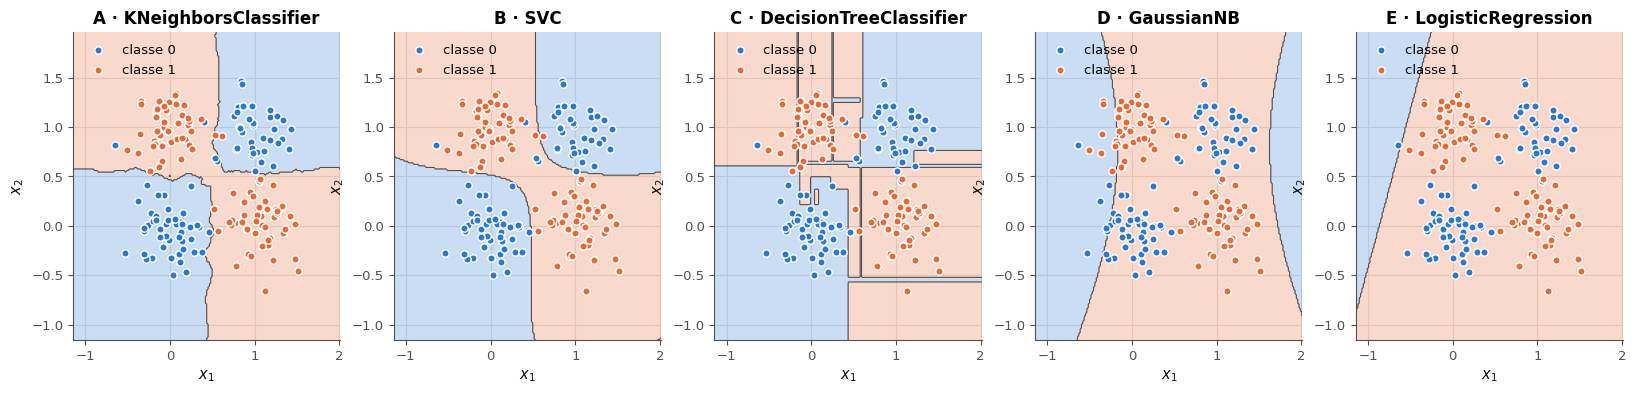

✅ Ex 13.12a : Bien joué !
✅ Ex 13.12b : C'est ça !
✅ Ex 13.12c : Parfait !


In [30]:
if any(answer is ... or answer is None for answer in [chance_12, leaves_12, tree_beats_knn_12]):
    print("⏳ Ex 13.12 : écris d'abord tes trois prédictions, puis relance cette cellule.")
else:
    models_12 = {"A": KNeighborsClassifier(n_neighbors=15), "B": SVC(), "C": DecisionTreeClassifier(random_state=0),
                 "D": GaussianNB(), "E": LogisticRegression()}
    fig, axes = plt.subplots(1, 5, figsize=(20, 4))
    for ax, (letter, model) in zip(axes, models_12.items()):
        model.fit(X_TRAIN_12, Y_TRAIN_12)
        leaves = f" · {model.get_n_leaves()} leaves" if letter == "C" else ""
        print(f"{letter} {type(model).__name__:24s} training {model.score(X_TRAIN_12, Y_TRAIN_12):.3f} · "
              f"test {model.score(X_TEST_12, Y_TEST_12):.3f}{leaves}")
        wb.plot.plot_decision_boundary(model, X_TEST_12, Y_TEST_12, ax=ax, title=f"{letter} · {type(model).__name__}")
    plt.show()
    wb.check("13.12a", chance_12)
    wb.check("13.12b", leaves_12)
    wb.check("13.12c", tree_beats_knn_12)

Dans tes notes : compare avec tes prédictions. Pour chaque classifieur dont l'accuracy t'a surpris, cherche ce qu'il sait représenter et ce qu'il ne sait pas. Où l'arbre place-t-il ses premières questions (`export_text`) ? Explique son nombre de feuilles.

💡 Naïve Bayes gaussien et la régression logistique restent près du hasard (environ 0,51 et 0,53 en test) : une droite ne sépare pas les quatre coins, et, pour Naïve Bayes, les deux classes ont la **même** moyenne (0,5) et à peu près la même variance sur chaque coordonnée : prises une par une, les coordonnées ne disent rien de la classe ; seule leur **combinaison** compte, et l'hypothèse naïve l'ignore. Le kNN et le SVM RBF atteignent 0,96 ; l'arbre sans limite, parfait sur l'entraînement, fait 0,92 en test avec 29 feuilles. Sur un « ou exclusif », aucune question seule autour de 0,5 ne fait baisser l'impureté : l'arbre glouton commence par une coupe presque sans gain au bord du nuage ($x_1 \le -0{,}14$, gain 0,004), puis coupe $x_2$ vers 0,6 ; deux questions autour de 0,5 suffiraient, mais la recherche gloutonne ne les trouve pas, et les points bruités proches du centre ajoutent leurs petits rectangles. Avec d'autres graines (1, 2 et 3, pour les données et pour le découpage), les mêmes conclusions tiennent : Naïve Bayes et la régression logistique de 0,46 à 0,63, l'arbre de 24 à 28 feuilles, et toujours derrière le kNN.

### Ex 13.13 — Choisir k : de la frontière en dents de scie à l'érosion 🔬 ★★ ⏱️ 30 min
**Objectif :** choisir $k$ par validation croisée, et voir ce qu'un grand $k$ efface.  
**Prérequis :** Ex 13.12 · ch. 8 (validation croisée) · fiche §13.3 · **Fil rouge :** synth · **Parcours :** R, C

`X_13` : 600 points de deux demi-lunes bruitées, plus une petite **île** de 15 points de la classe 1 autour de `ISLAND_13` = (−0,2 ; 1,0), au milieu de la lune du haut (classe 0). Avec le `KNeighborsClassifier` de scikit-learn (ta classe arrive en 13.14), calcule :
a) `train_k1_13` : l'accuracy d'un kNN à $k = 1$ entraîné sur `X_13` et mesurée sur ces **mêmes** points ;
b) `cv_13` : la liste des accuracies moyennes en validation croisée à 5 folds (`CV_13`), une par $k$ de `KS_13` ;
c) `best_k_13` : le $k$ de `KS_13` qui a la meilleure accuracy en b) ;
d) `erased_13` : le plus petit $k$ de `KS_13` pour lequel un kNN entraîné sur tous les points prédit la classe 0 en `ISLAND_13` (l'île a disparu).

La vérification contrôle a) à d), puis trace les frontières pour $k$ = 1, 15 et 101, l'île entourée.

Dans tes notes : pourquoi a) ne dit-il rien de la qualité du modèle ? L'île est-elle un vrai phénomène ou du bruit, et la validation croisée peut-elle le dire ? Que gagne-t-on, et que perd-on, en passant de $k = 1$ à $k = 101$ ?

In [31]:
X_MOONS_13, Y_MOONS_13 = wb.synth.make_moons(n=600, noise=0.25, seed=1313)
ISLAND_13 = np.array([-0.2, 1.0])                  # the centre of a small region of class 1 in the upper moon (class 0)
island_points_13 = np.random.default_rng(1313).normal(ISLAND_13, 0.08, (15, 2))
X_13 = np.vstack([X_MOONS_13, island_points_13])   # 615 points
Y_13 = np.concatenate([Y_MOONS_13, np.ones(15, dtype=int)])
KS_13 = [1, 3, 5, 9, 15, 25, 41, 61, 101, 151]
CV_13 = StratifiedKFold(n_splits=5, shuffle=True, random_state=1313)

13.13a: 1.0
13.13b: [0.8894, 0.9073, 0.9138, 0.9252, 0.9203, 0.9203, 0.9171, 0.9171, 0.9106, 0.8894]
13.13c: 9
13.13d: 41


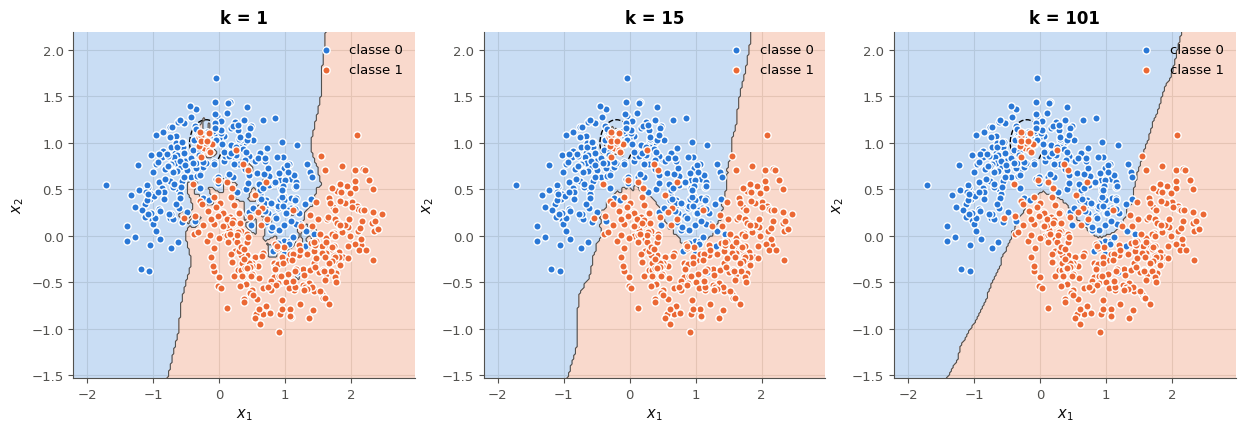

In [32]:
train_k1_13 = KNeighborsClassifier(n_neighbors=1).fit(X_13, Y_13).score(X_13, Y_13)
cv_13 = [cross_val_score(KNeighborsClassifier(n_neighbors=k), X_13, Y_13, cv=CV_13).mean() for k in KS_13]
best_k_13 = KS_13[int(np.argmax(cv_13))]
erased_13 = next(k for k in KS_13 if KNeighborsClassifier(n_neighbors=k).fit(X_13, Y_13).predict([ISLAND_13])[0] == 0)
print_answer("13.13a", train_k1_13)
print_answer("13.13b", cv_13)
print_answer("13.13c", best_k_13)
print_answer("13.13d", erased_13)
if True:
    if not filled(cv_13, erased_13):
        raise NotImplementedError("cv_13, erased_13")
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
    for ax, k in zip(axes, [1, 15, 101]):
        model = KNeighborsClassifier(n_neighbors=k).fit(X_13, Y_13)
        wb.plot.plot_decision_boundary(model, X_13, Y_13, ax=ax, title=f"k = {k}")
        ax.add_patch(plt.Circle(ISLAND_13, 0.25, fill=False, color="black", ls="--"))
    plt.show()

In [33]:
wb.record("13.13a", train_k1_13, decimals=4,
          mistakes={"c'est une accuracy de validation croisée : la question la mesure sur les points mêmes qui ont servi au fit": cv_13[0]})
train_curve_13 = [KNeighborsClassifier(n_neighbors=k).fit(X_13, Y_13).score(X_13, Y_13) for k in KS_13]
wb.record("13.13b", cv_13, decimals=4,
          mistakes={"ce sont les accuracies sur les points d'entraînement : chaque point y est son propre voisin ; utilise cross_val_score avec CV_13": train_curve_13})
others_13c = {f"k = {k} n'a pas la meilleure accuracy moyenne de b) : rends le k de la plus grande valeur de cv_13": k
              for k in KS_13 if k not in (1, best_k_13, int(np.argmax(cv_13)))}
wb.record("13.13c", best_k_13, choices=KS_13,
          fractional="un nombre non entier : est-ce une accuracy ? on demande la valeur de k, un élément de KS_13",
          mistakes={"sur l'entraînement, k = 1 gagne toujours : choisis k sur la validation croisée": 1,
                    "est-ce la position de k dans KS_13 ? rends le k lui-même, celui de la plus grande accuracy moyenne de b)": int(np.argmax(cv_13)),
                    **others_13c})
island_13 = [int(KNeighborsClassifier(n_neighbors=k).fit(X_13, Y_13).predict([ISLAND_13])[0]) for k in KS_13]
others_13d = {f"k = {k} : est-ce le PREMIER k de KS_13 dont la prédiction en ISLAND_13 vaut 0 ? parcours KS_13 dans l'ordre": k
              for k in KS_13 if k not in (KS_13[0], erased_13, KS_13[KS_13.index(erased_13) - 1])}
wb.record("13.13d", erased_13, choices=KS_13,
          fractional="un nombre non entier : on demande la valeur de k, un élément de KS_13",
          mistakes={"c'est le dernier k qui prédit encore la classe 1 sur l'île : on demande le premier qui prédit la classe 0": KS_13[KS_13.index(erased_13) - 1],
                    "relis la question : le premier k qui prédit la classe 0 en ISLAND_13 (la classe de la lune autour)": KS_13[0],
                    **others_13d})

WB_ANSWER {"decimals": 4, "hash": "0e032a218260ab3e312707ad249edd2423385da4b074abd3af5bb5092b040361", "hash_coarse": "8cfed0303d8a35bf0359001c8ac26f06f0cc7b35a07f95db7bc18f26e71da915", "id": "13.13a", "kind": "float", "magnitude": 0, "mistakes": {"9624aa5cb7c5c19a33550b58bf7742950fa6f7b20d76eed07ab6ee6350048671": "c'est une accuracy de validation croisée : la question la mesure sur les points mêmes qui ont servi au fit"}, "sign": 1}
📝 Ex 13.13a : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"decimals": 4, "element_coarse": [["5695160e49f4c5ec07931a92d70cb0b720b05d5fac22e6da7a9b28086719f0d2"], ["b571c01634ce768f8c7a271e66ee19bd6c54de86de44447283ceb048b033777c"], ["290b563c7cc0a6bfb312f7b0bdddd711f34dc4f8a70bd09609d6c558b12fd106"], ["f7423680e339aba04eb3bce63810065f4c9e60ea0460a0e189d85065bb814b6d"], ["53b844accff28107e2fead10872a824a48945c445fc71a65f202e8860ac6d234"], ["ce62473c9e2aaac55195a00500a42082128a0d2d204d74a8c2b0490593c710ce"], ["24cd8ee1a46784346f2b40aa99709aafb413bb

💡 À $k = 1$, chaque point d'entraînement est son propre plus proche voisin : l'accuracy sur l'entraînement vaut 1 par construction et ne mesure rien (annexe des erreurs fréquentes). En validation croisée, $k = 1$ ne fait que 0,889 : la frontière en dents de scie suit le bruit. L'accuracy monte jusqu'à $k = 9$ (0,925), reste presque plate jusqu'à 25, puis redescend (0,889 à $k = 151$). L'île tient tant que ses 15 points dominent le vote : jusqu'à $k = 25$ ; dès 41 voisins, la lune autour l'emporte, et l'île disparaît. La validation croisée ne dit pas si l'île est un vrai phénomène : 15 points sur 615 pèsent peu dans l'accuracy moyenne, et les $k$ de 9 à 25 la gardent avec des scores très proches de ceux qui l'effacent. Seule une connaissance du domaine (ou plus de données dans cette zone) tranche.

### Ex 13.14 — Coder pairwise_distances et KNeighborsClassifier 🔨 ★★★ ⏱️ 45 min
**Objectif :** écrire un kNN en force brute, vectorisé, qui donne exactement les votes de scikit-learn.  
**Prérequis :** ✏️ 13.1 · ch. 12 (standardisation) · 0A (classes Python) · fiche §13.3 · **Fil rouge :** Penguins · **mylearn :** `neighbors.py` · **Parcours :** R, C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/neighbors.py` (créé par `python tools/start_chapter.py 13`), lis la docstring de chaque fonction et de chaque méthode, remplace les `raise NotImplementedError(...)` par ton code et **enregistre**. NumPy seulement : scikit-learn et SciPy sont les **oracles** des tests. La cellule de vérification recharge ta librairie, compare quelques résultats à scikit-learn, puis lance les tests de l'exercice ; `python -m pytest tests/test_ch13_neighbors.py -q` les lance tous dans un terminal.

Écris `pairwise_distances` et la classe `KNeighborsClassifier` de `neighbors.py`. **Contrat** (les docstrings, plus ces précisions que vérifient les tests) :
- `pairwise_distances(A, B, metric="euclidean")` reçoit deux tableaux 2-D (ou des listes) de mêmes nombres de colonnes et rend la matrice `float64` de forme `(len(A), len(B))` des distances `"euclidean"` ou `"manhattan"`, **sans boucle Python sur les exemples** ; calcule la **différence** de chaque paire (l'identité $\lVert\mathbf{a}\rVert^2 - 2\,\mathbf{a}\cdot\mathbf{b} + \lVert\mathbf{b}\rVert^2$, plus rapide, que mesure 🛠️ 13.34, perd en précision : un point n'y est plus exactement à distance 0 de lui-même, ce que les tests vérifient) ; elle ne modifie pas ses arguments ; `ValueError` si `A` ou `B` n'est pas 2-D, si leurs nombres de colonnes diffèrent, si la métrique est inconnue ou si une valeur est `NaN` (comme scikit-learn) ;
- `__init__(n_neighbors=5, weights="uniform", metric="euclidean")` range ses trois arguments tels quels, sans rien vérifier ni calculer ;
- `fit(X, y)` vérifie, puis **range des copies** de `X` et `y` dans des attributs dont le nom finit par `_` (ou commence par `_`), avec `classes_` (les labels distincts triés), `n_features_in_` et `n_samples_fit_`, et renvoie `self` ; un second `fit` oublie le premier ; `ValueError` si `n_neighbors < 1` ou `n_neighbors > len(X)` (dès `fit`), si `weights` ou `metric` est inconnu, si `X` n'est pas 2-D ou contient `NaN`, ou si `len(X) != len(y)` ;
- `kneighbors(X, n_neighbors=None, return_distance=True)` rend `(dist, ind)` (ou `ind` seul), de forme `(len(X), k)`, du plus proche au plus lointain ; à distances égales, le plus petit indice d'entraînement d'abord (un tri **stable**) ; `RuntimeError` avant `fit` ; `ValueError` pour une requête qui n'est pas 2-D (une seule requête s'écrit `X[None, :]`), un mauvais nombre de colonnes, une valeur `NaN`, ou un $k$ hors de 1 à `n_samples_fit_` ;
- `predict_proba(X)` rend la part (pondérée) des votes de chaque classe, colonne $j$ pour `classes_[j]` ; avec `weights="distance"`, un voisin à distance $d$ pèse $1/d$, et des voisins à distance 0 se partagent tout le poids ; `predict(X)` rend la classe de plus grande part (à égalité, la première de `classes_`) ; `score(X, y)` rend l'accuracy, un `float` Python.

La vérification essaie l'exemple de la docstring, compare tes probabilités et tes prédictions à celles de scikit-learn sur les manchots standardisés (deux réglages), puis lance les tests.

Dans tes notes : que coûte un appel à `predict` sur 100 manchots, en nombre de distances ? Pourquoi un tri stable, et pourquoi scikit-learn conseille-t-il un $k$ impair à deux classes ?

In [34]:
with checked("13.14"):
    D_doc_14 = mylearn.neighbors.pairwise_distances(np.array([[0.0, 0.0], [1.0, 1.0]]), np.array([[3.0, 4.0]]))
    if returned("13.14", "pairwise_distances", D_doc_14):
        print("docstring example:", np.round(np.asarray(D_doc_14, dtype=float), 4).ravel().tolist(), "(expected [5.0, 3.6056])")
with checked("13.14"):
    scaler_14 = StandardScaler().fit(P_TRAIN[MEASURES])
    Z_train_14, Z_test_14 = scaler_14.transform(P_TRAIN[MEASURES]), scaler_14.transform(P_TEST[MEASURES])
    y_train_14, y_test_14 = P_TRAIN["species"].to_numpy(), P_TEST["species"].to_numpy()
    for k, weights, metric in [(5, "uniform", "euclidean"), (6, "distance", "manhattan")]:
        setting_14 = f"k = {k}, {weights}, {metric}"
        mine_14 = fitted(mylearn.neighbors.KNeighborsClassifier(n_neighbors=k, weights=weights, metric=metric),
                         Z_train_14, y_train_14)
        oracle_14 = KNeighborsClassifier(n_neighbors=k, weights=weights, metric=metric, algorithm="brute")
        oracle_14.fit(Z_train_14, y_train_14)
        proba_14 = mine_14.predict_proba(Z_test_14)
        if not returned("13.14", "predict_proba", proba_14):
            continue
        predicted_14 = mine_14.predict(Z_test_14)
        if not returned("13.14", "predict", predicted_14):
            continue
        proba_14, predicted_14 = np.asarray(proba_14), np.asarray(predicted_14)
        if proba_14.shape != (len(Z_test_14), 3):
            print(f"❌ Ex 13.14 : {setting_14} : predict_proba devrait rendre un tableau (100, 3), une colonne par "
                  f"espèce de classes_, pas un tableau de forme {proba_14.shape}.")
        elif not np.allclose(proba_14, oracle_14.predict_proba(Z_test_14)):
            print(f"❌ Ex 13.14 : {setting_14} : tes probabilités diffèrent de celles de scikit-learn ; les tests "
                  "ci-dessous disent où.")
        elif not np.array_equal(predicted_14, oracle_14.predict(Z_test_14)):
            print(f"❌ Ex 13.14 : {setting_14} : tes probabilités sont justes, mais predict rend autre chose que les "
                  f"labels de scikit-learn (par exemple {predicted_14[:3].tolist()} au lieu de "
                  f"{oracle_14.predict(Z_test_14)[:3].tolist()}).")
        else:
            print(f"✅ Ex 13.14 : {setting_14} : mêmes probabilités et mêmes prédictions que scikit-learn sur les 100 "
                  f"manchots de test (accuracy {fr(oracle_14.score(Z_test_14, y_test_14))}).")
if written(lambda: mylearn.neighbors.pairwise_distances([[0.0]], [[1.0]])):
    run_mylearn_tests(impl="ref", module="neighbors", keyword="test_pairwise_distances_ or test_kneighbors_classifier_")
else:
    print("⏳ Ex 13.14 : les tests attendent ton pairwise_distances.")

docstring example: [5.0, 3.6056] (expected [5.0, 3.6056])
✅ Ex 13.14 : k = 5, uniform, euclidean : mêmes probabilités et mêmes prédictions que scikit-learn sur les 100 manchots de test (accuracy 0,980).
✅ Ex 13.14 : k = 6, distance, manhattan : mêmes probabilités et mêmes prédictions que scikit-learn sur les 100 manchots de test (accuracy 0,980).


pytest: 76 passed in 0.88s


💡 Une prédiction calcule les distances de chaque manchot de test aux 233 manchots d'entraînement : 23 300 distances de 4 coordonnées pour 100 manchots, et rien n'a été calculé pendant `fit`. Le tri stable rend le résultat indépendant de l'algorithme de tri, et le même que celui de scikit-learn en force brute ; à deux classes, un $k$ impair évite les votes à égalité (avec des poids uniformes).

### Ex 13.15 — kNN et malédiction de la dimension 🔬 ★★★ ⏱️ 35 min
**Objectif :** mesurer comment des features inutiles noient les distances d'un kNN, et pourquoi.  
**Prérequis :** Ex 13.14 · ch. 7 (malédiction de la dimension) · ch. 12 (standardisation) · fiche §13.3 · **Fil rouge :** Penguins · **Parcours :** C

Deux expériences avec **ta** librairie (`mylearn.neighbors` ; si 13.14 n'est pas fait, la référence prend le relais). Écris :
- `noisy_accuracy_15(n_noise, seed)` : l'accuracy de test de ton `KNeighborsClassifier(n_neighbors=5)` entraîné sur les 4 mesures standardisées des manchots (`Z_TRAIN_15`) **plus** `n_noise` colonnes de bruit, puis évalué sur `Z_TEST_15` plus `n_noise` colonnes de bruit ; le bruit suit une loi normale standard, tiré par `rng = np.random.default_rng(seed)` en deux appels : `rng.normal(size=(len(Z_TRAIN_15), n_noise))` pour l'entraînement, puis `rng.normal(size=(len(Z_TEST_15), n_noise))` pour le test ;
- `distance_ratio_15(p, seed=1315)` : 500 points tirés uniformément dans le cube $[0, 1]^p$ ; pour chacun des 50 premiers, la distance à son plus proche **autre** point divisée par la distance à son point le plus lointain (ton `pairwise_distances`) ; la fonction rend la moyenne de ces 50 rapports ;
- a) `accuracies_15` : pour chaque nombre de colonnes de `NOISE_15`, la moyenne de `noisy_accuracy_15` sur les 10 graines de `SEEDS_15` ;
- b) `first_below_15` : le plus petit nombre de colonnes de `NOISE_15` dont l'accuracy moyenne passe sous 0,9 ;
- c) `ratios_15` : `distance_ratio_15(p)` pour chaque dimension de `P_15`.

La vérification contrôle a) à c), puis trace les deux courbes.

Dans tes notes : les colonnes de bruit ont la même échelle que les mesures standardisées ; pourquoi finissent-elles par décider des voisins ? Que dit c) sur le sens de « plus proche voisin » en grande dimension ? Que ferais-tu sur de vraies données qui ont beaucoup de features ?

In [35]:
SCALER_15 = StandardScaler().fit(P_TRAIN[MEASURES])
Z_TRAIN_15, Z_TEST_15 = SCALER_15.transform(P_TRAIN[MEASURES]), SCALER_15.transform(P_TEST[MEASURES])
Y_TRAIN_15, Y_TEST_15 = P_TRAIN["species"].to_numpy(), P_TEST["species"].to_numpy()
NOISE_15 = [0, 2, 5, 10, 20, 50, 100, 200]   # numbers of noise columns
SEEDS_15 = range(10)                          # 10 draws of the noise for each number
P_15 = [2, 10, 100, 1000]                     # dimensions of the uniform cube

13.15a: [0.98, 0.972, 0.951, 0.92, 0.873, 0.785, 0.704, 0.608]
13.15b: 20
13.15c: [0.0202, 0.2994, 0.7182, 0.8973]


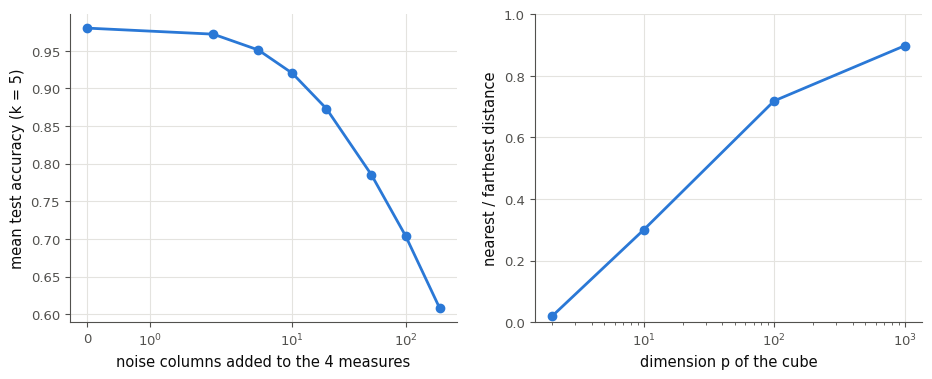

In [36]:
def noisy_accuracy_15(n_noise, seed):
    """Test accuracy of YOUR mylearn.neighbors.KNeighborsClassifier(n_neighbors=5), fitted on the 4 standardized
    measures Z_TRAIN_15 plus n_noise columns of noise, then scored on Z_TEST_15 plus n_noise columns of noise. The noise
    is standard normal, drawn with rng = np.random.default_rng(seed) in two calls: rng.normal(size=(len(Z_TRAIN_15),
    n_noise)) for the training part, then rng.normal(size=(len(Z_TEST_15), n_noise)) for the test part."""
    rng = np.random.default_rng(seed)
    train = np.hstack([Z_TRAIN_15, rng.normal(size=(len(Z_TRAIN_15), n_noise))])
    test = np.hstack([Z_TEST_15, rng.normal(size=(len(Z_TEST_15), n_noise))])
    model = mylearn.neighbors.KNeighborsClassifier(n_neighbors=5)
    model.fit(train, Y_TRAIN_15)
    return model.score(test, Y_TEST_15)


def distance_ratio_15(p, seed=1315):
    """Draw 500 points uniformly in [0, 1]^p (np.random.default_rng(seed).uniform(size=(500, p))). For each of the
    first 50, the distance to its nearest OTHER point divided by the distance to its farthest point (YOUR
    mylearn.neighbors.pairwise_distances); return the mean of these 50 ratios."""
    points = np.random.default_rng(seed).uniform(size=(500, p))
    D = mylearn.neighbors.pairwise_distances(points[:50], points)
    D[np.arange(50), np.arange(50)] = np.inf          # a point is not its own neighbour
    nearest = D.min(axis=1)
    D[np.arange(50), np.arange(50)] = 0.0
    return float(np.mean(nearest / D.max(axis=1)))


accuracies_15 = [float(np.mean([noisy_accuracy_15(n, seed) for seed in SEEDS_15])) for n in NOISE_15]
first_below_15 = next(n for n, accuracy in zip(NOISE_15, accuracies_15) if accuracy < 0.9)
ratios_15 = [distance_ratio_15(p) for p in P_15]
print_answer("13.15a", accuracies_15)
print_answer("13.15b", first_below_15)
print_answer("13.15c", ratios_15)
if True:
    if not filled(accuracies_15, ratios_15):
        raise NotImplementedError("accuracies_15, ratios_15")
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(NOISE_15, accuracies_15, marker="o")
    axes[0].set_xscale("symlog", linthresh=2)
    axes[0].set_xlabel("noise columns added to the 4 measures")
    axes[0].set_ylabel("mean test accuracy (k = 5)")
    axes[1].plot(P_15, ratios_15, marker="o")
    axes[1].set_xscale("log")
    axes[1].set_ylim(0, 1)
    axes[1].set_xlabel("dimension p of the cube")
    axes[1].set_ylabel("nearest / farthest distance")
    plt.show()

In [37]:
def transposed_accuracy_15(n_noise, seed):        # the noise drawn as (n_noise, rows), then transposed
    rng = np.random.default_rng(seed)
    train = np.hstack([Z_TRAIN_15, rng.normal(size=(n_noise, len(Z_TRAIN_15))).T])
    test = np.hstack([Z_TEST_15, rng.normal(size=(n_noise, len(Z_TEST_15))).T])
    return KNeighborsClassifier(n_neighbors=5).fit(train, Y_TRAIN_15).score(test, Y_TEST_15)


wb.record("13.15a", accuracies_15, decimals=4,
          mistakes={"le bruit n'est pas tiré dans la forme de l'énoncé : un appel rng.normal(size=(lignes, n_noise)) pour l'entraînement, puis un pour le test": [float(np.mean([transposed_accuracy_15(n, seed) for seed in SEEDS_15])) for n in NOISE_15]})
wb.record("13.15b", first_below_15, choices=NOISE_15,
          fractional="un nombre non entier : est-ce une accuracy ? on demande un nombre de colonnes de NOISE_15",
          mistakes={"c'est le dernier nombre de colonnes dont l'accuracy reste au-dessus de 0,9 : on demande le premier en dessous": NOISE_15[NOISE_15.index(first_below_15) - 1]})
wb.record("13.15c", ratios_15, decimals=4,
          mistakes={"des rapports nuls : chaque point est à distance 0 de lui-même ; exclus-le avant de chercher le plus proche": [0.0, 0.0, 0.0, 0.0]})

WB_ANSWER {"decimals": 4, "element_coarse": [["377139992f9d65d2f1728b1c06f5edea428955bb282217c940a1a3d6624c6796"], ["db7250a2b8327e213edc000df50b39b85a9b6e9dc5579511b7719b5ad3a45ca8"], ["002e374346052ff665cd927e7fe7b42338d3ee89985575a71927cb500bea4a4b"], ["8e1259715ab20fffd389c0105e2b43ae8a51002eb9684e6e2f7a9ddbd43c6e07"], ["6ed749efe91a964145c9c7747c6c99a466f30d9dd9c7b941b3884c634b99e0e1"], ["17a5f7262e7635d35c2742a24dd2c8bbe74e2fc8887c7818afd2ba8ca9f6e2cb"], ["6d581bbe06c197a2de83d5cbcad18c17f0681d3859214be56699f05ecf565289"], ["caa11a3dd6bab5e4784da83ab92c1a73322194647255e8f89215cd467572291e"]], "element_hashes": ["898b3010d9c2ae0dcfcf06e549fec8a544820bf3230c2a92776ca5498c252e79", "dc0e0d5731c973f5681305952b8f73cd432f4c059d3c790dfcb3101f7a05f6ea", "d28376a238f7b9c5ed2b43bcb532ff580c2a957c545bd69cd145be0775e57da7", "e07f8c898b22c48f86017f16affb6e652ae32945f9a0aeb571de9b4696737e97", "ba0293525cbe9f26c8d759f35116fa7ab3d0026a2d0879eb7b710f93979915bf", "e8b7f74f83f6a5babc95228b6803dfc7df

💡 Sans bruit, le kNN classe 98 % des manchots de test. Chaque colonne de bruit ajoute à la distance au carré un terme de même ordre que celui d'une mesure (environ 2 en moyenne entre deux points), mais sans aucun rapport avec l'espèce : à 20 colonnes, le bruit pèse cinq fois plus que les mesures, et l'accuracy tombe sous 0,9 ; à 200 colonnes, elle n'est plus qu'à environ 0,6. Dans le cube, le plus proche voisin est 50 fois plus près que le plus lointain en dimension 2, mais seulement 1,1 fois en dimension 1 000 : toutes les distances se ressemblent, et « le plus proche » ne veut presque plus rien dire. Sur de vraies données, on retire les features inutiles (sélection, ch. 12), on réduit la dimension (PCA, 🏆 13.36), ou l'on choisit un modèle qui pondère ses features (régression logistique, arbres).

## Partie B · Les machines à vecteurs de support

Les SVM de scikit-learn (`sklearn.svm.SVC`) : la marge et les vecteurs de support d'un SVM linéaire (13.16), une transformation que tu calcules toi-même pour séparer des cercles par un plan (13.17), puis le noyau RBF réglé par validation croisée (13.18). Le workbook ne te fait pas coder de SVM : l'optimisation de la marge demande des outils (la programmation quadratique) qui dépassent le chapitre. La cellule suivante définit `draw_band`, qui trace la bande d'un SVM en 2D.

In [38]:
def draw_band(ax, model, X, y, title):
    """The points, the boundary f(x) = 0 and the two edges f(x) = ±1 of a 2D SVC, its support vectors circled."""
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 300),
                         np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 300))
    f = model.decision_function(np.column_stack([xx.ravel(), yy.ravel()])).reshape(xx.shape)
    ax.contourf(xx, yy, f > 0, alpha=0.15, cmap="coolwarm")
    ax.contour(xx, yy, f, levels=[-1, 0, 1], colors="black", linestyles=["--", "-", "--"], linewidths=1)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=14, edgecolors="white", linewidths=0.4)
    sv = model.support_vectors_
    ax.scatter(sv[:, 0], sv[:, 1], s=60, facecolors="none", edgecolors="black", linewidths=0.8)
    ax.set_title(title)

### Ex 13.16 — SVM linéaire : vecteurs de support et paramètre C 📦 ★★ ⏱️ 25 min
**Objectif :** lire la marge et les vecteurs de support d'un SVM linéaire, et voir ce que C change.  
**Prérequis :** ✏️ 13.4 · fiche §13.4 · **Fil rouge :** synth · **Parcours :** R, M, C

`X_16` : 200 points de deux classes (0 et 1), deux nuages gaussiens qui se chevauchent un peu. On entraîne `SVC(kernel="linear", C=C)` pour les trois valeurs de `CS_16` ; sa fonction de décision est $f(\mathbf{x}) = \mathbf{w} \cdot \mathbf{x} + b$, et la bande est l'ensemble des points où $-1 < f(\mathbf{x}) < 1$. Calcule :
a) `n_support_16` : la liste des nombres totaux de vecteurs de support, un par valeur de `CS_16` (dans cet ordre) ;
b) `width_16` : pour $C = 1$, la largeur de la bande, la distance entre les droites $f(\mathbf{x}) = -1$ et $f(\mathbf{x}) = 1$ ;
c) `inside_16` : pour $C = 1$, le nombre de points tels que $y_i f(\mathbf{x}_i) < 0{,}999$, avec $y_i = -1$ pour la classe 0 et $+1$ pour la classe 1 (les points dans la bande ou du mauvais côté ; le seuil 0,999 tolère l'arrondi des points posés sur un bord).

La vérification contrôle a) à c), puis trace les trois bandes, vecteurs de support entourés.

Dans tes notes : comment la largeur de la bande et le nombre de vecteurs de support varient-ils avec C, et pourquoi ? Réentraîne le SVM ($C = 1$) sur ses seuls vecteurs de support : que deviennent $\mathbf{w}$ et $b$, et qu'est-ce que cela dit de ce que le SVM « retient » des données ?

In [39]:
X_16, Y_16 = wb.synth.make_blobs(n=200, centers=[[0.0, 0.0], [2.5, 2.0]], std=0.9, seed=1316)   # two classes, 0 and 1
CS_16 = [0.01, 1, 100]

w, b on the 200 points: [1.5088 0.8703] -2.5673 · on the 18 support vectors only: [1.5088 0.8703] -2.5673
13.16a: [86.0, 18.0, 14.0]
13.16b: 1.1482348370069486
13.16c: 16


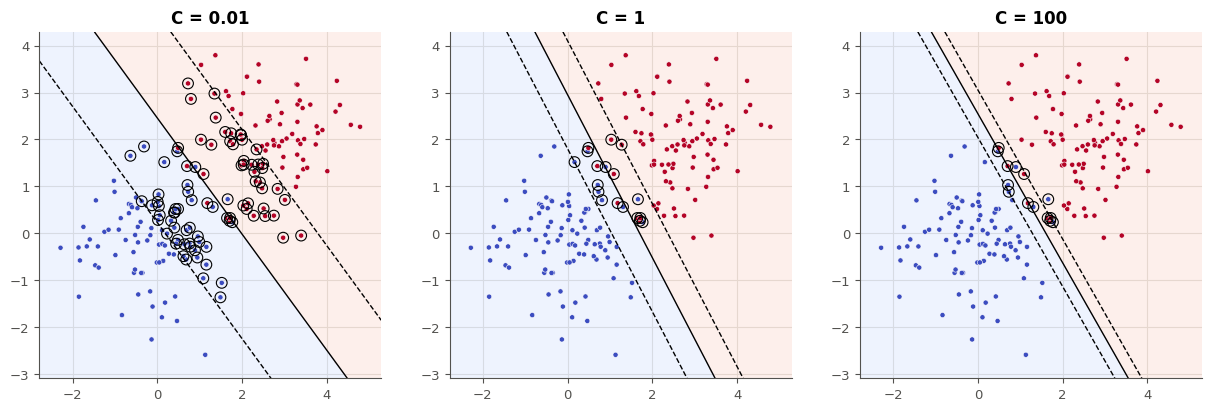

In [40]:
models_16 = {C: SVC(kernel="linear", C=C).fit(X_16, Y_16) for C in CS_16}
n_support_16 = [int(models_16[C].n_support_.sum()) for C in CS_16]
w_16, b_16 = models_16[1].coef_[0], models_16[1].intercept_[0]
width_16 = 2 / np.linalg.norm(w_16)
signs_16 = np.where(Y_16 == 1, 1, -1)
inside_16 = int(np.sum(signs_16 * models_16[1].decision_function(X_16) < 0.999))
# The support vectors alone give the same hyperplane:
sv_16 = models_16[1].support_
again_16 = SVC(kernel="linear", C=1).fit(X_16[sv_16], Y_16[sv_16])
print("w, b on the 200 points:", np.round(w_16, 4), round(b_16, 4), "· on the", len(sv_16), "support vectors only:",
      np.round(again_16.coef_[0], 4), round(again_16.intercept_[0], 4))
print_answer("13.16a", n_support_16)
print_answer("13.16b", width_16)
print_answer("13.16c", inside_16)
if True:
    if not filled(n_support_16, width_16, inside_16):
        raise NotImplementedError("n_support_16, width_16, inside_16")
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
    for ax, C in zip(axes, CS_16):
        model = SVC(kernel="linear", C=C).fit(X_16, Y_16)
        draw_band(ax, model, X_16, Y_16, f"C = {C}")
    plt.show()

In [41]:
wb.record("13.16a", n_support_16,
          mistakes={"les nombres sont dans l'ordre de CS_16 : C = 0,01, puis 1, puis 100": n_support_16[::-1]})
wb.record("13.16b", width_16, decimals=4,
          mistakes={"c'est la demi-largeur, la distance de la frontière à un bord : la bande va de f = -1 à f = +1": width_16 / 2,
                    "c'est la norme de w : la distance d'un point à la droite f = 0 vaut |f| / ||w||": float(np.linalg.norm(w_16))})
wb.record("13.16c", inside_16,
          mistakes={"ce sont tous les vecteurs de support : ceux qui sont posés sur un bord ont y f(x) = 1, ils ne sont pas dans la bande": int(len(sv_16)),
                    "ce sont les points mal classés (y f(x) < 0) : compte aussi les points bien classés qui sont dans la bande": int(np.sum(signs_16 * models_16[1].decision_function(X_16) < 0)),
                    "un point posé sur un bord a y f(x) = 0,9999997, à l'arrondi près : utilise le seuil 0,999 de l'énoncé": int(np.sum(signs_16 * models_16[1].decision_function(X_16) < 1))})

WB_ANSWER {"decimals": 0, "element_hashes": ["e470440b5de275f675fed76bce48b71e49ac27e15c6e0e04ee40b06d74cd9c0d", "c0f86c43383be1b3469cfd687a950b964bcf1a82fbc4b2c33eb0af7ba3bfdb96", "811e6c4ffa1b599e867e03d084575537530c3afc9d37f2d99ad43c588379bae9"], "hash": "e679c2f602db64d26d1c90ffc7af003dc4ddd21fb49f596f616c5aad2a7b9a44", "id": "13.16a", "integer": true, "kind": "array", "mistakes": {"9cab2cd8419f21c8356ef30b9e778bc5101c877adda65b04f84b98181d600a28": "les nombres sont dans l'ordre de CS_16 : C = 0,01, puis 1, puis 100"}, "shape": [3]}
📝 Ex 13.16a : réponse enregistrée (array, 0 décimale(s)).
WB_ANSWER {"decimals": 4, "hash": "178bdf564723f6e9b1e2f818f6c8dd5e2399e949ac5ea623d2cce5536820fe3e", "hash_coarse": "0b7188717937079e9917e8a3c9efcb6848b7a4fe97ea4eb4dc21b15dea4bdded", "id": "13.16b", "kind": "float", "magnitude": 0, "mistakes": {"3278c793b824c766a71da8f709dcd647accb8daed8d5ab235ff40f7324dfd5a9": "c'est la norme de w : la distance d'un point à la droite f = 0 vaut |f| / ||w||", "

💡 Petit C (0,01) : les violations coûtent peu, la bande s'élargit (2,80) et contient 84 points, tous vecteurs de support (86). Grand C (100) : les violations coûtent cher, la bande se resserre (0,54) et il ne reste que 14 vecteurs de support. À $C = 1$, la bande mesure 1,148 ; 16 points sont dedans ou du mauvais côté, dont 6 mal classés, et 2 vecteurs de support sont posés exactement sur un bord : 18 en tout. Réentraîné sur ces 18 points seulement, le SVM retrouve le même $\mathbf{w}$ et le même $b$ (à $10^{-7}$ près) : les 182 autres points, hors de la bande et du bon côté, ne comptent pas pour l'hyperplan.

### Ex 13.17 — Relever les cercles en 3D pour les séparer par un plan 🎨 ★★ ⏱️ 30 min
**Objectif :** voir qu'une transformation des features rend linéaire ce qui ne l'était pas, et le dessiner.  
**Prérequis :** Ex 13.16 · ✏️ 13.5 · fiche §13.4 (astuce du noyau) · **Fil rouge :** synth · **Parcours :** M, C

`X_17` : un anneau (classe 0) autour d'un disque (classe 1), deux cercles bruités de rayons 1 et 0,4 ; 70 % pour l'entraînement, 30 % pour le test. Aucune droite ne les sépare ; on les **relève** en ajoutant une troisième coordonnée, $x_3 = x_1^2 + x_2^2$, le carré de la distance au centre. Écris :
- `lift_17(X)` : le tableau `(n, 3)` des deux coordonnées, puis de $x_1^2 + x_2^2$ ;
- `draw_17(ax, X3, y, model)` : sur un axe 3D, les points relevés colorés par classe, et le plan $\mathbf{w} \cdot \mathbf{z} + b = 0$ du SVM linéaire `model` (résous-le en $z_3$ sur une grille de $(z_1, z_2)$, et trace-le avec `ax.plot_surface`) ;
- a) `acc_2d_17` : l'accuracy de test de `SVC(kernel="linear", C=1)` entraîné sur les deux coordonnées ;
- b) `acc_3d_17` : la même chose sur les trois coordonnées relevées ;
- c) `radius_17` : la frontière de b), revenue dans le plan des données, est un cercle : son rayon (garde tous les chiffres).

La vérification contrôle a) à c), essaie `lift_17` sur deux points, puis dessine la frontière vue de dessus et ta figure 3D.

Dans tes notes : pourquoi le rayon trouvé tombe-t-il entre 0,4 et 1 ? Écris le produit scalaire $\varphi(\mathbf{x}) \cdot \varphi(\mathbf{z})$ de ta transformation en fonction de $\mathbf{x}$ et $\mathbf{z}$ seulement : quel noyau as-tu, sans le savoir, utilisé ? Qu'aurait fait un noyau RBF sur ces données ?

In [42]:
X_17, Y_17 = wb.synth.make_circles(n=400, noise=0.1, factor=0.4, seed=1317)   # a ring (class 0) around a disc (class 1)
X_TRAIN_17, X_TEST_17, Y_TRAIN_17, Y_TEST_17 = train_test_split(X_17, Y_17, test_size=0.3, random_state=1317,
                                                                stratify=Y_17)

w = [ 0.0107 -0.046  -4.1329] · b = 2.1318 · the simple formula sqrt(-b / w3): 0.7182
13.17a: 0.6083333333333333
13.17b: 0.9833333333333333
13.17c: 0.7182107285943843
✅ Ex 13.17 : lift_17 ajoute bien x1² + x2² en troisième colonne.


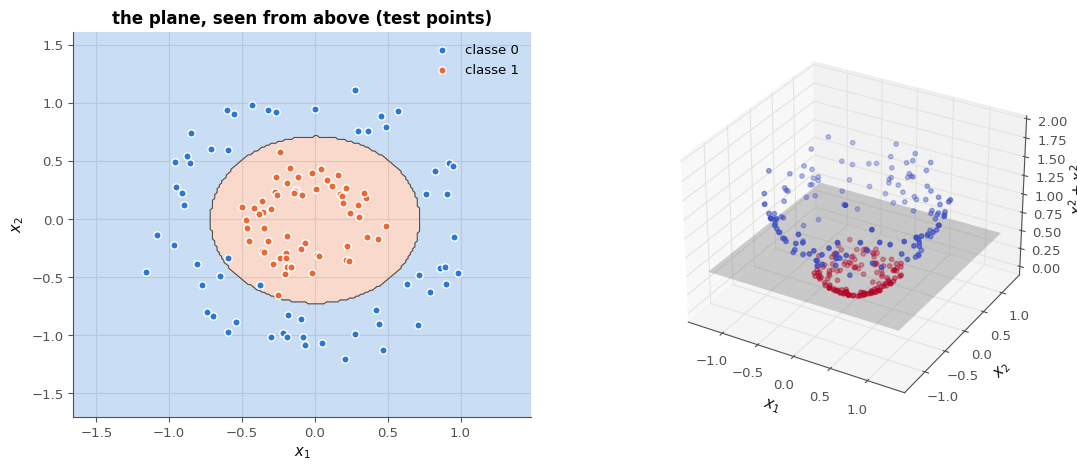

In [43]:
def lift_17(X):
    """(n, 2) -> (n, 3): the two coordinates, then x1**2 + x2**2."""
    X = np.asarray(X, dtype=float)
    return np.column_stack([X, (X ** 2).sum(axis=1)])


def draw_17(ax, X3, y, model):
    """On the 3D axis `ax`: the lifted points X3 (n, 3) coloured by class y, and the plane w . z + b = 0 of `model`, a
    linear SVC fitted on lifted points (solve the plane for its third coordinate on a grid of (x1, x2))."""
    ax.scatter(X3[:, 0], X3[:, 1], X3[:, 2], c=y, cmap="coolwarm", s=10)
    w, b = model.coef_[0], model.intercept_[0]
    g1, g2 = np.meshgrid(np.linspace(-1.3, 1.3, 20), np.linspace(-1.3, 1.3, 20))
    ax.plot_surface(g1, g2, -(w[0] * g1 + w[1] * g2 + b) / w[2], alpha=0.3, color="gray")
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_zlabel("$x_1^2 + x_2^2$")


acc_2d_17 = SVC(kernel="linear", C=1).fit(X_TRAIN_17, Y_TRAIN_17).score(X_TEST_17, Y_TEST_17)
model_3d_17 = SVC(kernel="linear", C=1).fit(lift_17(X_TRAIN_17), Y_TRAIN_17)
acc_3d_17 = model_3d_17.score(lift_17(X_TEST_17), Y_TEST_17)
w_17, b_17 = model_3d_17.coef_[0], model_3d_17.intercept_[0]
# w1 x1 + w2 x2 + w3 (x1² + x2²) + b = 0 is a circle of centre (-w1 / 2w3, -w2 / 2w3):
radius_17 = float(np.sqrt((w_17[0] ** 2 + w_17[1] ** 2) / (4 * w_17[2] ** 2) - b_17 / w_17[2]))
print("w =", np.round(w_17, 4), "· b =", round(b_17, 4), "· the simple formula sqrt(-b / w3):", round(float(np.sqrt(-b_17 / w_17[2])), 4))
print_answer("13.17a", acc_2d_17)
print_answer("13.17b", acc_3d_17)
print_answer("13.17c", radius_17)
if True:
    probe_17 = lift_17(np.array([[1.0, 2.0], [0.0, -3.0]]))
    if returned("13.17", "lift_17", probe_17):
        verdict("13.17", np.shape(probe_17) == (2, 3) and np.allclose(probe_17, [[1, 2, 5], [0, -3, 9]]),
                "lift_17 ajoute bien x1² + x2² en troisième colonne.",
                f"lift_17([[1, 2], [0, -3]]) rend {np.round(np.asarray(probe_17, dtype=float), 3).tolist()} au lieu de "
                "[[1, 2, 5], [0, -3, 9]] : les deux coordonnées, puis la somme de leurs carrés.")
        model_17 = SVC(kernel="linear", C=1).fit(lift_17(X_TRAIN_17), Y_TRAIN_17)
        fig = plt.figure(figsize=(13, 5))
        ax_17 = fig.add_subplot(1, 2, 1)
        wb.plot.plot_decision_boundary(lambda points: model_17.predict(lift_17(points)), X_TEST_17, Y_TEST_17,
                                       ax=ax_17, title="the plane, seen from above (test points)")
        draw_17(fig.add_subplot(1, 2, 2, projection="3d"), lift_17(X_TRAIN_17), Y_TRAIN_17, model_17)
        plt.show()

In [44]:
wb.record("13.17a", acc_2d_17, decimals=4,
          mistakes={"c'est l'accuracy d'entraînement : mesure-la sur X_TEST_17": SVC(kernel="linear", C=1).fit(X_TRAIN_17, Y_TRAIN_17).score(X_TRAIN_17, Y_TRAIN_17)})
wb.record("13.17b", acc_3d_17, decimals=4,
          mistakes={"c'est l'accuracy d'entraînement : mesure-la sur lift_17(X_TEST_17)": model_3d_17.score(lift_17(X_TRAIN_17), Y_TRAIN_17)})
wb.record("13.17c", radius_17, decimals=2,
          mistakes={"c'est le carré du rayon : sur le cercle, x1² + x2² = r²": radius_17 ** 2,
                    "c'est le milieu des deux rayons, deviné : calcule-le à partir de w et b": 0.70})

WB_ANSWER {"decimals": 4, "hash": "b83825806512fd2f23a3e8b3206d90b97447e47e8b78247fc6c90b8b8e97cb5c", "hash_coarse": "e5b9888794b9da7ffe9d13e558285a9263a1f16dcfb48e02df50e78a08a37c3d", "id": "13.17a", "kind": "float", "magnitude": -1, "mistakes": {"ebc2ca5456485bdcd4d8eadf2873fbbb50b37aa6e85be750aa42f5152eb6b03d": "c'est l'accuracy d'entraînement : mesure-la sur X_TEST_17"}, "sign": 1}
📝 Ex 13.17a : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"decimals": 4, "hash": "d3e9fa69aeb600b5f62663bc59e0b001259c5720a6847ea7c91ea9313ac40c21", "hash_coarse": "9ddb924f9c547428e65a89788c35c746df4cfc9db5cf41f4f75538042263c3df", "id": "13.17b", "kind": "float", "magnitude": -1, "mistakes": {"718900c79edcc0a7eb86831c54bbba7f31be3606db527155eb8304b92fa8bec9": "c'est l'accuracy d'entraînement : mesure-la sur lift_17(X_TEST_17)"}, "sign": 1}
📝 Ex 13.17b : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"decimals": 2, "hash": "06658d66f58f809c34178f5d40a421d2d03bcdb2556f64f74267ae091f9e29

💡 Sur les deux coordonnées, un SVM linéaire fait 0,61, à peine mieux que la classe majoritaire (0,5) ; relevés, les points se séparent presque tous par un plan (0,983 en test). Le plan a $w_1$ et $w_2$ presque nuls et $w_3 \approx -4{,}13$ : il coupe en $x_3 \approx 0{,}516$, soit un cercle de rayon 0,72, entre le disque (0,4) et l'anneau (1), à peu près au milieu, comme le veut une marge maximale. Le produit scalaire des points relevés vaut $\mathbf{x} \cdot \mathbf{z} + \lVert \mathbf{x} \rVert^2 \lVert \mathbf{z} \rVert^2$ : un noyau calculable sans relever les points, dans l'esprit de ✏️ 13.5. Un noyau RBF aurait trouvé une frontière fermée semblable, sans qu'on choisisse la transformation.

### Ex 13.18 — Noyau RBF : régler C et gamma par validation croisée 📦 ★★★ ⏱️ 35 min
**Objectif :** régler ensemble C et $\gamma$ sur une grille logarithmique, et reconnaître un $\gamma$ trop grand.  
**Prérequis :** Ex 13.16 · ch. 8 (validation croisée, `GridSearchCV`) · fiche §13.4 · **Fil rouge :** synth · **Parcours :** C

`X_18` : deux spirales entrelacées et bruitées (400 points, 70 % pour l'entraînement). Avec `GridSearchCV` et `SVC(kernel="rbf")`, essaie les 25 combinaisons de `GRID_18` en validation croisée à 5 folds (`CV_18`), sur la partie d'entraînement. Calcule :
a) `best_18` : la liste `[C, gamma]` de la meilleure combinaison ;
b) `best_cv_18` : son accuracy moyenne en validation croisée ;
c) `test_18` : l'accuracy de test du modèle réentraîné sur toute la partie d'entraînement avec cette combinaison ;
d) `overfit_18` : la liste `[accuracy d'entraînement, accuracy de test]` de `SVC(C=1000, gamma=1000)` entraîné sur la partie d'entraînement.

La vérification contrôle a) à d), puis trace la carte des accuracies de validation croisée et deux frontières.

Dans tes notes : décris la carte : où sont les bonnes combinaisons ? Que fait un noyau de $\gamma = 1\,000$ autour de chaque vecteur de support, et pourquoi C n'y change presque rien ? Pourquoi la grille est-elle logarithmique ?

In [45]:
X_18, Y_18 = wb.synth.make_spirals(n=400, noise=0.8, seed=1318)   # two intertwined spirals
X_TRAIN_18, X_TEST_18, Y_TRAIN_18, Y_TEST_18 = train_test_split(X_18, Y_18, test_size=0.3, random_state=1318,
                                                                stratify=Y_18)
GRID_18 = {"C": [0.1, 1, 10, 100, 1000], "gamma": [0.1, 1, 10, 100, 1000]}
CV_18 = StratifiedKFold(n_splits=5, shuffle=True, random_state=1318)

13.18a: [1.0, 10.0]
13.18b: 0.9285714285714285
13.18c: 0.95
13.18d: [1.0, 0.8333]


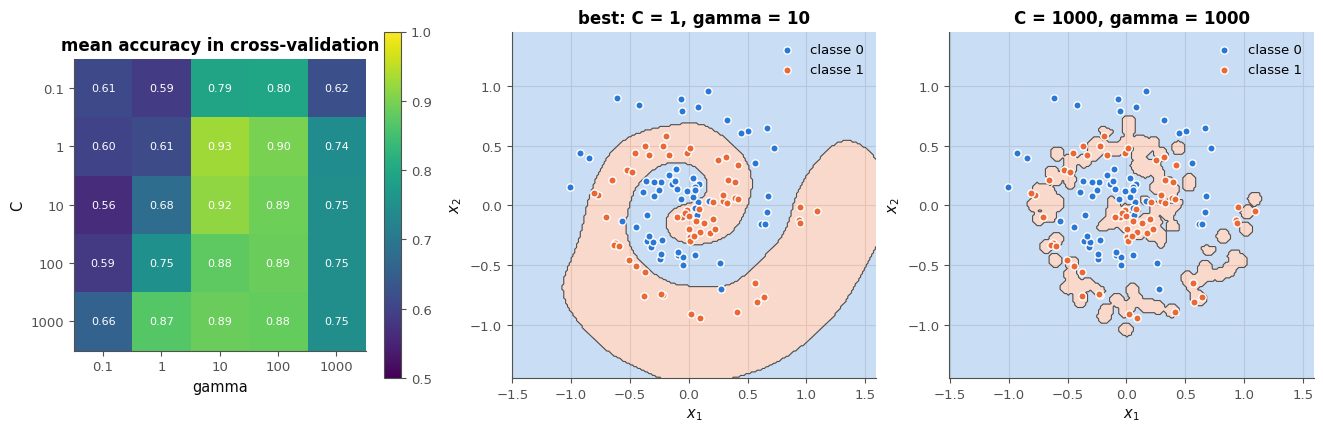

In [46]:
search_18 = GridSearchCV(SVC(kernel="rbf"), GRID_18, cv=CV_18).fit(X_TRAIN_18, Y_TRAIN_18)
best_18 = [search_18.best_params_["C"], search_18.best_params_["gamma"]]
best_cv_18 = search_18.best_score_
test_18 = search_18.score(X_TEST_18, Y_TEST_18)
overfit_model_18 = SVC(C=1000, gamma=1000).fit(X_TRAIN_18, Y_TRAIN_18)
overfit_18 = [overfit_model_18.score(X_TRAIN_18, Y_TRAIN_18), overfit_model_18.score(X_TEST_18, Y_TEST_18)]
print_answer("13.18a", best_18)
print_answer("13.18b", best_cv_18)
print_answer("13.18c", test_18)
print_answer("13.18d", overfit_18)
if True:
    if not filled(search_18) or not hasattr(search_18, "cv_results_"):
        raise NotImplementedError("search_18")
    scores_18 = search_18.cv_results_["mean_test_score"].reshape(len(GRID_18["C"]), len(GRID_18["gamma"]))
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    image = axes[0].imshow(scores_18, cmap="viridis", vmin=0.5, vmax=1)
    axes[0].set_xticks(range(5), GRID_18["gamma"])
    axes[0].set_yticks(range(5), GRID_18["C"])
    axes[0].set_xlabel("gamma")
    axes[0].set_ylabel("C")
    axes[0].set_title("mean accuracy in cross-validation")
    axes[0].grid(False)
    for i in range(5):
        for j in range(5):
            axes[0].text(j, i, f"{scores_18[i, j]:.2f}", ha="center", va="center", color="white", fontsize=8)
    fig.colorbar(image, ax=axes[0])
    wb.plot.plot_decision_boundary(search_18.best_estimator_, X_TEST_18, Y_TEST_18, ax=axes[1],
                                   title=f"best: C = {search_18.best_params_['C']}, gamma = {search_18.best_params_['gamma']}")
    wb.plot.plot_decision_boundary(SVC(C=1000, gamma=1000).fit(X_TRAIN_18, Y_TRAIN_18), X_TEST_18, Y_TEST_18,
                                   ax=axes[2], title="C = 1000, gamma = 1000")
    plt.show()

In [47]:
wb.record("13.18a", best_18, mistakes={"l'ordre demandé est [C, gamma]": best_18[::-1]})
wb.record("13.18b", best_cv_18, decimals=4,
          mistakes={"c'est l'accuracy de test : on demande la moyenne de validation croisée (best_score_)": test_18})
wb.record("13.18c", test_18, decimals=4,
          mistakes={"c'est le SVC par défaut (gamma=\"scale\", C=1) : utilise le modèle réglé par la recherche": SVC().fit(X_TRAIN_18, Y_TRAIN_18).score(X_TEST_18, Y_TEST_18),
                    "c'est la moyenne de validation croisée : on demande l'accuracy sur X_TEST_18": best_cv_18})
wb.record("13.18d", overfit_18, decimals=4,
          mistakes={"l'ordre demandé est [entraînement, test]": overfit_18[::-1]})

WB_ANSWER {"decimals": 0, "element_hashes": ["7af3e6b8d1bf3ce73b7ee6c5294eaeeec1317fc3f42427768df9b129a68f1119", "c85f0042feca19b028b0d00c91c3dddfe3ae68c38f5851af1f86d93443258a61"], "hash": "bdf7c0bfe66b3f9ea8c6303eace3c9bd53d29eb6fe017192c9c7a5b522a55ef5", "id": "13.18a", "integer": true, "kind": "array", "mistakes": {"f45af139d32b6505fe2c730515274383fcce64d493205b66617614112f0b1925": "l'ordre demandé est [C, gamma]"}, "shape": [2]}
📝 Ex 13.18a : réponse enregistrée (array, 0 décimale(s)).
WB_ANSWER {"decimals": 4, "hash": "adc3c74757c8ad78c79c2891d2a07b46178783400c20f219c1a69597af282ff5", "hash_coarse": "0fef2733b1e31c8000a71c0f1b6ba6ab0fc5f809fcdb69400aaa3ea1bf487fcb", "id": "13.18b", "kind": "float", "magnitude": -1, "mistakes": {"d276f18265c01b244b8b1134221e67897d0caef030cc96466c7157f8b4f3f0b3": "c'est l'accuracy de test : on demande la moyenne de validation croisée (best_score_)"}, "sign": 1}
📝 Ex 13.18b : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"decimals": 4, "has

💡 La meilleure combinaison est $C = 1$, $\gamma = 10$ (0,929 en validation croisée, 0,95 en test). La carte montre une bande de bonnes valeurs autour de $\gamma = 10$ à 100, et une compensation entre les deux réglages : un petit $\gamma$ (frontière trop lisse, 0,56 à 0,87) se rattrape en partie par un grand C. Avec $\gamma = 1\,000$, le noyau d'un vecteur de support vaut $e^{-1000 d^2}$ : il tombe à 0,37 dès $d \approx 0{,}03$, si bien que chaque point d'entraînement crée sa petite bosse et que presque tous deviennent vecteurs de support. L'entraînement est parfait (1,0), le test chute à 0,83, et C n'y change presque rien (0,74 à 0,75 en validation croisée de $C = 1$ à $1\,000$) : la frontière est déjà aussi souple que possible. La grille est logarithmique parce que C et $\gamma$ agissent par ordres de grandeur.

## Partie C · Les arbres de décision

D'abord les arbres de scikit-learn : leur instabilité (13.19) et une colonne qui triche (13.21), puis l'élagage (13.23). En parallèle, tu construis `mylearn/tree.py` pièce par pièce : les impuretés et le gain d'un split (13.20), la recherche du meilleur split (13.22), l'arbre de classification (13.24), ses options pour les ensembles du ch. 14 (13.25), puis l'arbre de régression (13.26). Ces cinq exercices 🔨 forment un tout : ton arbre servira **tel quel** au ch. 14. La cellule suivante définit `tree_rules`, qui affiche les règles d'un arbre de ta librairie, et `as_float32`, qui arrondit des données comme le fait scikit-learn (ses arbres travaillent en `float32`), pour comparer les deux librairies à l'identique.

In [48]:
from sklearn.tree import export_text, plot_tree


def tree_rules(node, feature_names, class_names=None, indent=""):
    """The rules of a mylearn tree (a Node and its children), one line per test, like export_text."""
    if node.left is None:
        value = np.ravel(np.asarray(node.value, dtype=float))
        what = f"class: {class_names[int(np.argmax(value))]}" if class_names is not None else f"value: {value[0]:.3f}"
        return [f"{indent}|--- {what}  ({node.n_samples} samples)"]
    name = feature_names[node.feature]
    return ([f"{indent}|--- {name} <= {node.threshold:.2f}"]
            + tree_rules(node.left, feature_names, class_names, indent + "|   ")
            + [f"{indent}|--- {name} >  {node.threshold:.2f}"]
            + tree_rules(node.right, feature_names, class_names, indent + "|   "))


def as_float32(X):
    """X rounded to float32, then back to float64: scikit-learn's trees work in float32, so this gives both libraries
    exactly the same values (and the same thresholds)."""
    return np.asarray(X, dtype=np.float32).astype(np.float64)

### Ex 13.19 — Instabilité et profondeur d'un arbre 🔬 ★★ ⏱️ 30 min
**Objectif :** mesurer combien un arbre change d'un échantillon à l'autre, et ce que la profondeur y fait.  
**Prérequis :** Ex 13.12 · ch. 9 (overfitting, biais et variance) · fiche §13.5.1 et §13.5.3 · **Fil rouge :** synth · **Parcours :** R, C

`X_19` : 600 points de deux demi-lunes **très** bruitées. `DRAWS_19` contient 20 tirages de 70 % des points (420 indices chacun). Écris :
- `trees_19(max_depth)` : la liste des 20 arbres `DecisionTreeClassifier(max_depth=max_depth, random_state=0)`, chacun entraîné sur un tirage ;
- `disagreement_19(trees)` : la moyenne, sur toutes les paires d'arbres de la liste, de la part des points de `GRID_19` (30 000 points du plan) où les deux arbres prédisent des classes différentes ;
- a) `leaves_19` : le nombre moyen de feuilles des 20 arbres sans limite ;
- b) `disagree_19` : la liste `[désaccord des arbres sans limite, désaccord des arbres de profondeur 3]` ;
- c) `root_range_19` : l'écart entre le plus grand et le plus petit seuil de la racine des 20 arbres sans limite (`tree_.threshold[0]`) ;
- d) `best_depth_19` : la profondeur de `DEPTHS_19` (de 1 à 12) qui a la meilleure accuracy moyenne en validation croisée à 5 folds (`CV_19`) sur les 600 points.

La vérification contrôle a) à d), puis trace quatre arbres et les courbes d'accuracy (entraînement et validation croisée) selon la profondeur.

Dans tes notes : les racines coupent-elles toujours la même feature ? Pourquoi le seuil varie-t-il autant, et pourquoi toute la suite de l'arbre en dépend-elle ? Pourquoi les arbres de profondeur 3 sont-ils plus stables ? Que disent les deux courbes sur le biais et la variance ?

In [49]:
X_19, Y_19 = wb.synth.make_moons(n=600, noise=0.35, seed=1319)
DRAWS_19 = [np.random.default_rng(1319 + r).choice(600, 420, replace=False) for r in range(20)]   # 20 draws of 70 %
grid1_19, grid2_19 = np.meshgrid(np.linspace(-1.5, 2.5, 200), np.linspace(-1.2, 1.7, 150))
GRID_19 = np.column_stack([grid1_19.ravel(), grid2_19.ravel()])   # 30,000 points of the plane
DEPTHS_19 = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
CV_19 = StratifiedKFold(n_splits=5, shuffle=True, random_state=1319)

root features: [1] · root thresholds: [-0.045, -0.045, -0.036, -0.036, 0.124, 0.132, 0.132, 0.133, 0.133, 0.134, 0.218, 0.218, 0.228, 0.25, 0.25, 0.308, 0.449, 0.45, 0.499, 0.553]
leaves: from 49 to 64
13.19a: 56.75
13.19b: [0.1066, 0.0645]
13.19c: 0.5979691538959742
13.19d: 5


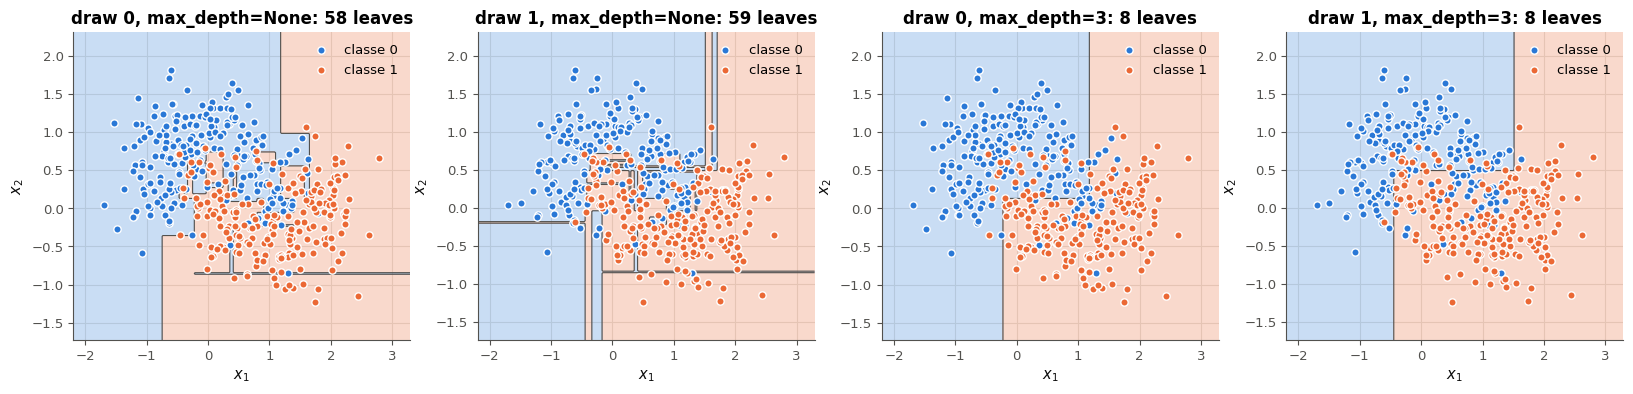

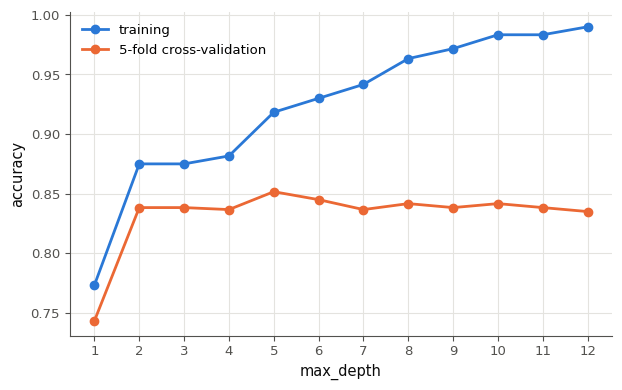

In [50]:
def trees_19(max_depth):
    """The list of 20 trees DecisionTreeClassifier(max_depth=max_depth, random_state=0), one fitted on each draw of
    DRAWS_19 (the rows X_19[draw], Y_19[draw])."""
    return [DecisionTreeClassifier(max_depth=max_depth, random_state=0).fit(X_19[draw], Y_19[draw]) for draw in DRAWS_19]


def disagreement_19(trees):
    """Mean, over all the pairs of trees of the list, of the share of the points of GRID_19 where the two trees
    predict different classes."""
    predictions = np.array([tree.predict(GRID_19) for tree in trees])
    pairs = [(i, j) for i in range(len(trees)) for j in range(i + 1, len(trees))]
    return float(np.mean([np.mean(predictions[i] != predictions[j]) for i, j in pairs]))


full_trees_19 = trees_19(None)
leaves_19 = float(np.mean([tree.get_n_leaves() for tree in full_trees_19]))
disagree_19 = [disagreement_19(full_trees_19), disagreement_19(trees_19(3))]
roots_19 = [tree.tree_.threshold[0] for tree in full_trees_19]
root_range_19 = float(max(roots_19) - min(roots_19))
cv_means_19 = [cross_val_score(DecisionTreeClassifier(max_depth=d, random_state=0), X_19, Y_19, cv=CV_19).mean()
               for d in DEPTHS_19]
best_depth_19 = DEPTHS_19[int(np.argmax(cv_means_19))]
print("root features:", sorted({int(tree.tree_.feature[0]) for tree in full_trees_19}),
      "· root thresholds:", np.round(sorted(roots_19), 3).tolist())
print("leaves: from", min(tree.get_n_leaves() for tree in full_trees_19), "to", max(tree.get_n_leaves() for tree in full_trees_19))
print_answer("13.19a", leaves_19)
print_answer("13.19b", disagree_19)
print_answer("13.19c", root_range_19)
print_answer("13.19d", best_depth_19)
if True:
    if not filled(leaves_19, best_depth_19):
        raise NotImplementedError("leaves_19, best_depth_19")
    fig, axes = plt.subplots(1, 4, figsize=(20, 4))
    for ax, (depth, r) in zip(axes, [(None, 0), (None, 1), (3, 0), (3, 1)]):
        tree = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(X_19[DRAWS_19[r]], Y_19[DRAWS_19[r]])
        wb.plot.plot_decision_boundary(tree, X_19[DRAWS_19[r]], Y_19[DRAWS_19[r]], ax=ax,
                                       title=f"draw {r}, max_depth={depth}: {tree.get_n_leaves()} leaves")
    plt.show()
    train_19 = [DecisionTreeClassifier(max_depth=d, random_state=0).fit(X_19, Y_19).score(X_19, Y_19) for d in DEPTHS_19]
    cv_19 = [cross_val_score(DecisionTreeClassifier(max_depth=d, random_state=0), X_19, Y_19, cv=CV_19).mean()
             for d in DEPTHS_19]
    labels_19 = [str(d) for d in DEPTHS_19]
    plt.plot(labels_19, train_19, marker="o", label="training")
    plt.plot(labels_19, cv_19, marker="o", label="5-fold cross-validation")
    plt.xlabel("max_depth")
    plt.ylabel("accuracy")
    plt.legend()
    plt.show()

In [51]:
wb.record("13.19a", leaves_19, decimals=2)
wb.record("13.19b", disagree_19, decimals=4,
          mistakes={"l'ordre demandé est [sans limite, profondeur 3]": disagree_19[::-1]})
wb.record("13.19c", root_range_19, decimals=4)
train_best_19 = DEPTHS_19[int(np.argmax([DecisionTreeClassifier(max_depth=d, random_state=0).fit(X_19, Y_19).score(X_19, Y_19)
                                         for d in DEPTHS_19]))]
others_19d = {f"max_depth = {d} n'a pas la meilleure accuracy moyenne en validation croisée : rends la profondeur du maximum": d
              for d in DEPTHS_19 if d not in (best_depth_19, train_best_19)}
wb.record("13.19d", best_depth_19, choices=DEPTHS_19,
          fractional="un nombre non entier : est-ce une accuracy ? on demande la profondeur, un élément de DEPTHS_19",
          mistakes={"sur l'entraînement, l'arbre le plus profond gagne toujours : choisis la profondeur sur la validation croisée": train_best_19,
                    **others_19d})

WB_ANSWER {"decimals": 2, "hash": "4dafdfca47af931aae56e88c3ac93bc88aee5509854a2dd8117a48a709446883", "hash_coarse": "e343c187efa0a3c56d24c46ffc1ae8ce2ddffefd630a6c47919d927be816b8f8", "id": "13.19a", "kind": "float", "magnitude": 1, "sign": 1}
📝 Ex 13.19a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 4, "element_coarse": [["93bc4a921f4cc38358b0b00eec5dfdb114b5018bf2855c1c1c09a6dcd1b6aab7"], ["cbf5d64c286b39ceade88d3b26cb92ffa76d4b512b430a3a10a817b383d56644"]], "element_hashes": ["e8c5cfd3a02bad96852c6a9826f0d8577848eed75281a99e3bf4f2debde18ecc", "0ca875873251d45b55cd57eb8018758b6f99c5ed893cc80634cf0bea53e28a25"], "hash": "99d47141f718075f75db0cb9dab9729787a25869efa01ed61dbf7cd1b69596f7", "id": "13.19b", "kind": "array", "mistakes": {"908dcef78a463b089ffb213d4403d016359b5f343668d5096b11b57519601af7": "l'ordre demandé est [sans limite, profondeur 3]"}, "shape": [2]}
📝 Ex 13.19b : réponse enregistrée (array, 4 décimale(s)).
WB_ANSWER {"decimals": 4, "hash": "cbc333

💡 Les arbres sans limite ont 57 feuilles en moyenne (de 49 à 64) pour 420 points : ils isolent les points bruités. Deux d'entre eux, entraînés sur deux tirages de 70 % du même jeu, prédisent des classes différentes sur 10,7 % du plan ; limités à la profondeur 3, sur 6,5 %. Les 20 racines coupent toutes $x_2$, mais à des seuils qui s'étalent sur plus d'une demi-unité : les gains des seuils voisins sont presque égaux, et quelques points en plus ou en moins suffisent à changer le gagnant ; tout ce qui suit dépend de cette première question. L'accuracy d'entraînement monte jusqu'à 1 avec la profondeur ; celle de validation croisée plafonne vers 0,84-0,85, et sa meilleure valeur (profondeur 5) ne bat les profondeurs 2 à 12 que de moins de 0,02 : au-delà, la baisse du biais ne compense plus la hausse de la variance.

### Ex 13.20 — Coder les impuretés et le gain d'un split 🔨 ★★ ⏱️ 25 min
**Objectif :** écrire les trois impuretés et le gain pondéré d'un split, avec des poids d'exemples.  
**Prérequis :** ✏️ 13.2 et 13.3 · ch. 6 (entropie en bits) · fiche §13.5.2 · **mylearn :** `tree.py` · **Parcours :** M, C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/tree.py` (créé par `python tools/start_chapter.py 13`), lis la docstring de chaque fonction et de chaque méthode, remplace les `raise NotImplementedError(...)` par ton code et **enregistre**. NumPy seulement : scikit-learn et SciPy sont les **oracles** des tests. La cellule de vérification recharge ta librairie, compare quelques résultats à scikit-learn, puis lance les tests de l'exercice ; `python -m pytest tests/test_ch13_tree.py -q` les lance tous dans un terminal.

Écris `gini_impurity`, `entropy_impurity`, `variance_impurity` et `split_gain`. **Contrat** (les docstrings, plus ces précisions que vérifient les tests) :
- les trois impuretés reçoivent `y` (une liste ou un tableau 1-D, des labels quelconques pour les deux premières, des nombres pour la variance) et `sample_weight` (`None` : tous les poids valent 1) et rendent un `float` Python ; les proportions et la moyenne sont **pondérées** : un poids 2 compte comme un exemple répété deux fois, une classe de poids nul ne compte pas (et ne donne pas de `nan` dans l'entropie) ;
- l'entropie est en **bits** ($\log_2$, avec $0 \log 0 = 0$) ; la variance est la moyenne pondérée des carrés des écarts à la moyenne pondérée (ddof = 0) ;
- `split_gain(y, left_mask, criterion="gini", sample_weight=None)` rend $I(\text{parent}) - \frac{w_G}{w} I(G) - \frac{w_D}{w} I(D)$, avec les poids totaux $w_G$, $w_D$ et $w$ (les nombres d'exemples quand les poids valent 1), pour `criterion` dans `"gini"`, `"entropy"`, `"squared_error"` ; si un enfant est vide, le gain vaut `0.0` ;
- erreurs (`ValueError`) : `y` vide ; des poids négatifs, de mauvaise forme ou de somme nulle ; un critère inconnu ; des formes différentes pour `y`, `left_mask` et `sample_weight`.

La vérification essaie les exemples des docstrings, compare l'impureté de la racine et le gain du premier split d'un arbre scikit-learn sur les manchots, puis lance les tests.

Dans tes notes : pourquoi pondérer chaque enfant par sa part des exemples ? Que vaudrait le « gain » d'un split qui envoie un seul exemple à gauche, si l'on oubliait la pondération ?

In [52]:
with checked("13.20"):
    cases_20 = [("gini_impurity([0, 0, 1, 1])", lambda: mylearn.tree.gini_impurity([0, 0, 1, 1]), 0.5),
                ('gini_impurity(["a", "a", "a", "b"])', lambda: mylearn.tree.gini_impurity(["a", "a", "a", "b"]), 0.375),
                ("gini_impurity([0, 1], sample_weight=[3.0, 1.0])",
                 lambda: mylearn.tree.gini_impurity([0, 1], sample_weight=[3.0, 1.0]), 0.375),
                ("entropy_impurity([0, 0, 0, 1])", lambda: mylearn.tree.entropy_impurity([0, 0, 0, 1]), 0.811278),
                ("variance_impurity([1.0, 2.0, 3.0, 4.0])", lambda: mylearn.tree.variance_impurity([1.0, 2.0, 3.0, 4.0]), 1.25),
                ('split_gain([0, 0, 1, 1], [True, True, False, False], criterion="entropy")',
                 lambda: mylearn.tree.split_gain([0, 0, 1, 1], [True, True, False, False], criterion="entropy"), 1.0)]
    for text_20, call_20, want_20 in cases_20:
        try:
            got_20 = call_20()
        except NotImplementedError:
            print(f"⏳ {text_20} : pas encore écrite")
            continue
        ok_20 = isinstance(got_20, (int, float, np.floating)) and np.isclose(got_20, want_20, atol=1e-6)
        print(("✅ " if ok_20 else "❌ ") + f"{text_20} = {got_20!r} (expected {want_20})")
with checked("13.20"):
    X_20, y_20 = P_TRAIN[MEASURES].to_numpy(), P_TRAIN["species"].to_numpy()
    for criterion, impurity_20 in [("gini", mylearn.tree.gini_impurity), ("entropy", mylearn.tree.entropy_impurity)]:
        t_20 = DecisionTreeClassifier(criterion=criterion, max_depth=1, random_state=0).fit(X_20, y_20).tree_
        left_20, right_20 = t_20.children_left[0], t_20.children_right[0]
        sk_gain_20 = t_20.impurity[0] - (t_20.n_node_samples[left_20] * t_20.impurity[left_20]
                                         + t_20.n_node_samples[right_20] * t_20.impurity[right_20]) / t_20.n_node_samples[0]
        mask_20 = as_float32(X_20)[:, t_20.feature[0]] <= t_20.threshold[0]
        root_20 = impurity_20(y_20)
        gain_20 = mylearn.tree.split_gain(y_20, mask_20, criterion=criterion)
        if not (returned("13.20", f"{criterion}_impurity", root_20) and returned("13.20", "split_gain", gain_20)):
            continue
        if not all(isinstance(value, (int, float, np.floating)) for value in (root_20, gain_20)):
            print(f"❌ Ex 13.20 : {criterion}_impurity et split_gain doivent rendre un nombre (un float), pas "
                  f"{type(root_20).__name__} et {type(gain_20).__name__}.")
        else:
            verdict("13.20", np.isclose(root_20, t_20.impurity[0]) and np.isclose(gain_20, sk_gain_20),
                    f"{criterion} : impureté de la racine {fr(root_20)} et gain du premier split de scikit-learn "
                    f"{fr(gain_20)}, comme scikit-learn.",
                    f"{criterion} : scikit-learn trouve une impureté de {fr(t_20.impurity[0])} à la racine et un gain "
                    f"de {fr(sk_gain_20)} pour son premier split ; les tests ci-dessous disent où est l'écart.")
if written(lambda: mylearn.tree.gini_impurity([0, 1])):
    run_mylearn_tests(impl="ref", module="tree", keyword="test_gini_impurity_ or test_entropy_impurity_ or test_variance_impurity_ or test_split_gain_")
else:
    print("⏳ Ex 13.20 : les tests attendent ton gini_impurity.")

✅ gini_impurity([0, 0, 1, 1]) = 0.5 (expected 0.5)
✅ gini_impurity(["a", "a", "a", "b"]) = 0.375 (expected 0.375)
✅ gini_impurity([0, 1], sample_weight=[3.0, 1.0]) = 0.375 (expected 0.375)
✅ entropy_impurity([0, 0, 0, 1]) = 0.8112781244591328 (expected 0.811278)
✅ variance_impurity([1.0, 2.0, 3.0, 4.0]) = 1.25 (expected 1.25)
✅ split_gain([0, 0, 1, 1], [True, True, False, False], criterion="entropy") = 1.0 (expected 1.0)
✅ Ex 13.20 : gini : impureté de la racine 0,639 et gain du premier split de scikit-learn 0,325, comme scikit-learn.
✅ Ex 13.20 : entropy : impureté de la racine 1,522 et gain du premier split de scikit-learn 0,789, comme scikit-learn.


pytest: 66 passed, 218 deselected in 0.85s


💡 Sans pondération, un split qui isole un seul exemple pur dans un enfant fait chuter la moyenne simple des impuretés (l'une d'elles vaut 0) alors qu'il ne trie presque rien : la pondération mesure la baisse **moyenne** d'impureté par exemple, et l'enfant d'un seul exemple ne pèse que $1/n$.

### Ex 13.21 — L'arbre parfait qui triche : une colonne identifiant 🐛 ★★ ⏱️ 20 min
**Objectif :** repérer qu'un modèle trop beau s'appuie sur une colonne qui n'apprend rien du phénomène.  
**Prérequis :** Ex 13.19 · ch. 12 (lecture des fichiers, fuites) · fiche §13.5.3 (pièges : les `feature_importances_`) · **Fil rouge :** Penguins · **Parcours :** C

Un collègue enregistre les 333 manchots dans un fichier CSV, le relit, et entraîne un arbre sur « toutes les colonnes sauf l'espèce ». Son arbre est **parfait** sur le test : 100 %. La saison suivante, les manchots du test sont remesurés et ajoutés au fichier : `NEXT_21`. Mène l'enquête, sans modifier les données du collègue :
a) `top_feature_21` : le nom de la feature la plus importante de `TREE_21` (`feature_importances_`) ;
b) `next_accuracy_21` : l'accuracy de `TREE_21` sur `NEXT_21` ;
c) `clean_accuracy_21` : l'accuracy de test (`TEST_21`) d'un `DecisionTreeClassifier(random_state=0)` entraîné sur `TRAIN_21` **sans** la colonne fautive ;
d) `clean_leaves_21` : le nombre de feuilles de l'arbre de c).

Dans tes notes : d'où vient la colonne fautive, et pourquoi suffit-elle à classer parfaitement ? Combien de feuilles lui faut-il, et pourquoi exactement ce nombre ? Qu'arrive-t-il aux manchots de la saison suivante ? Comment le collègue aurait-il dû écrire et relire son fichier, et quel contrôle aurait révélé le problème avant le test ?

In [53]:
# A colleague saves the 333 penguins in a CSV file (index included, the default of to_csv), then reads it back
CSV_21 = PENGUINS[MEASURES + ["species"]].to_csv()
DATA_21 = pd.read_csv(io.StringIO(CSV_21))
FEATURES_21 = [column for column in DATA_21.columns if column != "species"]   # "every column but the target"
TRAIN_21, TEST_21 = train_test_split(DATA_21, test_size=0.3, random_state=1321, stratify=DATA_21["species"])
TREE_21 = DecisionTreeClassifier(random_state=0).fit(TRAIN_21[FEATURES_21], TRAIN_21["species"])
print(f"the colleague's tree: test accuracy {TREE_21.score(TEST_21[FEATURES_21], TEST_21['species']):.3f}")
# Next season: the test penguins are measured again, appended to the file, which is saved and read back
NEXT_FILE_21 = pd.concat([PENGUINS[MEASURES + ["species"]], PENGUINS.loc[TEST_21.index, MEASURES + ["species"]]],
                         ignore_index=True).to_csv()
NEXT_21 = pd.read_csv(io.StringIO(NEXT_FILE_21)).iloc[len(PENGUINS):]
print(len(NEXT_21), "penguins next season")

the colleague's tree: test accuracy 1.000
100 penguins next season


In [54]:
print(export_text(TREE_21, feature_names=FEATURES_21))
top_feature_21 = FEATURES_21[int(np.argmax(TREE_21.feature_importances_))]
next_accuracy_21 = TREE_21.score(NEXT_21[FEATURES_21], NEXT_21["species"])
print("next season, predicted species:", pd.Series(TREE_21.predict(NEXT_21[FEATURES_21])).value_counts().to_dict())
clean_21 = DecisionTreeClassifier(random_state=0).fit(TRAIN_21[MEASURES], TRAIN_21["species"])
clean_accuracy_21 = clean_21.score(TEST_21[MEASURES], TEST_21["species"])
clean_leaves_21 = clean_21.get_n_leaves()
print_answer("13.21a", top_feature_21)
print_answer("13.21b", next_accuracy_21)
print_answer("13.21c", clean_accuracy_21)
print_answer("13.21d", clean_leaves_21)

|--- Unnamed: 0 <= 145.50
|   |--- class: Adelie
|--- Unnamed: 0 >  145.50
|   |--- Unnamed: 0 <= 264.50
|   |   |--- class: Gentoo
|   |--- Unnamed: 0 >  264.50
|   |   |--- class: Chinstrap

next season, predicted species: {'Chinstrap': 100}
13.21a: Unnamed: 0
13.21b: 0.2
13.21c: 0.96
13.21d: 9


In [55]:
wb.record("13.21a", top_feature_21,
          mistakes={"c'est la feature la plus importante d'un arbre sans la colonne fautive : lis feature_importances_ de TREE_21": MEASURES[int(np.argmax(clean_21.feature_importances_))]})
wb.record("13.21b", next_accuracy_21, decimals=4,
          mistakes={"c'est l'accuracy sur TEST_21 : mesure-la sur NEXT_21": TREE_21.score(TEST_21[FEATURES_21], TEST_21["species"])})
wb.record("13.21c", clean_accuracy_21, decimals=4,
          mistakes={"un arbre parfait : la colonne fautive est-elle bien retirée des features ?": 1.0})
wb.record("13.21d", clean_leaves_21,
          mistakes={"c'est le nombre de feuilles de TREE_21 : compte celles de l'arbre sans la colonne fautive": TREE_21.get_n_leaves()})

WB_ANSWER {"hash": "56c5fccdf1fed7b0ba3ca59bb05550b613cc3eab3bad7453c08f0bbb4fb00bdf", "id": "13.21a", "kind": "str", "mistakes": {"fadaa141d84e4a848f4a5c74dea6b7e7655428ce0597cf40797c488a59f3e2c2": "c'est la feature la plus importante d'un arbre sans la colonne fautive : lis feature_importances_ de TREE_21"}}
📝 Ex 13.21a : réponse enregistrée (str).
WB_ANSWER {"decimals": 4, "hash": "67bcc348edf635928c1cc9b26b7afc5edbfa6e39b30844498725912add2996d9", "hash_coarse": "d433b3d37ed8ac084022be2f68f40df2eabef8c691557a61e9ab4cd4e20fe2fd", "id": "13.21b", "kind": "float", "magnitude": -1, "mistakes": {"4b69e8e443473a18fe0617bc6f9cd1397bb38f620d62ac5423e8c76c7901a862": "c'est l'accuracy sur TEST_21 : mesure-la sur NEXT_21"}, "sign": 1}
📝 Ex 13.21b : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"decimals": 4, "hash": "5055f096ae106212921ff4cbd3714f2b31bf3447b219df16e5c6048a9dce625f", "hash_coarse": "a2cae36b881118da58dd35089e5083ef15e4eebcab618ca66cdf02d1feadab6e", "id": "13.21c", "kin

💡 `to_csv()` écrit l'index par défaut, et `read_csv` le relit comme une colonne sans nom, `Unnamed: 0` : le numéro de ligne. Le fichier est trié par espèce (146 Adélie, puis 119 Gentoo, puis 68 Chinstrap, après le retrait des lignes incomplètes) : deux seuils sur ce numéro suffisent, d'où un arbre de **3 feuilles** et une importance de 1 pour cette seule colonne. La saison suivante, les lignes ajoutées portent des numéros au-delà de 332 : toutes tombent dans la dernière feuille, Chinstrap, et l'accuracy chute à 0,2, la part des Chinstrap. Sans la colonne, l'arbre fait 0,96 avec 9 feuilles. Il fallait écrire `to_csv(index=False)` (ou relire avec `index_col=0`), choisir les features par leur nom plutôt que « tout sauf la cible », et regarder les `feature_importances_` (ou `export_text`) d'un modèle trop beau pour être vrai.

### Ex 13.22 — Coder la recherche du meilleur split 🔨 ★★★ ⏱️ 45 min
**Objectif :** écrire la recherche gloutonne d'un split, avec les conventions qui la rendent identique à scikit-learn.  
**Prérequis :** Ex 13.20 · ✏️ 13.3 · fiche §13.5.1 et §13.5.2 · **Fil rouge :** Penguins · **mylearn :** `tree.py` · **Parcours :** M, C

> **mylearn** : dans `mon_travail/mylearn/tree.py`, mêmes règles qu'en 13.20 (NumPy seulement, scikit-learn pour oracle). Enregistre, puis relance la cellule de vérification.

Écris `best_split`. **Contrat** (la docstring, plus ces précisions que vérifient les tests) :
- `best_split(X, y, criterion="gini", sample_weight=None, feature_indices=None, min_samples_leaf=1, splitter="best", rng=None)` rend `(feature, threshold, gain)` (un `int` et deux `float` Python) ou `None` ; les exemples tels que `X[:, feature] <= threshold` vont à gauche ;
- `splitter="best"` : les seuils candidats d'une feature sont les **milieux** de deux valeurs distinctes consécutives (triées) ; `splitter="random"` (pour les ExtraTrees du ch. 14) : un seul seuil par feature, tiré par `rng.uniform(min, max)` des valeurs du nœud, dans l'ordre de `feature_indices` ; une feature constante est sautée (aucun tirage) ; `rng=None` : `np.random.default_rng()` ;
- `feature_indices` : les features à examiner (`None` : toutes) ; la feature rendue est son indice **dans `X`** ;
- un candidat n'est valide que si chaque enfant reçoit au moins `min_samples_leaf` exemples (comptés sans les poids) ; son gain est celui de `split_gain`, avec les poids ;
- le meilleur gain l'emporte ; les égalités se jugent **à l'arrondi près** (un candidat ne remplace le meilleur que si son gain le dépasse de plus de $10^{-12}$ environ) et vont à la plus petite feature, puis au plus petit seuil, quel que soit l'ordre de `feature_indices` ;
- `None` si aucun candidat valide n'a un gain strictement positif (au-delà de l'arrondi) : le nœud deviendra une feuille ; la fonction ne modifie pas ses arguments ; `ValueError` pour un critère ou un `splitter` inconnu, ou des formes incohérentes.

La vérification essaie l'exemple de la docstring, compare ton premier split des manchots à celui de scikit-learn (Gini et entropie), puis lance les tests.

Dans tes notes : combien de seuils candidats examines-tu pour la longueur des nageoires des 233 manchots ? Pourquoi juger les égalités à l'arrondi près, et pourquoi la plus petite feature ? Pourquoi un gain nul doit-il arrêter ta recherche (le « ou exclusif » de la fiche) ?

In [56]:
with checked("13.22"):
    doc_22 = mylearn.tree.best_split(np.array([[1.0, 5.0], [2.0, 3.0], [3.0, 8.0], [4.0, 1.0]]), np.array([0, 0, 1, 1]))
    if returned("13.22", "best_split", doc_22):
        print("docstring example:", doc_22, "(expected (0, 2.5, 0.5))")
with checked("13.22"):
    X_22, y_22 = as_float32(P_TRAIN[MEASURES]), P_TRAIN["species"].to_numpy()
    for criterion in ["gini", "entropy"]:
        t_22 = DecisionTreeClassifier(criterion=criterion, max_depth=1, random_state=0).fit(X_22, y_22).tree_
        left_22, right_22 = t_22.children_left[0], t_22.children_right[0]
        sk_gain_22 = t_22.impurity[0] - (t_22.n_node_samples[left_22] * t_22.impurity[left_22]
                                         + t_22.n_node_samples[right_22] * t_22.impurity[right_22]) / t_22.n_node_samples[0]
        mine_22 = mylearn.tree.best_split(X_22, y_22, criterion=criterion)
        ok_22 = (isinstance(mine_22, tuple) and len(mine_22) == 3 and mine_22[0] == t_22.feature[0]
                 and np.isclose(mine_22[1], t_22.threshold[0]) and np.isclose(mine_22[2], sk_gain_22))
        verdict("13.22", ok_22,
                f"{criterion} : {MEASURES[t_22.feature[0]]} <= {fr(t_22.threshold[0], 2)}, gain {fr(sk_gain_22)}, comme "
                "la racine de scikit-learn.",
                f"{criterion} : best_split rend {mine_22} ; scikit-learn coupe la feature {t_22.feature[0]} "
                f"({MEASURES[t_22.feature[0]]}) en {t_22.threshold[0]:.4f}, avec un gain de {sk_gain_22:.6f}.")
if written(lambda: mylearn.tree.best_split(np.array([[0.0], [1.0]]), np.array([0, 1]))):
    run_mylearn_tests(impl="ref", module="tree", keyword="test_best_split_")
else:
    print("⏳ Ex 13.22 : les tests attendent ton best_split.")

docstring example: (0, 2.5, 0.5) (expected (0, 2.5, 0.5))
✅ Ex 13.22 : gini : flipper_length_mm <= 207,50, gain 0,325, comme la racine de scikit-learn.
✅ Ex 13.22 : entropy : flipper_length_mm <= 207,50, gain 0,789, comme la racine de scikit-learn.


pytest: 54 passed, 230 deselected in 1.13s


💡 Une feature de $m$ valeurs distinctes donne $m - 1$ seuils candidats : 51 pour les longueurs de nageoires des 233 manchots d'entraînement (52 valeurs entières distinctes, de 172 à 231 mm). Deux gains égaux en théorie peuvent différer d'une unité du dernier chiffre selon l'ordre des opérations : sans tolérance, un arrondi choisirait la feature, et ton arbre différerait de la référence ; la règle « plus petite feature, puis plus petit seuil » rend le choix reproductible, quel que soit l'ordre de tirage d'une forêt. Un gain nul ne trie rien : ta librairie s'arrête, comme le dit la fiche (le « ou exclusif » : aucune question seule ne fait baisser l'impureté).

### Ex 13.23 — Arbres scikit-learn : plot_tree, export_text et élagage ccp_alpha 📦 ★★★ ⏱️ 35 min
**Objectif :** élaguer un arbre par validation croisée, puis le lire comme une suite de règles.  
**Prérequis :** Ex 13.19 · fiche §13.5.3 (élagage par coût-complexité) et §13.7 · **Fil rouge :** Penguins · **Parcours :** R, C

Les 333 manchots, découpés en 70 % pour l'entraînement et 30 % pour le test, avec les 4 mesures. Calcule :
- `full_23` : un `DecisionTreeClassifier(random_state=0)` sans limite, entraîné sur la partie d'entraînement ;
- a) `size_23` : la liste `[profondeur, nombre de feuilles]` de `full_23` ;
- `alphas_23` : les valeurs de `ccp_alpha` que rend `full_23.cost_complexity_pruning_path(...)`, **sans la dernière** (celle qui réduit l'arbre à sa racine) ;
- b) `best_alpha_23` : la valeur de `alphas_23` qui donne la meilleure accuracy moyenne en validation croisée à 5 folds (`CV_23`) ; à égalité (`np.isclose`), la **plus grande** ;
- `pruned_23` : l'arbre élagué avec cette valeur, entraîné sur toute la partie d'entraînement ;
- c) `pruned_size_23` : la liste `[profondeur, nombre de feuilles]` de `pruned_23` ;
- d) `test_23` : la liste `[accuracy de test de full_23, accuracy de test de pruned_23]`.

La vérification contrôle a) à d), puis dessine l'arbre élagué (`plot_tree`) et affiche ses règles (`export_text`).

Dans tes notes : pourquoi retirer la dernière valeur, et pourquoi préférer la plus grande en cas d'égalité ? Écris en une phrase française la règle qui reconnaît un Gentoo. L'arbre élagué a-t-il « perdu » sur le test ? Que vaut une différence d'un manchot sur 100 ?

In [57]:
TRAIN_23, TEST_23 = train_test_split(PENGUINS, test_size=0.3, random_state=1323, stratify=PENGUINS["species"])
X_TRAIN_23, Y_TRAIN_23 = TRAIN_23[MEASURES].to_numpy(), TRAIN_23["species"].to_numpy()
X_TEST_23, Y_TEST_23 = TEST_23[MEASURES].to_numpy(), TEST_23["species"].to_numpy()
CV_23 = StratifiedKFold(n_splits=5, shuffle=True, random_state=1323)
print(len(TRAIN_23), "training penguins,", len(TEST_23), "test penguins")

233 training penguins, 100 test penguins


alpha = 0.00000: mean accuracy 0.9526
alpha = 0.00425: mean accuracy 0.9526
alpha = 0.00812: mean accuracy 0.9569
alpha = 0.00825: mean accuracy 0.9569
alpha = 0.01226: mean accuracy 0.9441
alpha = 0.04406: mean accuracy 0.9312
alpha = 0.21550: mean accuracy 0.8502
13.23a: [5.0, 12.0]
13.23b: 0.008247899803975552
13.23c: [3.0, 5.0]
13.23d: [0.97, 0.96]


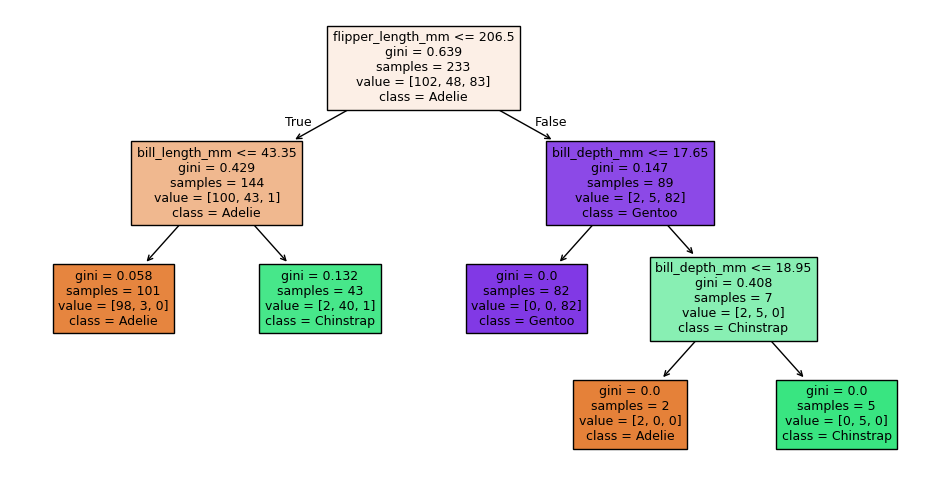

|--- flipper_length_mm <= 206.50
|   |--- bill_length_mm <= 43.35
|   |   |--- class: Adelie
|   |--- bill_length_mm >  43.35
|   |   |--- class: Chinstrap
|--- flipper_length_mm >  206.50
|   |--- bill_depth_mm <= 17.65
|   |   |--- class: Gentoo
|   |--- bill_depth_mm >  17.65
|   |   |--- bill_depth_mm <= 18.95
|   |   |   |--- class: Adelie
|   |   |--- bill_depth_mm >  18.95
|   |   |   |--- class: Chinstrap



In [58]:
full_23 = DecisionTreeClassifier(random_state=0).fit(X_TRAIN_23, Y_TRAIN_23)
size_23 = [full_23.get_depth(), full_23.get_n_leaves()]
alphas_23 = full_23.cost_complexity_pruning_path(X_TRAIN_23, Y_TRAIN_23).ccp_alphas[:-1]
cv_23 = np.array([cross_val_score(DecisionTreeClassifier(ccp_alpha=alpha, random_state=0), X_TRAIN_23, Y_TRAIN_23,
                                  cv=CV_23).mean() for alpha in alphas_23])
best_alpha_23 = float(alphas_23[np.isclose(cv_23, cv_23.max())].max())
pruned_23 = DecisionTreeClassifier(ccp_alpha=best_alpha_23, random_state=0).fit(X_TRAIN_23, Y_TRAIN_23)
pruned_size_23 = [pruned_23.get_depth(), pruned_23.get_n_leaves()]
test_23 = [full_23.score(X_TEST_23, Y_TEST_23), pruned_23.score(X_TEST_23, Y_TEST_23)]
for alpha, score in zip(alphas_23, cv_23):
    print(f"alpha = {alpha:.5f}: mean accuracy {score:.4f}")
print_answer("13.23a", size_23)
print_answer("13.23b", best_alpha_23)
print_answer("13.23c", pruned_size_23)
print_answer("13.23d", test_23)
if True:
    if not filled(pruned_23) or not hasattr(pruned_23, "tree_"):
        raise NotImplementedError("pruned_23")
    plt.figure(figsize=(12, 6))
    plot_tree(pruned_23, feature_names=MEASURES, class_names=list(pruned_23.classes_), filled=True, fontsize=9)
    plt.show()
    print(export_text(pruned_23, feature_names=MEASURES))

In [59]:
wb.record("13.23a", size_23, mistakes={"l'ordre demandé est [profondeur, nombre de feuilles]": size_23[::-1]})
tied_23 = alphas_23[np.isclose(cv_23, cv_23.max())]
wb.record("13.23b", best_alpha_23, decimals=5,
          mistakes={"à égalité, garde la PLUS GRANDE valeur : l'arbre le plus simple": float(tied_23.min())})
wb.record("13.23c", pruned_size_23, mistakes={"l'ordre demandé est [profondeur, nombre de feuilles]": pruned_size_23[::-1]})
wb.record("13.23d", test_23, decimals=4, mistakes={"l'ordre demandé est [arbre complet, arbre élagué]": test_23[::-1]})

WB_ANSWER {"decimals": 0, "element_hashes": ["736a641f7a9030fbd4ab15136aafe389836576233b082596bd4bf9515911328c", "59bb7a73e7e1f91eae5016502c1b9174257e0905eec40138ec49dc1f19d95c20"], "hash": "be52a204d29f9550bca595a3e4fad6383af90293dfd4bd572d4a29938d7aead2", "id": "13.23a", "integer": true, "kind": "array", "mistakes": {"b1c4cc0b8dec61a1c1f243641e6fc87b38d697c9c14890df014d77b81c731350": "l'ordre demandé est [profondeur, nombre de feuilles]"}, "shape": [2]}
📝 Ex 13.23a : réponse enregistrée (array, 0 décimale(s)).
WB_ANSWER {"decimals": 5, "hash": "baae23a601c085eed27a88455cedb97e794cc39ffd71f7a14abb64333ab092b6", "hash_coarse": "61c4775f36a03800d2a4b482c7f8a515f20481be1cf5bc946d329714055bb641", "id": "13.23b", "kind": "float", "magnitude": -3, "mistakes": {"f0fa7307514174f9eb8c33d0b90c0f5802bb3d2bb420d00b6ff81984a40cd44b": "à égalité, garde la PLUS GRANDE valeur : l'arbre le plus simple"}, "sign": 1}
📝 Ex 13.23b : réponse enregistrée (float, 5 décimale(s)).
WB_ANSWER {"decimals": 0, "el

💡 L'arbre complet a une profondeur de 5 et 12 feuilles. Le chemin d'élagage donne 7 valeurs utiles de `ccp_alpha` ; la dernière (environ 0,32) réduirait l'arbre à sa seule racine, un modèle qui prédit la classe majoritaire. Deux valeurs voisines (environ 0,0081 et 0,0082) ont la même accuracy moyenne (0,957) : on garde la plus grande, qui donne l'arbre le plus simple, selon le principe de parcimonie. L'arbre élagué n'a plus que 5 feuilles et une profondeur de 3 : « si les nageoires dépassent 206,5 mm et le bec a moins de 17,65 mm d'épaisseur, c'est un Gentoo ». Il fait 0,96 en test contre 0,97 : un seul manchot d'écart sur 100, bien moins que l'incertitude d'une accuracy mesurée sur 100 exemples (un écart-type d'environ 2 points). À accuracy presque égale, on garde l'arbre qu'on peut lire.

### Ex 13.24 — Coder un arbre de décision récursif 🔨 ★★★★ ⏱️ 100 min
**Objectif :** construire un arbre CART complet, identique nœud par nœud à celui de scikit-learn.  
**Prérequis :** Ex 13.22 · 0A (fonctions récursives, `@dataclass`) · fiche §13.5 et §13.5.1 (pseudo-code) · **Fil rouge :** Penguins · **mylearn :** `tree.py` · **Parcours :** M, C

> **mylearn** : dans `mon_travail/mylearn/tree.py`, mêmes règles qu'en 13.20. Enregistre, puis relance la cellule de vérification. La classe `Node` est fournie complète.

Écris la classe `DecisionTreeClassifier` (sauf les options du 13.25 : ici, `sample_weight=None`, `max_features=None` et `splitter="best"` suffisent). **Contrat** (la docstring, plus ces précisions que vérifient les tests) :
- `__init__` range ses sept arguments tels quels ; `fit(X, y, sample_weight=None)` vérifie, apprend `classes_` (les labels distincts triés), `n_classes_`, `n_features_in_` et `root_`, puis renvoie `self` ; un second `fit` oublie le premier ; `fit` et `predict` ne modifient pas leurs arguments, et acceptent des listes ;
- un nœud devient une **feuille** s'il est pur, si la profondeur `max_depth` est atteinte, s'il a **moins** de `min_samples_split` exemples, ou si `best_split` ne trouve rien (ta fonction du 13.22, avec `min_samples_leaf`) ; sinon il est coupé, et ses deux enfants se construisent de la même façon ;
- chaque nœud est un `Node` : `feature` et `threshold` (`None` pour une feuille), `left` et `right`, `value` (les proportions des classes dans le nœud, alignées sur `classes_`), `n_samples` (le nombre d'exemples qui l'atteignent) et `impurity` (son impureté pour le critère de l'arbre) ;
- `predict_proba(X)` rend la `value` de la feuille atteinte par chaque exemple ; `predict(X)` la classe de plus grande proportion (à égalité, la première de `classes_`) ; `get_depth()` (0 si la racine est une feuille) ; `get_n_leaves()` ; `score(X, y)` l'accuracy, un `float` Python ;
- erreurs : `ValueError` pour un critère autre que `"gini"` ou `"entropy"`, `max_depth < 1` (`None` est permis), `min_samples_split < 2`, `min_samples_leaf < 1`, un `X` qui n'est pas 2-D ou contient `NaN`, `len(X) != len(y)`, ou un mauvais nombre de colonnes à la prédiction ; `RuntimeError` si `predict`, `predict_proba`, `get_depth` ou `get_n_leaves` est appelée avant `fit`.

La vérification essaie l'exemple de la docstring, compare ton arbre à celui de scikit-learn sur des demi-lunes (trois réglages : même profondeur, même nombre de feuilles, mêmes prédictions sur une grille ; ces réglages évitent les nœuds minuscules, où deux features ont souvent le même gain : scikit-learn départage ces égalités au hasard, ta librairie par le plus petit indice), affiche les règles de ton arbre de profondeur 2 sur les manchots, puis lance les tests (ceux du 13.25 restent pour plus tard).

Dans tes notes : ta construction est-elle récursive ou utilise-t-elle une pile ? Combien de fois appelles-tu `best_split` pour un arbre de $L$ feuilles ? Quelle est la profondeur maximale d'un arbre sur $n$ exemples, et quel risque cela fait-il courir à une fonction récursive en Python ?

In [60]:
with checked("13.24"):
    doc_24 = fitted(mylearn.tree.DecisionTreeClassifier(), np.array([[1.0], [2.0], [3.0], [4.0]]), np.array([0, 0, 1, 1]))
    root_24 = getattr(doc_24, "root_", None)
    print("docstring example: root", None if root_24 is None else (root_24.feature, root_24.threshold),
          "(expected (0, 2.5)) · depth", doc_24.get_depth(), "and leaves", doc_24.get_n_leaves(), "(expected 1 and 2)")
with checked("13.24"):
    X_24, Y_24 = wb.synth.make_moons(n=300, noise=0.3, seed=1324)
    X_24 = as_float32(X_24)                                       # continuous data, no ties
    grid1_24, grid2_24 = np.meshgrid(np.linspace(-1.5, 2.5, 80), np.linspace(-1.2, 1.7, 60))
    grid_24 = as_float32(np.column_stack([grid1_24.ravel(), grid2_24.ravel()]))
    for params in [{"max_depth": 3}, {"min_samples_split": 10}, {"criterion": "entropy", "min_samples_leaf": 5}]:
        mine_24 = fitted(mylearn.tree.DecisionTreeClassifier(**params), X_24, Y_24)
        oracle_24 = DecisionTreeClassifier(random_state=0, **params).fit(X_24, Y_24)
        shape_24 = (mine_24.get_depth(), mine_24.get_n_leaves())
        if shape_24 != (oracle_24.get_depth(), oracle_24.get_n_leaves()):
            print(f"❌ Ex 13.24 : {params} : scikit-learn a une profondeur de {oracle_24.get_depth()} et "
                  f"{oracle_24.get_n_leaves()} feuilles, ton arbre {shape_24[0]} et {shape_24[1]} ; les tests "
                  "ci-dessous disent où.")
        elif not np.array_equal(np.asarray(mine_24.predict(grid_24)), oracle_24.predict(grid_24)):
            print(f"❌ Ex 13.24 : {params} : même profondeur et mêmes feuilles que scikit-learn, mais d'autres "
                  "prédictions sur la grille : un seuil ou une feature diffère ; les tests ci-dessous disent où.")
        else:
            print(f"✅ Ex 13.24 : {params} : même profondeur ({shape_24[0]}), même nombre de feuilles ({shape_24[1]}) "
                  "et mêmes prédictions que scikit-learn.")
with checked("13.24"):
    penguin_tree_24 = fitted(mylearn.tree.DecisionTreeClassifier(max_depth=2), P_TRAIN[MEASURES].to_numpy(),
                             P_TRAIN["species"].to_numpy())
    print("\n".join(tree_rules(penguin_tree_24.root_, MEASURES, penguin_tree_24.classes_)))
    print("test accuracy of this depth-2 tree:", fr(penguin_tree_24.score(P_TEST[MEASURES].to_numpy(), P_TEST["species"].to_numpy())))
if written(lambda: mylearn.tree.DecisionTreeClassifier().fit(np.array([[0.0], [1.0]]), np.array([0, 1]))):
    run_mylearn_tests(impl="ref", module="tree", keyword="test_decision_tree_classifier_ and not ensemble")
else:
    print("⏳ Ex 13.24 : les tests attendent le fit de ton DecisionTreeClassifier.")

docstring example: root (0, 2.5) (expected (0, 2.5)) · depth 1 and leaves 2 (expected 1 and 2)
✅ Ex 13.24 : {'max_depth': 3} : même profondeur (3), même nombre de feuilles (7) et mêmes prédictions que scikit-learn.
✅ Ex 13.24 : {'min_samples_split': 10} : même profondeur (10), même nombre de feuilles (30) et mêmes prédictions que scikit-learn.
✅ Ex 13.24 : {'criterion': 'entropy', 'min_samples_leaf': 5} : même profondeur (8), même nombre de feuilles (25) et mêmes prédictions que scikit-learn.
|--- flipper_length_mm <= 207.50
|   |--- bill_length_mm <= 43.15
|   |   |--- class: Adelie  (99 samples)
|   |--- bill_length_mm >  43.15
|   |   |--- class: Chinstrap  (47 samples)
|--- flipper_length_mm >  207.50
|   |--- bill_depth_mm <= 17.65
|   |   |--- class: Gentoo  (82 samples)
|   |--- bill_depth_mm >  17.65
|   |   |--- class: Chinstrap  (5 samples)
test accuracy of this depth-2 tree: 0,940


pytest: 49 passed, 235 deselected in 1.20s


💡 Un arbre de $L$ feuilles a $L - 1$ nœuds internes : `best_split` réussit $L - 1$ fois, et échoue (ou n'est pas appelée) une fois par feuille. Un arbre sur $n$ exemples peut atteindre une profondeur de $n - 1$ (un exemple détaché à chaque niveau) ; Python limite la récursion à environ 1 000 appels (`sys.getrecursionlimit()`) : une construction récursive peut échouer sur un jeu de plusieurs milliers d'exemples mal séparés, d'où la pile explicite de la référence (même ordre : enfant gauche d'abord).

### Ex 13.25 — Préparer l'arbre pour les ensembles : poids, features tirées, importances 🔨 ★★★ ⏱️ 50 min
**Objectif :** ajouter à ton arbre les options dont les ensembles du ch. 14 auront besoin.  
**Prérequis :** Ex 13.24 · fiche §13.5.2 et §13.5.3 · **Fil rouge :** synth · **mylearn :** `tree.py` · **Parcours :** C

> **mylearn** : dans `mon_travail/mylearn/tree.py`, mêmes règles qu'en 13.20. Enregistre, puis relance la cellule de vérification.

Complète `DecisionTreeClassifier` avec ce dont le ch. 14 aura besoin. **Contrat** (la docstring, plus ces précisions que vérifient les tests) :
- `sample_weight` (pour AdaBoost) : des poids positifs ou nuls, de forme `(n,)`, de somme non nulle (`ValueError` sinon) ; ils entrent dans les proportions (`value`), les impuretés et les gains, mais pas dans `n_samples` ni dans les comptes de `min_samples_split` et `min_samples_leaf` ; un poids 2 équivaut à un exemple répété deux fois, multiplier tous les poids par une constante ne change rien, et `fit` ne modifie pas `sample_weight` ;
- `max_features` (pour les forêts) : `None` (toutes les $d$ features), un entier $k$ de 1 à $d$, un réel $f$ dans $]0, 1]$ (`max(1, int(f * d))`), `"sqrt"` (`max(1, int(sqrt(d)))`) ou `"log2"` (`max(1, int(log2(d)))`), `ValueError` sinon ; à **chaque** nœud qu'on tente de couper, on tire $k$ features sans remise avec `rng.choice(d, size=k, replace=False)`, où `rng = np.random.default_rng(random_state)` est créé **une fois** dans `fit` ; on construit l'arbre en profondeur, enfant gauche d'abord ; avec `max_features=None` et `splitter="best"`, rien n'est tiré ;
- `splitter="random"` (pour les ExtraTrees) : transmis à `best_split` avec le même `rng` ; `ValueError` pour une autre valeur que `"best"` ou `"random"` ;
- `feature_importances_` : pour chaque feature, la somme, sur les nœuds coupés selon elle, de $\frac{w_{\text{nœud}}}{w_{\text{racine}}} \times \text{gain}$, puis normalisée pour sommer à 1 (des zéros si la racine est une feuille).

La vérification compare des poids entiers à des exemples répétés, tes importances à celles de scikit-learn, vérifie que `random_state` rend `max_features` reproductible, puis lance les tests.

Dans tes notes : pourquoi créer le générateur dans `fit` plutôt que dans `__init__` ? Sur ces données (deux features utiles, trois de bruit), que valent les importances des features de bruit, et pourquoi ne sont-elles pas nulles ?

In [61]:
with checked("13.25"):
    X_25, Y_25 = wb.synth.make_moons(n=200, noise=0.3, seed=1325)
    rng_25 = np.random.default_rng(1325)
    X_25 = as_float32(np.hstack([X_25, rng_25.normal(size=(200, 3))]))   # 2 useful features, then 3 of noise
    W_25 = rng_25.integers(1, 4, size=200).astype(float)                   # weights 1, 2 or 3
    weighted_25 = fitted(mylearn.tree.DecisionTreeClassifier(max_depth=4), X_25, Y_25, sample_weight=W_25)
    repeated_25 = fitted(mylearn.tree.DecisionTreeClassifier(max_depth=4), np.repeat(X_25, W_25.astype(int), axis=0),
                         np.repeat(Y_25, W_25.astype(int)))
    verdict("13.25", np.allclose(weighted_25.predict_proba(X_25), repeated_25.predict_proba(X_25)),
            "des poids 1, 2 ou 3 donnent le même arbre que des exemples répétés 1, 2 ou 3 fois.",
            "les poids ne font pas le même arbre que des exemples répétés : relis comment ils entrent dans les "
            "proportions, les impuretés et les gains.")
with checked("13.25"):
    mine_25 = fitted(mylearn.tree.DecisionTreeClassifier(max_depth=5), X_25, Y_25)
    oracle_25 = DecisionTreeClassifier(max_depth=5, random_state=0).fit(X_25, Y_25)
    print("feature_importances_ (yours):        ", np.round(np.asarray(mine_25.feature_importances_, dtype=float), 4).tolist())
    print("feature_importances_ (scikit-learn): ", np.round(oracle_25.feature_importances_, 4).tolist())
    verdict("13.25", np.allclose(mine_25.feature_importances_, oracle_25.feature_importances_),
            "mêmes importances que scikit-learn.", "tes importances diffèrent de celles de scikit-learn.")
with checked("13.25"):
    grid_25 = as_float32(np.random.default_rng(25).normal(size=(500, 5)))
    first_25 = mylearn.tree.DecisionTreeClassifier(max_features="sqrt", random_state=0)
    first_predictions_25 = fitted(first_25, X_25, Y_25).predict(grid_25)
    refit_predictions_25 = fitted(first_25, X_25, Y_25).predict(grid_25)            # the same object, fitted again
    other_25 = fitted(mylearn.tree.DecisionTreeClassifier(max_features="sqrt", random_state=1), X_25, Y_25)
    verdict("13.25", np.array_equal(first_predictions_25, refit_predictions_25)
            and not np.array_equal(first_predictions_25, other_25.predict(grid_25)),
            "max_features=\"sqrt\" : un second fit du même arbre redonne le même arbre, un autre random_state en "
            "donne un autre.",
            "max_features=\"sqrt\" : un second fit avec le même random_state doit redonner le même arbre (le "
            "générateur est créé dans fit, pas dans __init__), et un autre random_state un autre arbre.")
if written(lambda: mylearn.tree.DecisionTreeClassifier(max_features=1, random_state=0).fit(np.array([[0.0], [1.0]]), np.array([0, 1]))):
    run_mylearn_tests(impl="ref", module="tree", keyword="test_decision_tree_classifier_ensemble_")
else:
    print("⏳ Ex 13.25 : les tests attendent le fit de ton DecisionTreeClassifier.")

✅ Ex 13.25 : des poids 1, 2 ou 3 donnent le même arbre que des exemples répétés 1, 2 ou 3 fois.
feature_importances_ (yours):         [0.302, 0.5796, 0.0388, 0.0196, 0.06]
feature_importances_ (scikit-learn):  [0.302, 0.5796, 0.0388, 0.0196, 0.06]
✅ Ex 13.25 : mêmes importances que scikit-learn.
✅ Ex 13.25 : max_features="sqrt" : un second fit du même arbre redonne le même arbre, un autre random_state en donne un autre.


pytest: 61 passed, 223 deselected in 1.74s


💡 Créé dans `fit`, le générateur repart de la même graine à chaque entraînement : deux `fit` avec le même `random_state` donnent le même arbre (un générateur créé dans `__init__` continuerait sa suite d'un `fit` à l'autre). Un arbre de profondeur 5 coupe aussi sur les features de bruit, dans des nœuds profonds et petits où un seuil de hasard fait baisser l'impureté de quelques exemples : leur importance n'est pas nulle (quelques pour cent chacune). C'est la limite de cette importance mesurée à l'entraînement : l'importance par permutation, mesurée sur une validation, la corrige.

### Ex 13.26 — Arbre de régression : même squelette, autre critère 🔨 ★★ ⏱️ 30 min
**Objectif :** réutiliser la construction de l'arbre pour une cible réelle, avec la variance pour impureté.  
**Prérequis :** Ex 13.24 · ch. 9 (MSE, R²) · fiche §13.5 (arbres de régression) · **Fil rouge :** California · **mylearn :** `tree.py` · **Parcours :** M, C

> **mylearn** : dans `mon_travail/mylearn/tree.py`, mêmes règles qu'en 13.20. Enregistre, puis relance la cellule de vérification.

Écris la classe `DecisionTreeRegressor`. **Contrat** (la docstring, plus ces précisions que vérifient les tests) : la même construction que `DecisionTreeClassifier` (mêmes règles d'arrêt, mêmes hyperparamètres, mêmes erreurs), avec ces différences :
- `criterion="squared_error"` seulement (`ValueError` pour toute autre valeur, `"gini"` compris) : l'impureté d'un nœud est sa variance (`variance_impurity`), et une feuille est « pure » quand ses cibles sont toutes égales ;
- la `value` d'un nœud est un tableau de forme `(1,)` : la moyenne (pondérée) des cibles qui l'atteignent ;
- `predict(X)` rend un tableau `float64` de forme `(n,)` ; il n'y a ni `classes_` ni `predict_proba` ; `score(X, y)` rend le $R^2$ (tu peux le calculer directement : $1 - \frac{SS_\text{res}}{SS_\text{tot}}$).

Partage le code de construction entre les deux classes plutôt que de le recopier (une fonction privée, ou une classe de base). La vérification essaie l'exemple de la docstring, compare ton arbre à celui de scikit-learn sur 2 000 districts de California (deux réglages), affiche les règles d'un arbre de profondeur 2, puis lance les tests.

Dans tes notes : que prédit ton arbre pour un district dont le revenu médian dépasse tous ceux de l'entraînement ? Pourquoi un arbre de régression sans limite a-t-il un $R^2$ d'entraînement de 1 (ou presque) ?

In [62]:
CAL_26 = wb.datasets.load_california()
CAL_FEATURES_26 = [column for column in CAL_26.columns if column != "MedHouseVal"]
rows_26 = np.random.default_rng(1326).choice(len(CAL_26), 3000, replace=False)       # 3,000 districts
X_CAL_26 = as_float32(CAL_26[CAL_FEATURES_26].to_numpy()[rows_26])
Y_CAL_26 = CAL_26["MedHouseVal"].to_numpy()[rows_26]
X_TRAIN_26, X_TEST_26, Y_TRAIN_26, Y_TEST_26 = train_test_split(X_CAL_26, Y_CAL_26, test_size=1000, random_state=1326)

In [63]:
with checked("13.26"):
    doc_26 = fitted(mylearn.tree.DecisionTreeRegressor(max_depth=1), np.array([[1.0], [2.0], [3.0], [4.0]]),
                    np.array([1.0, 1.2, 3.0, 3.4]))
    print("docstring example:", np.round(np.asarray(doc_26.predict(np.array([[0.0], [5.0]])), dtype=float), 4).tolist(),
          "(expected [1.1, 3.2])")
with checked("13.26"):
    for params in [{"max_depth": 5}, {"min_samples_leaf": 50}]:
        start_26 = time.perf_counter()
        mine_26 = fitted(mylearn.tree.DecisionTreeRegressor(**params), X_TRAIN_26, Y_TRAIN_26)
        seconds_26 = time.perf_counter() - start_26
        oracle_26 = DecisionTreeRegressor(random_state=0, **params).fit(X_TRAIN_26, Y_TRAIN_26)
        same_26 = (mine_26.get_depth() == oracle_26.get_depth() and mine_26.get_n_leaves() == oracle_26.get_n_leaves()
                   and np.allclose(np.ravel(mine_26.predict(X_TEST_26)), oracle_26.predict(X_TEST_26)))
        verdict("13.26", same_26,
                f"{params} : même arbre que scikit-learn ({oracle_26.get_n_leaves()} feuilles, R² de test "
                f"{fr(oracle_26.score(X_TEST_26, Y_TEST_26))}), construit en {fr(seconds_26, 2)} s.",
                f"{params} : scikit-learn a une profondeur de {oracle_26.get_depth()} et {oracle_26.get_n_leaves()} "
                f"feuilles, ton arbre {mine_26.get_depth()} et {mine_26.get_n_leaves()} (ou d'autres prédictions) ; "
                "les tests ci-dessous disent où.")
with checked("13.26"):
    small_26 = fitted(mylearn.tree.DecisionTreeRegressor(max_depth=2), X_TRAIN_26, Y_TRAIN_26)
    print("\n".join(tree_rules(small_26.root_, CAL_FEATURES_26)))
if written(lambda: mylearn.tree.DecisionTreeRegressor().fit(np.array([[0.0], [1.0]]), np.array([0.0, 1.0]))):
    run_mylearn_tests(impl="ref", module="tree", keyword="test_decision_tree_regressor_ and not ensemble")
else:
    print("⏳ Ex 13.26 : les tests attendent le fit de ton DecisionTreeRegressor.")

docstring example: [1.1, 3.2] (expected [1.1, 3.2])
✅ Ex 13.26 : {'max_depth': 5} : même arbre que scikit-learn (31 feuilles, R² de test 0,573), construit en 0,03 s.
✅ Ex 13.26 : {'min_samples_leaf': 50} : même arbre que scikit-learn (31 feuilles, R² de test 0,572), construit en 0,04 s.
|--- MedInc <= 5.58
|   |--- MedInc <= 3.46
|   |   |--- value: 1.449  (944 samples)
|   |--- MedInc >  3.46
|   |   |--- value: 2.246  (771 samples)
|--- MedInc >  5.58
|   |--- MedInc <= 7.10
|   |   |--- value: 3.238  (191 samples)
|   |--- MedInc >  7.10
|   |   |--- value: 4.457  (94 samples)


pytest: 33 passed, 251 deselected in 1.24s


💡 Un arbre de régression ne prédit que des moyennes de feuilles : au-delà du plus grand revenu d'entraînement, le district tombe dans la feuille la plus à droite et reçoit sa moyenne ; l'arbre n'extrapole pas (fiche §13.5.1). Sans limite, chaque feuille finit par ne contenir que des cibles égales (souvent un seul district) : l'arbre recopie l'entraînement, $R^2 = 1$, sauf si deux districts de mêmes features ont des cibles différentes.

## Partie D · Naïve Bayes

Naïve Bayes gaussien sur deux jeux de points (13.27), puis ta librairie `mylearn/naive_bayes.py` : `GaussianNB` en log-probabilités (13.28) et `MultinomialNB` avec lissage, sur des lettres de Holmes et de Verne (13.29). Enfin, un vrai problème de texte : reconnaître les phrases de dialogue de Holmes avec un sac de mots (13.30).

### Ex 13.27 — Naïve Bayes sur des blobs gaussiens puis sur des lunes 🔮 ★ ⏱️ 10 min
**Objectif :** prévoir la frontière d'un Naïve Bayes gaussien et ce que des données en plus lui apportent.  
**Prérequis :** Ex 13.12 · fiche §13.6 (Naïve Bayes gaussien) · **Fil rouge :** synth · **Parcours :** C

Deux expériences avec `GaussianNB()` de scikit-learn. Les **blobs** : 300 points de la classe 0 autour de (0, 0), d'écart-type 0,5 ; 300 points de la classe 1 autour de (1,5 ; 0), d'écart-type 1,5 (trois fois plus étalés). Les **lunes** : deux demi-lunes peu bruitées (bruit 0,2), dont on garde $n$ points pour l'entraînement et 2 000 pour le test, 10 tirages par valeur de $n$.

Prédis, **avant** d'exécuter quoi que ce soit :
a) `surround_27` : la frontière sur les blobs : `"A"` une droite entre les deux nuages ; `"B"` une courbe fermée autour de la classe 0 ; `"C"` une courbe fermée autour de la classe 1 ; `"D"` deux droites parallèles, la classe 0 entre elles ;
b) `moons_27` : l'accuracy de test moyenne sur les lunes avec 200 points d'entraînement : `"A"` environ 0,5 ; `"B"` environ 0,7 ; `"C"` environ 0,86 ; `"D"` environ 0,97 ;
c) `more_data_27` : passer de 200 à 5 000 points d'entraînement fait-il gagner plus de 3 points d'accuracy sur les lunes ? (`True` ou `False`)

Puis exécute l'expérience.

In [64]:
X_BLOBS_27, Y_BLOBS_27 = wb.synth.make_blobs(n=600, centers=[[0.0, 0.0], [1.5, 0.0]], std=[0.5, 1.5], seed=1327)

In [65]:
surround_27, moons_27, more_data_27 = "B", "C", False   # the answers, for the record

In [66]:
wb.record("13.27a", "B", mistakes={"une droite demanderait deux classes de même variance : ici, l'une est trois fois plus étalée que l'autre": "A",
                                       "la frontière est là où les deux densités sont égales : loin des deux centres, laquelle des deux gaussiennes décroît le plus lentement ?": "C",
                                       "les deux classes diffèrent par leur variance sur les DEUX coordonnées : la frontière peut-elle rester ouverte dans la direction x2 ?": "D"})
wb.record("13.27b", "C", mistakes={"deux demi-lunes peu bruitées : un modèle qui sépare grossièrement les deux nuages fait-il aussi mal que le hasard ?": "A",
                                    "chaque lune ressemble grossièrement à une gaussienne allongée : la frontière quadratique en sépare-t-elle seulement 70 % ?": "B",
                                    "une frontière quadratique peut-elle suivre les deux pointes recourbées des lunes ?": "D"})
wb.record("13.27c", False, mistakes={"Naïve Bayes gaussien n'a que 2 moyennes et 2 variances par classe : ce que la forme gaussienne ne sait pas représenter, des données en plus le lui apprennent-elles ?": True})

WB_ANSWER {"hash": "76ddfb3d1ba00eb3837dd09e370246b0e046389a6557463360a1aa1a121be8b7", "id": "13.27a", "kind": "str", "mistakes": {"32583ec1401a652329efccff79b487e7645cc55cbcf9e00b1efa12b3765624c7": "la frontière est là où les deux densités sont égales : loin des deux centres, laquelle des deux gaussiennes décroît le plus lentement ?", "33ce0ef655835fbbc40cf2d4211c7c056db088d8f0a306abb367212fb6bbcd53": "une droite demanderait deux classes de même variance : ici, l'une est trois fois plus étalée que l'autre", "3c5b9b804a60b27dda1826f7cb98477f84ba5773b3beb4316862906fb6812ba8": "les deux classes diffèrent par leur variance sur les DEUX coordonnées : la frontière peut-elle rester ouverte dans la direction x2 ?"}}
📝 Ex 13.27a : réponse enregistrée (str).
WB_ANSWER {"hash": "50334f6362e31b81974bb50844c6f1311227b99ed5a8097c1300c629de1ed897", "id": "13.27b", "kind": "str", "mistakes": {"2dc949ec138a8306f357fddda81be55ec4035557802c0e6db3a9fa2fa7bcc79c": "deux demi-lunes peu bruitées : un modèle

moons,   50 training points: mean test accuracy 0.863 (from 0.855 to 0.877)
moons,  200 training points: mean test accuracy 0.864 (from 0.855 to 0.870)
moons, 5000 training points: mean test accuracy 0.871 (from 0.853 to 0.883)


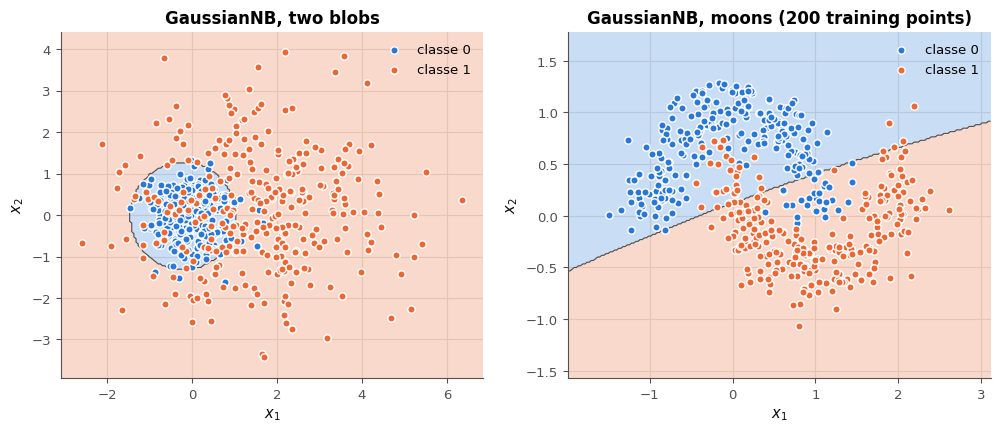

✅ Ex 13.27a : C'est ça !
✅ Ex 13.27b : Parfait !
✅ Ex 13.27c : Bravo !


In [67]:
if any(answer is ... or answer is None for answer in [surround_27, moons_27, more_data_27]):
    print("⏳ Ex 13.27 : écris d'abord tes trois prédictions, puis relance cette cellule.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    blobs_27 = GaussianNB().fit(X_BLOBS_27, Y_BLOBS_27)
    wb.plot.plot_decision_boundary(blobs_27, X_BLOBS_27, Y_BLOBS_27, ax=axes[0], title="GaussianNB, two blobs")
    for n in [50, 200, 5000]:
        accuracies = []
        for r in range(10):                                   # 10 draws: n training points, 2,000 test points
            X, y = wb.synth.make_moons(n=n + 2000, noise=0.2, seed=1327 + r)
            accuracies.append(GaussianNB().fit(X[:n], y[:n]).score(X[n:], y[n:]))
        print(f"moons, {n:4d} training points: mean test accuracy {np.mean(accuracies):.3f} "
              f"(from {min(accuracies):.3f} to {max(accuracies):.3f})")
    X_moons_27, Y_moons_27 = wb.synth.make_moons(n=2200, noise=0.2, seed=1327)
    wb.plot.plot_decision_boundary(GaussianNB().fit(X_moons_27[:200], Y_moons_27[:200]), X_moons_27[200:700],
                                   Y_moons_27[200:700], ax=axes[1], title="GaussianNB, moons (200 training points)")
    plt.show()
    wb.check("13.27a", surround_27)
    wb.check("13.27b", moons_27)
    wb.check("13.27c", more_data_27)

Dans tes notes : compare avec tes prédictions. Sur les blobs, pourquoi la frontière a-t-elle cette forme ? Sur les lunes, quelles erreurs restent, et que font les données en plus ? Les erreurs viennent-elles du biais ou de la variance ?

💡 Sur les blobs, Naïve Bayes trace une courbe **fermée autour de la classe 0**, la plus resserrée : loin des deux centres, la gaussienne large (classe 1) décroît bien moins vite que l'étroite, et l'emporte dans toutes les directions ; c'est la version 2D des deux seuils de la figure de la fiche. Sur les lunes, l'accuracy moyenne vaut 0,863 avec 50 points, 0,864 avec 200 et 0,871 avec 5 000 : chaque classe est résumée par une gaussienne aux axes parallèles aux coordonnées, et la frontière quadratique coupe les deux pointes recourbées des lunes. Des données en plus estiment mieux les 8 paramètres, mais le modèle reste le même : c'est une erreur de **biais**, pas de variance.

### Ex 13.28 — Coder GaussianNB avec log-densités et logsumexp 🔨 ★★★ ⏱️ 40 min
**Objectif :** écrire Naïve Bayes gaussien entièrement en log-probabilités, sans jamais multiplier des probabilités.  
**Prérequis :** ✏️ 13.7 · ch. 4 (règle de Bayes, logsumexp en 4.18) · ch. 2 (loi normale) · fiche §13.6 · **Fil rouge :** Penguins · **mylearn :** `naive_bayes.py` · **Parcours :** M, C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/naive_bayes.py` (créé par `python tools/start_chapter.py 13`), lis la docstring de chaque fonction et de chaque méthode, remplace les `raise NotImplementedError(...)` par ton code et **enregistre**. NumPy seulement : scikit-learn et SciPy sont les **oracles** des tests. La cellule de vérification recharge ta librairie, compare quelques résultats à scikit-learn, puis lance les tests de l'exercice ; `python -m pytest tests/test_ch13_naive_bayes.py -q` les lance tous dans un terminal.

Écris `log_gaussian_pdf`, `logsumexp` et la classe `GaussianNB`. **Contrat** (les docstrings, plus ces précisions que vérifient les tests) :
- `log_gaussian_pdf(x, mean, var)` rend, élément par élément et avec le broadcasting, $-\frac12 \log(2\pi\sigma^2) - \frac{(x - \mu)^2}{2\sigma^2}$, sans passer par l'exponentielle (le résultat reste fini loin de la moyenne) ; `ValueError` si une variance est négative ou nulle ; la fonction ne modifie pas ses arguments ;
- `logsumexp(a, axis=-1)` rend $\log \sum e^{a}$ le long de l'axe (qui disparaît), sans dépassement ni sous-dépassement, même pour des valeurs autour de ±1 000 ; un `-np.inf` parmi des valeurs finies compte pour 0 dans la somme ; ne modifie pas `a` ;
- `GaussianNB(var_smoothing=1e-9, priors=None)` : `__init__` range ses deux arguments ; `fit(X, y)` apprend `classes_` (triés), `class_count_`, `class_prior_` (les fréquences des classes, ou `priors` s'il est donné), `theta_` (les moyennes par classe) et `var_` (les variances par classe, ddof = 0, **plus** `epsilon_`), avec `epsilon_` = `var_smoothing` × la plus grande variance des features calculée sur tout `X`, et renvoie `self` ; un second `fit` oublie le premier ; `fit` ne modifie pas ses arguments ;
- `predict_joint_log_proba(X)` rend la matrice `(n, K)` des $\log P(c) + \sum_j \log \mathcal{N}(x_j ; \theta_{cj}, \sigma^2_{cj})$ ; `predict_log_proba` la normalise avec **ton** `logsumexp` ; `predict_proba` en prend l'exponentielle ; `predict` rend la classe de plus grand posterior ; `score` l'accuracy, un `float` Python ;
- erreurs : `ValueError` si `X` n'est pas 2-D ou contient `NaN` (comme scikit-learn), si `len(X) != len(y)`, ou si `priors` n'a pas une valeur positive ou nulle par classe, de somme 1 à $10^{-6}$ près ; `RuntimeError` si `predict_joint_log_proba` est appelée avant `fit` (les autres méthodes passent par elle).

La vérification essaie les exemples des docstrings, compare tes moyennes, tes variances et tes posteriors à ceux de scikit-learn sur les manchots, montre ce que donnerait le produit des probabilités sur les 784 pixels de MNIST, puis lance les tests.

Dans tes notes : sur MNIST, pourquoi le produit des probabilités donne-t-il `nan` ? À quoi sert `epsilon_` (pense à un pixel toujours noir dans une classe) ? Pourquoi Naïve Bayes gaussien classe-t-il si mal les chiffres, comparé à un kNN ?

In [68]:
with checked("13.28"):
    doc_28 = mylearn.naive_bayes.log_gaussian_pdf(np.array([0.0, 1.0]), 0.0, 1.0)
    if returned("13.28", "log_gaussian_pdf", doc_28):
        print("docstring example: log_gaussian_pdf([0, 1], 0, 1) =", np.round(np.asarray(doc_28, dtype=float), 4).tolist(),
              "(expected [-0.9189, -1.4189])")
with checked("13.28"):
    lse_28 = mylearn.naive_bayes.logsumexp(np.array([-1000.0, -1000.0]))
    if returned("13.28", "logsumexp", lse_28):
        print("docstring example: logsumexp([-1000, -1000]) =", round(float(lse_28), 4), "(expected -999.3069)")
with checked("13.28"):
    X_train_28, y_train_28 = P_TRAIN[MEASURES].to_numpy(), P_TRAIN["species"].to_numpy()
    X_test_28 = P_TEST[MEASURES].to_numpy()
    mine_28 = fitted(mylearn.naive_bayes.GaussianNB(), X_train_28, y_train_28)
    oracle_28 = GaussianNB().fit(X_train_28, y_train_28)
    proba_28 = mine_28.predict_proba(X_test_28)
    if returned("13.28", "predict_proba", proba_28):
        verdict("13.28", np.allclose(mine_28.theta_, oracle_28.theta_) and np.allclose(mine_28.var_, oracle_28.var_)
                and np.allclose(proba_28, oracle_28.predict_proba(X_test_28)),
                f"manchots : mêmes moyennes, mêmes variances et mêmes posteriors que scikit-learn (accuracy de test "
                f"{fr(oracle_28.score(X_test_28, P_TEST['species']))}).",
                "manchots : tes moyennes, tes variances ou tes posteriors diffèrent de ceux de scikit-learn ; les tests "
                "ci-dessous disent où.")
with checked("13.28"):
    X_mnist_28, y_mnist_28 = wb.datasets.load_mnist("train", n=3000, flatten=True, seed=1328)
    X_mnist_28 = X_mnist_28 / 255.0
    digits_28 = fitted(mylearn.naive_bayes.GaussianNB(), X_mnist_28[:2500], y_mnist_28[:2500])
    joint_28 = np.asarray(digits_28.predict_joint_log_proba(X_mnist_28[2500:]), dtype=float)
    with np.errstate(divide="ignore", invalid="ignore", over="ignore", under="ignore"):
        products_28 = np.exp(joint_28)                                    # what multiplying probabilities gives
        naive_28 = products_28 / products_28.sum(axis=1, keepdims=True)
    print(f"MNIST, 784 pixels: joint log-probabilities from {joint_28.min():.3g} to {joint_28.max():.3g}")
    print(f"multiply, then normalise: {int(np.isnan(naive_28).any(axis=1).sum())} of the 500 test images get nan")
    digits_proba_28 = digits_28.predict_proba(X_mnist_28[2500:])
    if returned("13.28", "predict_proba", digits_proba_28):
        digits_proba_28 = np.asarray(digits_proba_28, dtype=float)
        verdict("13.28", np.isfinite(digits_proba_28).all() and np.allclose(digits_proba_28.sum(axis=1), 1),
                f"en log-probabilités avec logsumexp : aucune image sans posterior (accuracy "
                f"{fr(digits_28.score(X_mnist_28[2500:], y_mnist_28[2500:]))}).",
                "tes posteriors contiennent des nan ou ne somment pas à 1 : normalise les log-probabilités jointes "
                "avec logsumexp avant de prendre l'exponentielle.")
if written(lambda: mylearn.naive_bayes.log_gaussian_pdf(0.0, 0.0, 1.0)):
    run_mylearn_tests(impl="ref", module="naive_bayes", keyword="test_log_gaussian_pdf_ or test_logsumexp_ or test_gaussian_nb_")
else:
    print("⏳ Ex 13.28 : les tests attendent ton log_gaussian_pdf.")

docstring example: log_gaussian_pdf([0, 1], 0, 1) = [-0.9189, -1.4189] (expected [-0.9189, -1.4189])
docstring example: logsumexp([-1000, -1000]) = -999.3069 (expected -999.3069)
✅ Ex 13.28 : manchots : mêmes moyennes, mêmes variances et mêmes posteriors que scikit-learn (accuracy de test 0,960).


MNIST, 784 pixels: joint log-probabilities from -9.45e+10 to 4.56e+03
multiply, then normalise: 500 of the 500 test images get nan
✅ Ex 13.28 : en log-probabilités avec logsumexp : aucune image sans posterior (accuracy 0,552).


pytest: 53 passed, 21 deselected in 0.73s


💡 Sur MNIST, les log-probabilités jointes vont d'environ $-10^{11}$ à $+4\,560$ : un pixel presque constant dans une classe a une variance minuscule (de l'ordre de `epsilon_`), si bien que sa densité est énorme (log-densité très positive) quand le pixel a sa valeur habituelle, et infime dès qu'il s'en écarte. L'exponentielle déborde vers `inf` pour la meilleure classe et vaut 0 pour les autres : la normalisation calcule inf/inf = `nan` (0/0 quand tout sous-déborde). logsumexp retire d'abord le maximum, si bien que la meilleure classe garde $e^0 = 1$. `epsilon_` évite une variance nulle (une division par zéro) pour un pixel toujours noir. Naïve Bayes classe mal les chiffres (autour de 0,55) : les pixels voisins sont très dépendants, et une gaussienne par pixel décrit mal des valeurs presque toujours 0 ou 1.

### Ex 13.29 — Coder MultinomialNB avec lissage 🔨 ★★ ⏱️ 30 min
**Objectif :** écrire Naïve Bayes multinomial pour des comptes, avec le lissage de Laplace.  
**Prérequis :** ✏️ 13.6 · Ex 13.28 · fiche §13.6 (lissage) · **Fil rouge :** Holmes/Verne · **mylearn :** `naive_bayes.py` · **Parcours :** C

> **mylearn** : dans `mon_travail/mylearn/naive_bayes.py`, mêmes règles qu'en 13.28. Enregistre, puis relance la cellule de vérification.

Écris la classe `MultinomialNB`. **Contrat** (la docstring, plus ces précisions que vérifient les tests) :
- `MultinomialNB(alpha=1.0, fit_prior=True)` : `__init__` range ses deux arguments ; `fit(X, y)` reçoit des **comptes** (positifs ou nuls) et apprend `classes_` (triés), `class_count_`, `feature_count_` (la matrice `(K, d)` des comptes totaux $N_{cj}$ de chaque feature dans chaque classe), `class_log_prior_` (le log des fréquences des classes, ou $-\log K$ partout si `fit_prior=False`) et `feature_log_prob_` $= \log \frac{N_{cj} + \alpha}{N_c + \alpha d}$, puis renvoie `self` ; un second `fit` oublie le premier ; `fit` ne modifie pas ses arguments ;
- `alpha=0` est permis : les fréquences brutes (un compte nul donne $\log 0 = -\infty$) ;
- `predict_joint_log_proba(X)` $=$ `X @ feature_log_prob_.T + class_log_prior_` ; `predict_log_proba`, `predict_proba`, `predict` et `score` comme pour `GaussianNB` (avec ton `logsumexp`) : des documents très longs ne donnent ni `nan` ni 0 partout ;
- erreurs : `ValueError` si `X` a une valeur négative ou `NaN`, n'est pas 2-D, si `len(X) != len(y)`, ou si `alpha < 0` ; `RuntimeError` si `predict_joint_log_proba` est appelée avant `fit`.

Les données : Holmes (anglais, `"en"`) et Verne (français, `"fr"`) découpés en morceaux de quelques caractères ; chaque morceau devient les 26 comptes de ses lettres a à z (`letter_counts`). La vérification essaie l'exemple de la docstring, compare tes probabilités à celles de scikit-learn sur des morceaux de 20 caractères, mesure ton accuracy pour quatre longueurs de morceaux, puis lance les tests.

Dans tes notes : comment l'accuracy varie-t-elle avec la longueur des morceaux, et pourquoi ? Sans lissage, qu'arriverait-il à un morceau anglais qui contient une lettre absente de tous les morceaux français d'entraînement (si le « w », rare en français, n'y apparaissait jamais, par exemple) ?

In [69]:
def letter_counts(text, size):
    """(n_chunks, 26): the counts of the letters a to z in the consecutive chunks of `size` characters of the text
    (lower-cased; the other characters, accented letters included, are ignored)."""
    text = text.lower()
    n_chunks = len(text) // size
    codes = np.frombuffer(text[:n_chunks * size].encode("utf-32-le"), dtype=np.uint32).reshape(n_chunks, size)
    return np.stack([(codes == ord("a") + j).sum(axis=1) for j in range(26)], axis=1)


HOLMES_29, VERNE_29 = wb.datasets.load_holmes(), wb.datasets.load_verne()


def chunks_29(size):
    """Training and test parts (70/30) of the chunks of `size` characters of Holmes ("en") and Verne ("fr")."""
    english, french = letter_counts(HOLMES_29, size), letter_counts(VERNE_29, size)
    X = np.vstack([english, french])
    y = np.array(["en"] * len(english) + ["fr"] * len(french))
    return train_test_split(X, y, test_size=0.3, random_state=1329, stratify=y)

In [70]:
with checked("13.29"):
    X_doc_29 = np.array([[2, 1, 0], [3, 0, 1], [0, 2, 3], [1, 0, 4]])
    doc_29 = fitted(mylearn.naive_bayes.MultinomialNB(alpha=1.0), X_doc_29, np.array(["en", "en", "fr", "fr"]))
    print("docstring example: P(feature | class) =", np.round(np.exp(doc_29.feature_log_prob_), 4).tolist(),
          "(expected [[0.6, 0.2, 0.2], [0.1538, 0.2308, 0.6154]])")
with checked("13.29"):
    X_train_29, X_test_29, y_train_29, y_test_29 = chunks_29(20)
    mine_29 = fitted(mylearn.naive_bayes.MultinomialNB(), X_train_29, y_train_29)
    oracle_29 = MultinomialNB(alpha=1.0, force_alpha=True).fit(X_train_29, y_train_29)
    verdict("13.29", np.allclose(mine_29.feature_log_prob_, oracle_29.feature_log_prob_)
            and np.allclose(mine_29.predict_proba(X_test_29), oracle_29.predict_proba(X_test_29)),
            f"morceaux de 20 caractères : mêmes probabilités que scikit-learn ({len(X_train_29)} morceaux "
            "d'entraînement).",
            "morceaux de 20 caractères : tes probabilités diffèrent de celles de scikit-learn ; les tests ci-dessous "
            "disent où.")
    for size in [10, 20, 50, 200]:
        X_tr, X_te, y_tr, y_te = chunks_29(size)
        model = fitted(mylearn.naive_bayes.MultinomialNB(), X_tr, y_tr)
        print(f"chunks of {size:3d} characters: test accuracy {model.score(X_te, y_te):.4f} ({len(X_te)} test chunks)")
if written(lambda: mylearn.naive_bayes.MultinomialNB().fit(np.array([[1, 0], [0, 1]]), np.array([0, 1]))):
    run_mylearn_tests(impl="ref", module="naive_bayes", keyword="test_multinomial_nb_")
else:
    print("⏳ Ex 13.29 : les tests attendent le fit de ton MultinomialNB.")

docstring example: P(feature | class) = [[0.6, 0.2, 0.2], [0.1538, 0.2308, 0.6154]] (expected [[0.6, 0.2, 0.2], [0.1538, 0.2308, 0.6154]])
✅ Ex 13.29 : morceaux de 20 caractères : mêmes probabilités que scikit-learn (34423 morceaux d'entraînement).


chunks of  10 characters: test accuracy 0.7704 (29506 test chunks)
chunks of  20 characters: test accuracy 0.8640 (14753 test chunks)
chunks of  50 characters: test accuracy 0.9524 (5901 test chunks)
chunks of 200 characters: test accuracy 0.9993 (1476 test chunks)


pytest: 21 passed, 53 deselected in 0.82s


💡 Avec 10 caractères (environ 8 lettres), un morceau sur quatre est mal classé (0,77) ; avec 20, 0,86 ; avec 50, 0,95 ; avec 200, presque tous (0,999). Chaque lettre apporte un petit indice, et les log-probabilités s'additionnent : plus il y a de lettres, plus le total sépare les deux langues. Sans lissage, une lettre absente d'une classe à l'entraînement y reçoit une probabilité nulle : si le « w » n'apparaissait dans aucun morceau français, un seul « w » rendrait la classe française impossible ($\log 0 = -\infty$), quel que soit le reste du morceau. Chez Verne, il apparaît tout de même 248 fois, si bien qu'ici aucun compte n'est nul.

### Ex 13.30 — Dialogue ou narration ? Classer des phrases de Holmes : sac de mots, TF-IDF et Naïve Bayes 📦 ★★★ ⏱️ 40 min
**Objectif :** classer des textes avec un sac de mots, et lire ce que le modèle a appris.  
**Prérequis :** Ex 13.12 · ch. 6 (fréquences) · ch. 3 (accuracy, classe majoritaire) · fiche §13.6 (Naïve Bayes sur des textes) · **Fil rouge :** Holmes/Verne · **Parcours :** R, C

La cellule suivante découpe les nouvelles de Holmes en phrases et donne à chacune un label : 1 (**dialogue**) si toutes ses lettres sont entre guillemets « “ » et « ” », 0 (**narration**) si aucune ne l'est ; les phrases qui mêlent les deux sont écartées, et les guillemets retirés du texte : le modèle doit reconnaître le dialogue à ses **mots**. 70 % des phrases servent à l'entraînement. Avec `make_pipeline`, calcule :
a) `dialogue_share_30` : la part des phrases de dialogue parmi toutes les phrases ;
b) `baseline_30` : l'accuracy de test d'un modèle qui prédit toujours la classe majoritaire de l'entraînement ;
c) `count_nb_30` : l'accuracy de test de `make_pipeline(CountVectorizer(), MultinomialNB())` entraîné sur `S_TRAIN_30` ;
d) `tfidf_nb_30` : la même chose avec `TfidfVectorizer()` à la place de `CountVectorizer()` ;
e) `tfidf_lr_30` : la même chose avec `TfidfVectorizer()` et `LogisticRegression(max_iter=1000)` ;
f) `top_dialogue_30` : les 5 mots qui ont le plus grand écart `feature_log_prob_[1] - feature_log_prob_[0]` dans le pipeline de c) (une liste de chaînes, dans n'importe quel ordre ; `get_feature_names_out()` donne les mots).

Dans tes notes : pourquoi le dialogue est-il si majoritaire dans Holmes (pense à qui raconte les affaires) ? Que vaut c) comparé à b) ? Pourquoi TF-IDF fait-il **moins bien** avec Naïve Bayes qu'avec la régression logistique (regarde ce que deviennent les « comptes » d'une phrase, et le poids du prior) ? Les mots de f) te surprennent-ils ?

In [71]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import make_pipeline


def holmes_sentences():
    """The sentences of Holmes, each labelled 1 (dialogue: all its letters between “ and ”) or 0 (narration: none of
    them); the sentences that mix both, or have fewer than 4 words, are left out, and the quotes are removed."""
    text = wb.datasets.load_holmes()
    text = text[text.index("To Sherlock Holmes she is always"):]           # skip the title and the contents
    boundary = re.compile(r"(?:(?<=[.!?])|(?<=[.!?]”))\s+")                # a space after . ! or ?, possibly after ”
    sentences, labels = [], []
    for paragraph in re.split(r"\n\s*\n", text):
        paragraph = paragraph.replace("\n", " ").strip()
        if len(paragraph.split()) < 4 or paragraph.isupper():              # headings
            continue
        inside, state = np.zeros(len(paragraph), dtype=bool), False        # a paragraph starts outside the quotes
        for i, char in enumerate(paragraph):
            if char == "“":
                state = True
            inside[i] = state
            if char == "”":
                state = False
        start = 0
        for piece in boundary.split(paragraph):
            start = paragraph.index(piece, start)
            letters = [inside[i] for i in range(start, start + len(piece)) if paragraph[i].isalpha()]
            start += len(piece)
            clean = piece.replace("“", "").replace("”", "").strip()
            if len(clean.split()) >= 4 and letters and (all(letters) or not any(letters)):
                sentences.append(clean)
                labels.append(int(all(letters)))
    return sentences, np.array(labels)


SENTENCES_30, LABELS_30 = holmes_sentences()
S_TRAIN_30, S_TEST_30, Y_TRAIN_30, Y_TEST_30 = train_test_split(SENTENCES_30, LABELS_30, test_size=0.3,
                                                                random_state=1330, stratify=LABELS_30)
print(len(SENTENCES_30), "sentences, for example:")
for label in (1, 0):
    for k in np.flatnonzero(LABELS_30 == label)[:2]:
        print(f"  {label}  {SENTENCES_30[k][:100]}")

5633 sentences, for example:
  1  I think, Watson, that you have put on seven and a half pounds since I saw you.
  1  Indeed, I should have thought a little more.
  0  To Sherlock Holmes she is always _the_ woman.
  0  I have seldom heard him mention her under any other name.


In [72]:
dialogue_share_30 = float(LABELS_30.mean())
majority_30 = int(Y_TRAIN_30.mean() > 0.5)
baseline_30 = float(np.mean(Y_TEST_30 == majority_30))
count_pipe_30 = make_pipeline(CountVectorizer(), MultinomialNB()).fit(S_TRAIN_30, Y_TRAIN_30)
count_nb_30 = count_pipe_30.score(S_TEST_30, Y_TEST_30)
tfidf_nb_30 = make_pipeline(TfidfVectorizer(), MultinomialNB()).fit(S_TRAIN_30, Y_TRAIN_30).score(S_TEST_30, Y_TEST_30)
tfidf_lr_30 = make_pipeline(TfidfVectorizer(), LogisticRegression(max_iter=1000)).fit(S_TRAIN_30, Y_TRAIN_30).score(S_TEST_30, Y_TEST_30)
vocabulary_30 = count_pipe_30[0].get_feature_names_out()
ratio_30 = count_pipe_30[1].feature_log_prob_[1] - count_pipe_30[1].feature_log_prob_[0]
top_dialogue_30 = [str(word) for word in vocabulary_30[np.argsort(ratio_30)[::-1][:5]]]
print("narration words:", [str(word) for word in vocabulary_30[np.argsort(ratio_30)[:10]]])
print("vocabulary:", len(vocabulary_30), "words")
print_answer("13.30a", dialogue_share_30)
print_answer("13.30b", baseline_30)
print_answer("13.30c", count_nb_30)
print_answer("13.30d", tfidf_nb_30)
print_answer("13.30e", tfidf_lr_30)
print_answer("13.30f", top_dialogue_30)

narration words: ['expression', 'visitor', 'banker', 'sherlock', 'veil', 'onto', 'powers', 'discoloured', 'buried', 'shoulders']
vocabulary: 6466 words
13.30a: 0.8203443990768684
13.30b: 0.8201183431952662
13.30c: 0.8970414201183432
13.30d: 0.8337278106508875
13.30e: 0.8881656804733727
13.30f: ['you', 'your', 'will', 'are', 'can']


In [73]:
wb.record("13.30a", dialogue_share_30, decimals=4,
          mistakes={"c'est la part de la narration : le label 1 est le dialogue": 1 - dialogue_share_30,
                    "c'est la part dans l'entraînement seulement : on la demande parmi TOUTES les phrases (LABELS_30)": float(Y_TRAIN_30.mean()),
                    "c'est la part dans le test seulement : on la demande parmi TOUTES les phrases (LABELS_30)": float(Y_TEST_30.mean())})
wb.record("13.30b", baseline_30, decimals=4,
          mistakes={"c'est l'accuracy de la classe minoritaire : prédis toujours la classe la plus fréquente": 1 - baseline_30,
                    "c'est l'accuracy de la baseline sur l'entraînement : mesure-la sur Y_TEST_30": float(np.mean(Y_TRAIN_30 == majority_30))})
wb.record("13.30c", count_nb_30, decimals=4,
          mistakes={"c'est l'accuracy d'entraînement : mesure-la sur S_TEST_30": count_pipe_30.score(S_TRAIN_30, Y_TRAIN_30)})
wb.record("13.30d", tfidf_nb_30, decimals=4)
wb.record("13.30e", tfidf_lr_30, decimals=4)
frequent_30 = [str(word) for word in vocabulary_30[np.argsort(count_pipe_30[1].feature_log_prob_[1])[::-1][:5]]]
wb.record("13.30f", top_dialogue_30, ordered=False,
          mistakes={"ce sont les mots les plus caractéristiques de la narration : garde les plus grands écarts, pas les plus petits": [str(word) for word in vocabulary_30[np.argsort(ratio_30)[:5]]],
                    "ce sont les mots les plus fréquents du dialogue, pas les plus caractéristiques : compare les deux classes (l'écart des log-probabilités)": frequent_30})

WB_ANSWER {"decimals": 4, "hash": "5f46bf67fb0ad9b55b80c2e15cd7b6754eac3082885bf9243e87e0dac26437ab", "hash_coarse": "4c5cd28b0a8a0d6d6b8934399a06842243d127229bc0a3ad598af060f946a786", "id": "13.30a", "kind": "float", "magnitude": -1, "mistakes": {"42266faea4ef65da4b3d31fcdf407546fd76e9c0044e0444d487d699970f18f3": "c'est la part de la narration : le label 1 est le dialogue", "532d9664ee7336f530a79d9c9f92a78996446eda63de1a9919d740ddf3ef416b": "c'est la part dans le test seulement : on la demande parmi TOUTES les phrases (LABELS_30)", "c9b553bca72d9d7f792c57fab05ef59b373671919ebab721f266f67256235518": "c'est la part dans l'entraînement seulement : on la demande parmi TOUTES les phrases (LABELS_30)"}, "sign": 1}
📝 Ex 13.30a : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"decimals": 4, "hash": "19de3ad76e170cae20e2d44cfc59b865161e90d9be6e7f7bfa43c22a031aa8c3", "hash_coarse": "6e3db578997d888d0c20d08b55ac3f3e6def16e914433c02f29c20fe55c3bc23", "id": "13.30b", "kind": "float", "magn

💡 Le dialogue fait 82 % des phrases : chez Conan Doyle, les clients racontent leur affaire entre guillemets, souvent pendant des pages, et Holmes expose ses déductions de même. Une baseline à la classe majoritaire fait donc déjà 0,820 ; le sac de mots avec Naïve Bayes monte à 0,897, une erreur presque divisée par deux. Avec TF-IDF, Naïve Bayes retombe à 0,834 : chaque phrase devient un vecteur normalisé dont les « comptes » sont des fractions, si bien que la somme $\sum_j x_j \log P(j \mid c)$ ne pèse presque plus face au log du prior, et le modèle prédit presque toujours la classe majoritaire. La régression logistique, qui apprend un poids par mot sans hypothèse de comptes, fait 0,888 avec les mêmes vecteurs. Les mots du dialogue sont ceux de la deuxième personne et du présent (« you », « your », « will », « are », « can ») ; ceux de la narration décrivent la scène, vue par Watson.

## Partie E · La régression logistique

Le classifieur paramétrique de référence, absent du livre à ce chapitre : celui de scikit-learn, ses coefficients et ses probabilités (13.31), puis le tien, dans `mylearn/logistic.py` (13.32). Les deux exercices séparent les Adélie des Chinstrap ; la cellule suivante garde ces 214 manchots et les découpe (70/30).

In [74]:
# Adélie or Chinstrap? The 214 penguins of these two species (70 % for training, 30 % for testing)
AC_PENGUINS = PENGUINS[PENGUINS["species"].isin(["Adelie", "Chinstrap"])]
AC_TRAIN, AC_TEST = train_test_split(AC_PENGUINS, test_size=0.3, random_state=1331, stratify=AC_PENGUINS["species"])
print(len(AC_TRAIN), "training penguins,", len(AC_TEST), "test penguins")

149 training penguins, 65 test penguins


### Ex 13.31 — Régression logistique scikit-learn : coefficients et probabilités 📦 ★★ ⏱️ 25 min
**Objectif :** lire les coefficients d'une régression logistique en odds, et voir l'effet de sa pénalité par défaut.  
**Prérequis :** Ex 13.12 · ch. 12 (standardisation) · fiche « Au-delà du livre : la régression logistique » · **Fil rouge :** Penguins · **Parcours :** R, C

Les 4 mesures des manchots Adélie et Chinstrap, standardisées sur l'entraînement (`Z_TRAIN_31`). Avec `LogisticRegression` de scikit-learn, calcule :
- `model_31` : `LogisticRegression()`, avec ses réglages par défaut, entraîné sur `Z_TRAIN_31`, `Y_TRAIN_31` ;
- a) `coef_31` : ses 4 coefficients, dans l'ordre de `MEASURES` ;
- b) `odds_31` : le facteur qui multiplie les **odds** $P(\text{Chinstrap}) / P(\text{Adélie})$ quand la longueur du bec augmente d'un écart-type, les autres mesures restant fixes ;
- c) `proba_31` : la probabilité que le nouveau manchot `NEW_31` (mesures brutes : bec de 45 mm de long et 17,5 mm d'épaisseur, nageoires de 195 mm, 3 700 g) soit un Chinstrap ;
- d) `norms_31` : la liste `[‖coef‖ avec C = 1, ‖coef‖ avec C = 100]` de `LogisticRegression(C=C, max_iter=10_000)`.

Dans tes notes : quelle mesure compte le plus, et le signe de chaque coefficient te paraît-il logique (compare les moyennes des deux espèces) ? Que fait C, et que se passe-t-il avec `C=np.inf` sur ces données (essaie : regarde la norme et l'accuracy d'entraînement) ? Pourquoi standardiser avant de comparer des coefficients ?

In [75]:
SCALER_31 = StandardScaler().fit(AC_TRAIN[MEASURES])
Z_TRAIN_31, Z_TEST_31 = SCALER_31.transform(AC_TRAIN[MEASURES]), SCALER_31.transform(AC_TEST[MEASURES])
Y_TRAIN_31, Y_TEST_31 = AC_TRAIN["species"].to_numpy(), AC_TEST["species"].to_numpy()
NEW_31 = pd.DataFrame([[45.0, 17.5, 195.0, 3700.0]], columns=MEASURES)   # a new penguin, raw measures

In [76]:
model_31 = LogisticRegression().fit(Z_TRAIN_31, Y_TRAIN_31)
coef_31 = model_31.coef_[0]
odds_31 = float(np.exp(coef_31[0]))
proba_31 = float(model_31.predict_proba(SCALER_31.transform(NEW_31))[0, 1])     # classes_ = [Adelie, Chinstrap]
norms_31 = [float(np.linalg.norm(LogisticRegression(C=C, max_iter=10_000).fit(Z_TRAIN_31, Y_TRAIN_31).coef_))
            for C in (1, 100)]
print("classes_:", model_31.classes_.tolist(), "· test accuracy:", model_31.score(Z_TEST_31, Y_TEST_31))
with warnings.catch_warnings():
    warnings.simplefilter("ignore")                       # no penalty: the solver may warn
    unpenalized_31 = LogisticRegression(C=np.inf, max_iter=10_000).fit(Z_TRAIN_31, Y_TRAIN_31)
print("C = inf: ||coef|| =", round(float(np.linalg.norm(unpenalized_31.coef_)), 1), "· training accuracy:",
      unpenalized_31.score(Z_TRAIN_31, Y_TRAIN_31))
print_answer("13.31a", coef_31)
print_answer("13.31b", odds_31)
print_answer("13.31c", proba_31)
print_answer("13.31d", norms_31)

classes_: ['Adelie', 'Chinstrap'] · test accuracy: 0.9692307692307692
C = inf: ||coef|| = 105.2 · training accuracy: 1.0
13.31a: [3.8934, -0.6898, -0.0313, -0.8427]
13.31b: 49.07525210258625
13.31c: 0.7207076667832494
13.31d: [4.0429, 14.4217]


In [77]:
wb.record("13.31a", coef_31, decimals=3)
wb.record("13.31b", odds_31, decimals=4,
          mistakes={"c'est le coefficient lui-même : il s'ajoute au log des odds, et multiplie donc les odds par son exponentielle": float(coef_31[0]),
                    "c'est le facteur des odds de l'Adélie : classes_ est trié, et la classe 1 est le Chinstrap": float(np.exp(-coef_31[0]))})
raw_31 = float(model_31.predict_proba(NEW_31.to_numpy())[0, 1])
wb.record("13.31c", proba_31, decimals=4,
          mistakes={"c'est la probabilité de l'Adélie : la colonne 1 de predict_proba est classes_[1], le Chinstrap": 1 - proba_31,
                    "NEW_31 contient des mesures brutes : le modèle attend des mesures standardisées par SCALER_31": raw_31})
wb.record("13.31d", norms_31, decimals=4, mistakes={"l'ordre demandé est [C = 1, C = 100]": norms_31[::-1]})

WB_ANSWER {"decimals": 3, "element_coarse": [["a8a10b1e890ff2b2ee63f25509a48d9335c1242e92666d544e1d9dfedc5baefd"], ["78744f80f2cb4b13989473d68db36c64e496e382a84c5808a83a3a2372e3ce7a"], ["ec97453e9adb03a974ecb1fc2702edfb04265fc37a870ad54cd645360366f239"], ["e6913489d786c7e483448c853a81fe62268c1eccecceaf82118c8024532771b4"]], "element_hashes": ["14392e0e06fa4d54646c8bef80312c483c2d0784f9cd2e5db64656c0d97dc617", "9b0cce94495fd2070e38ec1fa736bcb9f6342dc8b58d22eec9043df4be013767", "67ecd77d7569fa4b6fff58007526a4ac10e60ca53e7de01a44f2d67667788b3f", "de69ac24dd4cfc94f97430149d869b57f38c00cf15bbe9887c080d23546f832f"], "hash": "b0cd6b2937edf5e06ae2832fcbcb49df0cacee481c33fc2077e5ba2c4d66fa6d", "id": "13.31a", "kind": "array", "shape": [4]}
📝 Ex 13.31a : réponse enregistrée (array, 3 décimale(s)).
WB_ANSWER {"decimals": 4, "hash": "7367eabe43e4da2b5d99883e4c40649bca9ffc2606100596ab91d2b2b23020b7", "hash_coarse": "cc9156bee66fd60ba0d870679a79af41d3f3a404f523bad90105d5743dd008ce", "id": "13.31b", 

💡 La longueur du bec domine (coefficient d'environ 3,9) : les Chinstrap ont un bec bien plus long que les Adélie ; un écart-type de bec en plus multiplie les odds du Chinstrap par environ 49. Les autres coefficients sont négatifs et plus petits : à longueur de bec égale, un manchot plus lourd ou au bec plus épais est plutôt un Adélie, et les nageoires ne comptent presque pas. Ce sont des effets **à bec égal** : en moyenne, les Chinstrap sont même un peu plus lourds (3 733 g contre 3 706 g) ; ces mesures sont corrélées à la longueur du bec, et leur coefficient ne dit que ce qu'elles ajoutent à celle-ci. Le nouveau manchot, au bec long mais assez lourd, est un Chinstrap à 72 %. C est l'inverse de la force de la pénalité : avec $C = 100$, la norme des coefficients est multipliée par 3,6 environ. Sur ces données, les deux espèces sont **séparables** par un hyperplan des 4 mesures : sans pénalité (`C=np.inf`), la log-loss baisse toujours quand $\lVert\mathbf{w}\rVert$ grandit, et le solveur s'arrête seulement à sa tolérance, avec une norme de l'ordre de 100 et une accuracy d'entraînement de 1. Standardiser met les coefficients dans la même unité (un écart-type) : sans cela, celui de la masse (en grammes) serait minuscule sans être moins important.

### Ex 13.32 — Coder la régression logistique par descente de gradient 🔨 ★★★ ⏱️ 50 min
**Objectif :** écrire la régression logistique et sa descente de gradient, et retrouver exactement scikit-learn.  
**Prérequis :** ∂ 13.8 · ch. 5 (descente de gradient) · ch. 6 (log-loss, `info.log_loss`) · ch. 12 (standardisation) · fiche « Au-delà du livre : la régression logistique » · **Fil rouge :** Penguins · **mylearn :** `logistic.py` · **Parcours :** M, C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/logistic.py` (créé par `python tools/start_chapter.py 13`), lis la docstring de chaque fonction et de chaque méthode, remplace les `raise NotImplementedError(...)` par ton code et **enregistre**. NumPy seulement : scikit-learn et SciPy sont les **oracles** des tests. La cellule de vérification recharge ta librairie, compare quelques résultats à scikit-learn, puis lance les tests de l'exercice ; `python -m pytest tests/test_ch13_logistic.py -q` les lance tous dans un terminal.

Écris la classe `LogisticRegression` (`sigmoid` est fournie). **Contrat** (la docstring, plus ces précisions que vérifient les tests) :
- `__init__(alpha=0.0, learning_rate=0.1, max_iter=1000, tol=1e-6, fit_intercept=True)` range ses arguments tels quels ;
- `fit(X, y)` code les labels par `classes_` (les deux labels distincts triés : `classes_[0]` → 0, `classes_[1]` → 1), part de $\mathbf{w} = \mathbf{0}$ et $b = 0$, et minimise $J(\mathbf{w}, b) =$ `log_loss(y, p)` $+ \frac{\alpha}{2}\lVert\mathbf{w}\rVert^2$, où `log_loss` est **ta** fonction du ch. 6, déjà importée par le fichier (`from .info import log_loss`) et $b$ n'est pas pénalisé ;
- `loss_history_` commence par $J$ au départ ($\ln 2$) ; chaque itération calcule les deux gradients au point courant ($\frac1n \mathbf{X}^\top(\mathbf{p} - \mathbf{y}) + \alpha\mathbf{w}$ et la moyenne de $\mathbf{p} - \mathbf{y}$), fait un pas sur $\mathbf{w}$ et $b$ ensemble, puis ajoute le nouveau $J$ ; l'entraînement s'arrête **après** le pas où $J$ a bougé de moins de `tol` (en valeur absolue), ou après `max_iter` pas ; `n_iter_` est le nombre de pas faits, et `len(loss_history_) == n_iter_ + 1` ; avec `fit_intercept=False`, $b$ reste à 0 ;
- après `fit` : `coef_` (forme `(d,)`, pas `(1, d)` comme scikit-learn), `intercept_` (un `float`), `n_iter_` (un `int`), `loss_history_` (une liste de `float`) ; `fit` renvoie `self`, oublie un `fit` précédent et ne modifie pas ses arguments ;
- `decision_function(X)` rend $\mathbf{X}\mathbf{w} + b$ ; `predict_proba(X)` la matrice `(n, 2)` $[1 - p, p]$ ; `predict(X)` rend `classes_[1]` si le score est **strictement** positif, `classes_[0]` sinon ; `score` l'accuracy, un `float` Python ;
- erreurs : `ValueError` si `y` n'a pas exactement deux classes, si `learning_rate <= 0`, `alpha < 0` ou `max_iter < 1`, si `X` n'est pas 2-D, contient `NaN` (comme scikit-learn) ou si `len(X) != len(y)` ; `RuntimeError` avant `fit`.

La vérification essaie l'exemple de la docstring, compare tes poids à ceux de scikit-learn sur deux mesures des manchots, sans pénalité (`C=np.inf`) puis avec $\alpha = 0{,}01$ ($C = 1/(\alpha n)$), trace l'objectif au fil des pas pour trois learning rates, puis lance les tests.

Dans tes notes : pourquoi la pénalité de scikit-learn s'écrit-elle $C = 1/(\alpha n)$ ? Pourquoi les poids de `LogisticRegression()` par défaut sont-ils plus petits que les tiens sans pénalité ? Que montrent les trois courbes ?

docstring example: loss_history_[0] = 0.6931 (expected 0.6931) · predict([[-3], [3]]) = [0, 1] (expected [0, 1])
alpha = 0.0: 178 steps · coef_ [-0.3807, 1.0449] (shape (2,)), intercept_ -0.9212 · scikit-learn (C=np.inf): [-0.3809, 1.0453], -0.9214
✅ Ex 13.32 : alpha = 0.0 : mêmes poids et même ordonnée à l'origine que scikit-learn avec C=np.inf.
alpha = 0.01: 153 steps · coef_ [-0.328, 0.9505] (shape (2,)), intercept_ -0.8989 · scikit-learn (C=1/(alpha*n)): [-0.3282, 0.9508], -0.8991
✅ Ex 13.32 : alpha = 0.01 : mêmes poids et même ordonnée à l'origine que scikit-learn avec C=1/(alpha*n).
scikit-learn with its default settings (C=1.0): [-0.3442, 0.9789]


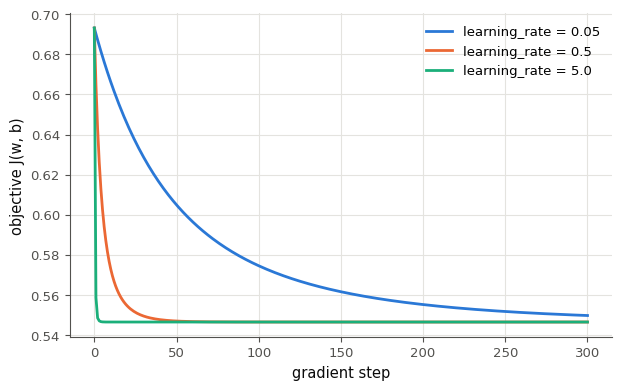

pytest: 39 passed, 1 deselected in 1.00s


In [78]:
if written(lambda: mylearn.logistic.LogisticRegression) and not written(
        lambda: mylearn.info.log_loss(np.array([0, 1]), np.array([0.2, 0.7]))):
    print("⏳ Ex 13.32 : ta fonction log_loss du ch. 6 (mylearn/info.py) n'est pas écrite ; ta LogisticRegression "
          "s'en sert pour son objectif : complète-la d'abord (exercices du ch. 6).")
with checked("13.32"):
    doc_32 = fitted(mylearn.logistic.LogisticRegression(), np.array([[-2.0], [-1.0], [0.0], [1.0], [2.0]]),
                    np.array([0, 1, 0, 1, 1]))
    print("docstring example: loss_history_[0] =", round(float(doc_32.loss_history_[0]), 4), "(expected 0.6931) · "
          "predict([[-3], [3]]) =", np.asarray(doc_32.predict(np.array([[-3.0], [3.0]]))).tolist(), "(expected [0, 1])")
with checked("13.32"):
    pair_32 = ["bill_depth_mm", "flipper_length_mm"]       # two measures where the two species overlap
    scaler_32 = StandardScaler().fit(AC_TRAIN[pair_32])
    Z_32, y_32 = scaler_32.transform(AC_TRAIN[pair_32]), AC_TRAIN["species"].to_numpy()
    for alpha, C, label in [(0.0, np.inf, "C=np.inf"), (0.01, 1 / (0.01 * len(Z_32)), "C=1/(alpha*n)")]:
        mine_32 = fitted(mylearn.logistic.LogisticRegression(alpha=alpha, learning_rate=0.5, max_iter=5000, tol=1e-9),
                         Z_32, y_32)
        oracle_32 = LogisticRegression(C=C, tol=1e-10, max_iter=10_000).fit(Z_32, y_32)
        coef_32 = np.asarray(mine_32.coef_, dtype=float)
        print(f"alpha = {alpha}: {mine_32.n_iter_} steps · coef_ {np.round(coef_32, 4).tolist()} (shape {coef_32.shape}), "
              f"intercept_ {float(mine_32.intercept_):.4f} · scikit-learn ({label}): "
              f"{np.round(oracle_32.coef_[0], 4).tolist()}, {oracle_32.intercept_[0]:.4f}")
        verdict("13.32", coef_32.shape == (2,) and np.allclose(coef_32, oracle_32.coef_[0], atol=1e-3)
                and np.isclose(float(mine_32.intercept_), oracle_32.intercept_[0], atol=1e-3),
                f"alpha = {alpha} : mêmes poids et même ordonnée à l'origine que scikit-learn avec {label}.",
                f"alpha = {alpha} : tes poids ou ton ordonnée à l'origine diffèrent de ceux de scikit-learn avec {label} ; "
                "les tests ci-dessous disent où.")
    default_32 = LogisticRegression().fit(Z_32, y_32)
    print("scikit-learn with its default settings (C=1.0):", np.round(default_32.coef_[0], 4).tolist())
with checked("13.32"):
    histories_32 = {rate: list(fitted(mylearn.logistic.LogisticRegression(learning_rate=rate, max_iter=300, tol=0.0),
                                      Z_32, y_32).loss_history_) for rate in [0.05, 0.5, 5.0]}
    for rate, history_32 in histories_32.items():
        plt.plot(history_32, label=f"learning_rate = {rate}")
    plt.xlabel("gradient step")
    plt.ylabel("objective J(w, b)")
    plt.legend()
    plt.show()
if written(lambda: mylearn.logistic.LogisticRegression().fit(np.array([[0.0], [1.0]]), np.array([0, 1]))):
    run_mylearn_tests(impl="ref", module="logistic", keyword="test_logistic_regression_")
else:
    print("⏳ Ex 13.32 : les tests attendent le fit de ta LogisticRegression.")

💡 scikit-learn minimise $\frac12\lVert\mathbf{w}\rVert^2 + C \sum_i \ell_i$, une **somme** de log-loss ; ta librairie minimise la **moyenne** plus $\frac{\alpha}{2}\lVert\mathbf{w}\rVert^2$. En divisant la première par $Cn$, on retrouve la seconde avec $\alpha = 1/(Cn)$, d'où $C = 1/(\alpha n)$. `LogisticRegression()` a `C=1.0` par défaut, une pénalité de force $\alpha = 1/n$ : ses poids sont plus petits que ceux d'une descente sans pénalité (l'annexe des erreurs fréquentes le signale). Avec un learning rate de 0,05, l'objectif descend lentement et n'a pas fini après 300 pas ; avec 0,5, il atteint son minimum en 70 pas environ ; avec 5, en quelques pas : sur des données standardisées, la courbure de la log-loss reste faible, et un grand pas reste stable.

## Partie F · Synthèse : lire, mesurer, comparer

Reconnaître un classifieur à sa frontière (13.33), mesurer et accélérer le calcul des distances d'un kNN (13.34), comparer ta librairie à scikit-learn en accuracy et en temps (13.35), puis le défi : 96 % sur MNIST avec un classifieur classique (13.36).

In [79]:
from scipy.spatial.distance import cdist
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline

### Ex 13.33 — Associer quatre frontières à leurs classifieurs 📈 ★ ⏱️ 15 min
**Objectif :** reconnaître un classifieur à la forme de sa frontière.  
**Prérequis :** Ex 13.12 · fiche §13.7 (tableau « frontière ») · **Fil rouge :** synth · **Parcours :** R

La cellule suivante entraîne quatre classifieurs sur les mêmes 300 points de deux demi-lunes bruitées, et trace leurs frontières dans un ordre mélangé (panneaux 1 à 4). Les classifieurs : A `KNeighborsClassifier(n_neighbors=1)` ; B `DecisionTreeClassifier(max_depth=6)` ; C `GaussianNB()` ; D `LogisticRegression()`. Réponds sans réentraîner les modèles :
a) `panels_33` : les lettres des classifieurs des panneaux 1, 2, 3 et 4, dans cet ordre (par exemple `"ABCD"`) ;
b) `perfect_33` : le numéro du panneau dont le classifieur classe correctement **tous** ses points d'entraînement.

Dans tes notes : pour chaque panneau, le détail qui t'a décidé. Lequel de ces quatre modèles choisirais-tu pour ces données, et comment le vérifierais-tu ?

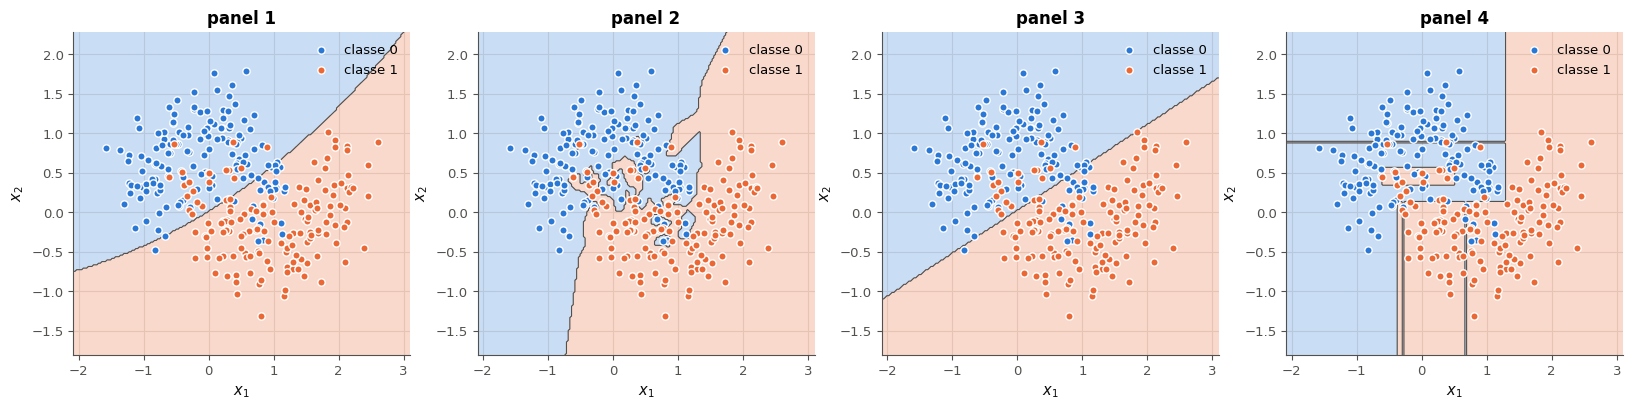

In [80]:
X_33, Y_33 = wb.synth.make_moons(n=300, noise=0.3, seed=1333)
CLASSIFIERS_33 = {"A": KNeighborsClassifier(n_neighbors=1), "B": DecisionTreeClassifier(max_depth=6, random_state=0),
                  "C": GaussianNB(), "D": LogisticRegression()}
ORDER_33 = "".join(np.random.default_rng(1302).permutation(list(CLASSIFIERS_33)))   # the order of the panels
fig, axes = plt.subplots(1, 4, figsize=(20, 4.2))
for panel, (ax, letter) in enumerate(zip(axes, ORDER_33), start=1):
    model = CLASSIFIERS_33[letter].fit(X_33, Y_33)
    wb.plot.plot_decision_boundary(model, X_33, Y_33, ax=ax, title=f"panel {panel}")
plt.show()
del ORDER_33                         # the answer is not kept in the notebook

In [81]:
panels_33, perfect_33 = "CADB", 2   # the answers, for the record
for letter, model in CLASSIFIERS_33.items():
    print(letter, type(model).__name__, "training accuracy:", round(model.score(X_33, Y_33), 3))
print_answer("13.33a", panels_33)
print_answer("13.33b", perfect_33)

A KNeighborsClassifier training accuracy: 1.0
B DecisionTreeClassifier training accuracy: 0.94
C GaussianNB training accuracy: 0.847
D LogisticRegression training accuracy: 0.857
13.33a: CADB
13.33b: 2


In [82]:
wb.record("13.33a", "CADB",
          mistakes={"relis les panneaux 1 et 3 : lequel trace une droite, lequel une courbe ? (§13.7, frontière de Naïve Bayes et de la régression logistique)": "DACB",
                    "relis les panneaux 2 et 4 : lequel est fait de segments horizontaux et verticaux, lequel épouse chaque point ? (§13.3 et §13.5.1)": "CBDA",
                    "relis les quatre panneaux : quel modèle trace des escaliers parallèles aux axes, lequel une droite ? (§13.7)": "ABCD"})
wb.record("13.33b", 2, choices=[1, 2, 3, 4],
          mistakes={"un modèle qui classe parfaitement l'entraînement fait de chaque point une région à lui : cherche les îlots autour des points isolés": 4,
                    "ce panneau laisse des points d'entraînement du mauvais côté de sa frontière : cherche celui où chaque point a sa région": 1,
                    "ce panneau-là laisse aussi des points d'entraînement du mauvais côté : cherche celui où chaque point a sa région": 3})

WB_ANSWER {"hash": "7ff545053d875273396cfdb9b0e2e0c6f7966da0e878a178b1834863711efc43", "id": "13.33a", "kind": "str", "mistakes": {"0cba59780fa575f20c3ca24cee056091e7bc803b35e38c934475ffd4c08772ba": "relis les panneaux 2 et 4 : lequel est fait de segments horizontaux et verticaux, lequel épouse chaque point ? (§13.3 et §13.5.1)", "2d265b60d620883ee10a92048390302710e908100b1d4c87d3e728950033fbb6": "relis les panneaux 1 et 3 : lequel trace une droite, lequel une courbe ? (§13.7, frontière de Naïve Bayes et de la régression logistique)", "a7ec5c556098f63d0ab2a4e1a4ffe73fa14e1fc639b1b3d99e473aaa32deb4f6": "relis les quatre panneaux : quel modèle trace des escaliers parallèles aux axes, lequel une droite ? (§13.7)"}}
📝 Ex 13.33a : réponse enregistrée (str).
WB_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "42cae3156d27e2d1297df05d229a89c6d87dfa8128e76a7c9daf5efce27d5e0b", "id": "13.33b", "kind": "int", "magnitude": 0, "mistakes": {"0e3e5d7a2314c0c1fa562ca04c3a3f5f84d2955617ef0a45a5328341

💡 Panneau 1 : une courbe lisse, ni droite ni en escalier, la frontière quadratique de Naïve Bayes gaussien (C). Panneau 2 : une frontière qui contourne chaque point, des îlots autour des points isolés : le plus proche voisin (A), seul à classer parfaitement l'entraînement (chaque point est son propre voisin). Panneau 3 : une droite, la régression logistique (D). Panneau 4 : des segments horizontaux et verticaux, l'arbre (B), qui fait 0,94 sur l'entraînement. Pour ces lunes, on comparerait un kNN avec un $k$ plus grand, un arbre réglé et un SVM RBF en validation croisée, sur les mêmes folds.

### Ex 13.34 — Mesurer et vectoriser : accélérer son kNN 🛠️ ★★ ⏱️ 25 min
**Objectif :** mesurer un temps d'exécution proprement, et remplacer une boucle par du calcul vectorisé.  
**Prérequis :** Ex 13.14 · 0B (produit matriciel) · fiche §13.3 (le coût d'un kNN) · **Fil rouge :** MNIST · **Parcours :** C

`TRAIN_34` : 2 000 images de MNIST, `TEST_34` : 500, pixels dans $[0, 1]$. Un kNN passe son temps à calculer des distances : trois façons de calculer la matrice `(len(A), len(B))` des distances euclidiennes, et un outil de mesure. Écris :
- `distances_loop_34(A, B)` : deux boucles Python sur les lignes (NumPy pour la distance d'une paire) ;
- `distances_broadcast_34(A, B)` : une seule différence par broadcasting, `A[:, None, :] - B[None, :, :]`, sans boucle ;
- `distances_dot_34(A, B)` : l'identité $\lVert\mathbf{a} - \mathbf{b}\rVert^2 = \lVert\mathbf{a}\rVert^2 - 2\,\mathbf{a}\cdot\mathbf{b} + \lVert\mathbf{b}\rVert^2$, avec un seul produit matriciel pour tous les $\mathbf{a}\cdot\mathbf{b}$ ; elle ne doit **jamais** rendre `nan` ;
- `timed_34(function, *args, repeat=3)` : la plus petite de `repeat` durées de `function(*args)`, mesurées avec `time.perf_counter()` (le minimum écarte les mesures ralenties par autre chose ; `timeit` fait la même chose).

La vérification compare les trois versions à `scipy.spatial.distance.cdist`, mesure chacune sur un morceau du problème et estime son temps pour les 500 × 2 000 distances, compte les `nan` de l'identité, puis classe les images de test par leur plus proche voisin avec tes distances. Ne lance pas la version par broadcasting sur tout le problème : la vérification affiche la mémoire qu'elle demanderait. Cet exercice se corrige avec `05_solutions.md`.

Dans tes notes : classe les trois versions par vitesse ; pourquoi le broadcasting n'est-il pas le plus rapide ? D'où viennent les `nan` de l'identité, et pourquoi n'apparaissent-ils qu'entre une image et elle-même (ou une image presque identique) ?

In [83]:
TRAIN_34, Y_TRAIN_34 = wb.datasets.load_mnist("train", n=2000, flatten=True, seed=1334)
TEST_34, Y_TEST_34 = wb.datasets.load_mnist("test", n=500, flatten=True, seed=1334)
TRAIN_34, TEST_34 = TRAIN_34 / 255.0, TEST_34 / 255.0     # pixels in [0, 1], float64
print(TRAIN_34.shape, TEST_34.shape)

(2000, 784) (500, 784)


In [84]:
def distances_loop_34(A, B):
    """Euclidean distance matrix (len(A), len(B)), with two Python loops over the rows (NumPy for one pair)."""
    D = np.empty((len(A), len(B)))
    for i in range(len(A)):
        for j in range(len(B)):
            D[i, j] = np.sqrt(np.sum((A[i] - B[j]) ** 2))
    return D


def distances_broadcast_34(A, B):
    """The same, with one broadcast difference A[:, None, :] - B[None, :, :] and no Python loop."""
    return np.sqrt(((A[:, None, :] - B[None, :, :]) ** 2).sum(axis=2))


def distances_dot_34(A, B):
    """The same, with ||a - b||² = ||a||² - 2 a.b + ||b||² (one matrix product for all the a.b), never nan."""
    squared = (A ** 2).sum(axis=1)[:, None] - 2 * A @ B.T + (B ** 2).sum(axis=1)[None, :]
    return np.sqrt(np.maximum(squared, 0.0))           # rounding can give -1e-12: no sqrt of a negative number


def timed_34(function, *args, repeat=3):
    """The smallest of `repeat` durations of function(*args), in seconds (time.perf_counter)."""
    durations = []
    for _ in range(repeat):
        start = time.perf_counter()
        function(*args)
        durations.append(time.perf_counter() - start)
    return min(durations)
def as_matrix_34(name, D, shape):
    """The distance matrix returned by `name`, or None with a ❌ line when it is None or has the wrong shape."""
    if not returned("13.34", name, D):
        return None
    try:
        D = np.asarray(D, dtype=float)
    except (TypeError, ValueError):
        print(f"❌ Ex 13.34 : {name} doit rendre un tableau de nombres, pas un {type(D).__name__}.")
        return None
    if D.shape != shape:
        print(f"❌ Ex 13.34 : {name} doit rendre une matrice de forme {shape} (une ligne par ligne de A, une colonne "
              f"par ligne de B), pas {D.shape}.")
        return None
    return D


with checked("13.34"):
    A_34, B_34 = TEST_34[:10], TRAIN_34[:200]
    exact_34 = cdist(A_34, B_34)
    for name_34, function_34 in [("distances_loop_34", distances_loop_34), ("distances_broadcast_34", distances_broadcast_34),
                                 ("distances_dot_34", distances_dot_34)]:
        try:
            D_34 = as_matrix_34(name_34, function_34(A_34, B_34), (10, 200))
        except NotImplementedError:
            print(f"⏳ Ex 13.34 : {name_34} n'est pas encore écrite.")
            continue
        if D_34 is not None:
            verdict("13.34", np.allclose(D_34, exact_34), f"{name_34} rend les distances de scipy (cdist).",
                    f"{name_34}(TEST_34[:10], TRAIN_34[:200]) a la bonne forme, mais pas les distances de cdist "
                    f"(par exemple {D_34[0, 0]:.4f} au lieu de {exact_34[0, 0]:.4f} pour la première case) : la racine "
                    "de la somme des carrés des différences ?")
with checked("13.34"):
    calls_34 = []
    def slow_first_34():                                  # 0.1 s at the first call, then 0.01 s
        time.sleep(0.1 if not calls_34 else 0.01)
        calls_34.append(1)
    probe_34 = timed_34(slow_first_34, repeat=3)
    if returned("13.34", "timed_34", probe_34):
        if not isinstance(probe_34, (int, float, np.floating)):
            print(f"❌ Ex 13.34 : timed_34 doit rendre UNE durée (un nombre de secondes), pas un {type(probe_34).__name__}.")
        else:
            verdict("13.34", 0.009 < probe_34 < 0.02,
                    "timed_34 rend bien la plus petite des durées, en secondes.",
                    f"timed_34 rend {probe_34!r} pour trois appels de 0,1 s, 0,01 s et 0,01 s : la plus petite durée, "
                    "en secondes (environ 0,01), était attendue (pas la moyenne, ni la somme, ni des millisecondes).")
with checked("13.34"):
    pairs_full_34 = len(TEST_34) * len(TRAIN_34)               # 500 x 2,000 distances
    rows_34 = []
    for name_34, function_34, a_34, b_34 in [("loop", distances_loop_34, TEST_34[:10], TRAIN_34[:200]),
                                              ("broadcast", distances_broadcast_34, TEST_34[:50], TRAIN_34[:500]),
                                              ("dot product", distances_dot_34, TEST_34, TRAIN_34)]:
        seconds_34 = float(timed_34(function_34, a_34, b_34))
        rows_34.append((name_34, f"{len(a_34)} x {len(b_34)}", seconds_34, seconds_34 * pairs_full_34 / (len(a_34) * len(b_34))))
    fastest_34 = min(row[3] for row in rows_34)
    print(f"{'version':12s} {'measured on':12s} {'time (s)':>9s} {'500 x 2000 (s)':>15s} {'x fastest':>10s}")
    for name_34, size_34, seconds_34, full_34 in rows_34:
        print(f"{name_34:12s} {size_34:12s} {seconds_34:9.4f} {full_34:15.3f} {full_34 / fastest_34:10.0f}")
    print(f"memory of the broadcast difference for 500 x 2000 images: {500 * 2000 * 784 * 8 / 1e9:.1f} GB")
with checked("13.34"):
    with np.errstate(invalid="ignore"):
        squared_34 = ((TRAIN_34 ** 2).sum(axis=1)[:, None] - 2 * TRAIN_34 @ TRAIN_34.T
                      + (TRAIN_34 ** 2).sum(axis=1)[None, :])
        naive_nan_34 = int(np.isnan(np.sqrt(squared_34)).sum())
        mine_34 = as_matrix_34("distances_dot_34", distances_dot_34(TRAIN_34, TRAIN_34), (2000, 2000))
    if mine_34 is not None:
        mine_nan_34 = int(np.isnan(mine_34).sum())
        print(f"distances between the 2,000 training images: {naive_nan_34} nan with a plain sqrt of the identity, "
              f"{mine_nan_34} with distances_dot_34")
        verdict("13.34", mine_nan_34 == 0, "distances_dot_34 ne rend jamais nan.",
                "distances_dot_34 rend des nan : l'arrondi donne des carrés légèrement négatifs, dont la racine "
                "n'existe pas.")
        nearest_34 = np.argmin(as_matrix_34("distances_dot_34", distances_dot_34(TEST_34, TRAIN_34), (500, 2000)), axis=1)
        accuracy_34 = float(np.mean(Y_TRAIN_34[nearest_34] == Y_TEST_34))
        oracle_34 = KNeighborsClassifier(n_neighbors=1, algorithm="brute").fit(TRAIN_34, Y_TRAIN_34).score(TEST_34, Y_TEST_34)
        verdict("13.34", np.isclose(accuracy_34, oracle_34),
                f"le plus proche voisin calculé avec tes distances fait {fr(accuracy_34)}, comme scikit-learn.",
                f"le plus proche voisin calculé avec tes distances fait {fr(accuracy_34)}, scikit-learn {fr(oracle_34)}.")

✅ Ex 13.34 : distances_loop_34 rend les distances de scipy (cdist).
✅ Ex 13.34 : distances_broadcast_34 rend les distances de scipy (cdist).
✅ Ex 13.34 : distances_dot_34 rend les distances de scipy (cdist).
✅ Ex 13.34 : timed_34 rend bien la plus petite des durées, en secondes.


version      measured on   time (s)  500 x 2000 (s)  x fastest
loop         10 x 200        0.0096           4.797        212
broadcast    50 x 500        0.0971           3.885        172
dot product  500 x 2000      0.0227           0.023          1
memory of the broadcast difference for 500 x 2000 images: 6.3 GB
distances between the 2,000 training images: 628 nan with a plain sqrt of the identity, 0 with distances_dot_34
✅ Ex 13.34 : distances_dot_34 ne rend jamais nan.


✅ Ex 13.34 : le plus proche voisin calculé avec tes distances fait 0,906, comme scikit-learn.


💡 La boucle calcule environ 4 µs par paire, soit quelques secondes pour les 500 × 2 000 distances. Le broadcasting est du même ordre que la boucle (l'une ou l'autre gagne selon la machine) : il fabrique un tableau intermédiaire de 500 × 2 000 × 784 nombres (6,3 Go, d'où sa mesure sur un morceau) et passe son temps à écrire et relire la mémoire. Le produit matriciel calcule tout en quelques centièmes de seconde : la bibliothèque d'algèbre linéaire découpe le calcul en blocs qui tiennent dans le cache du processeur, sur plusieurs cœurs. Entre une image et elle-même, $\lVert\mathbf{a}\rVert^2 - 2\,\mathbf{a}\cdot\mathbf{a} + \lVert\mathbf{a}\rVert^2$ vaut 0 en théorie, mais l'arrondi des deux calculs (une somme de carrés, un produit matriciel) peut laisser $-10^{-12}$ : sa racine vaut `nan`. `np.maximum(..., 0)` avant la racine règle le problème. Les pixels entiers de 0 à 255 ne le montrent pas : leurs sommes sont exactes en `float64`.

### Ex 13.35 — Comparatif mylearn contre scikit-learn : accuracy et temps 🔬 ★★★ ⏱️ 45 min
**Objectif :** comparer des implémentations sur les mêmes données, en accuracy et en temps.  
**Prérequis :** Ex 13.14, 13.24 et 13.28 · ch. 12 (PCA) · fiche §13.7 · **Fil rouge :** MNIST · **Parcours :** C

500 images de MNIST pour l'entraînement et 500 pour le test, réduites à 50 coordonnées par une PCA (ch. 12). Écris `timed_fit_score_35(model, X_train, y_train, X_test, y_test)`, qui entraîne le modèle, mesure son accuracy sur le test, et rend le tuple `(accuracy, durée du fit en s, durée du score en s)`, mesurées avec `time.perf_counter()`.

La vérification l'applique à trois classifieurs de **ta** librairie et à leurs équivalents de scikit-learn : le kNN ($k = 3$), Naïve Bayes gaussien et l'arbre sans limite, affiche un tableau, contrôle les accuracies de ton kNN et de ton Naïve Bayes (a et b) et vérifie que ton arbre est à 3 points de celui de scikit-learn (les égalités de gain, fréquentes ici, se départagent autrement).

Dans tes notes : qui passe son temps à l'entraînement, qui à la prédiction ? Combien de fois ta librairie est-elle plus lente que scikit-learn pour chacun, et pourquoi (pense à ce que scikit-learn écrit en C, et à la boucle sur les seuils de ton `best_split`) ? Lequel des trois choisirais-tu sur ces données ?

In [85]:
X_RAW_TRAIN_35, Y_TRAIN_35 = wb.datasets.load_mnist("train", n=500, flatten=True, seed=1335)
X_RAW_TEST_35, Y_TEST_35 = wb.datasets.load_mnist("test", n=500, flatten=True, seed=1335)
PCA_35 = PCA(n_components=50, random_state=0).fit(X_RAW_TRAIN_35 / 255.0)
Z_TRAIN_35, Z_TEST_35 = PCA_35.transform(X_RAW_TRAIN_35 / 255.0), PCA_35.transform(X_RAW_TEST_35 / 255.0)
print(Z_TRAIN_35.shape, Z_TEST_35.shape, "(500 images, 50 PCA coordinates)")

(500, 50) (500, 50) (500 images, 50 PCA coordinates)


In [86]:
def timed_fit_score_35(model, X_train, y_train, X_test, y_test):
    """Fit `model` on the training part, then score it on the test part. Return the tuple (accuracy, fit time in
    seconds, scoring time in seconds), both times measured with time.perf_counter."""
    start = time.perf_counter()
    model.fit(X_train, y_train)
    middle = time.perf_counter()
    accuracy = model.score(X_test, y_test)
    return float(accuracy), middle - start, time.perf_counter() - middle
def measured_35(result):
    """The tuple (accuracy, fit seconds, score seconds) returned by timed_fit_score_35, or None with a ❌ line."""
    if not returned("13.35", "timed_fit_score_35", result):
        return None
    if not isinstance(result, tuple) or len(result) != 3:
        print("❌ Ex 13.35 : timed_fit_score_35 doit rendre un tuple de trois nombres (accuracy, durée du fit, durée "
              f"du score), pas {type(result).__name__} {result!r}.")
        return None
    accuracy, fit_seconds, score_seconds = (float(value) for value in result)
    if not 0 <= accuracy <= 1:
        print(f"❌ Ex 13.35 : une accuracy de {accuracy} : elle est entre 0 et 1, en première position du tuple.")
        return None
    return accuracy, fit_seconds, score_seconds


pairs_35 = [("kNN (k = 3)", "13.14", lambda: mylearn.neighbors.KNeighborsClassifier(n_neighbors=3),
             lambda: KNeighborsClassifier(n_neighbors=3, algorithm="brute")),
            ("GaussianNB", "13.28", lambda: mylearn.naive_bayes.GaussianNB(), lambda: GaussianNB()),
            ("tree", "13.24", lambda: mylearn.tree.DecisionTreeClassifier(), lambda: DecisionTreeClassifier(random_state=0))]
results_35 = {}
if True:
    print(f"{'classifier':14s} {'library':13s} {'accuracy':>9s} {'fit (s)':>9s} {'score (s)':>10s}")
    for name_35, exercise_35, mine_35, oracle_35 in pairs_35:
        if not written(lambda: mine_35().fit(Z_TRAIN_35[:5], Y_TRAIN_35[:5])):
            print(f"⏳ {name_35} : ta classe ({exercise_35}) n'est pas encore écrite.")
            continue
        for library_35, model_35 in [("mylearn", mine_35()), ("scikit-learn", oracle_35())]:
            try:
                result_35 = measured_35(timed_fit_score_35(model_35, Z_TRAIN_35, Y_TRAIN_35, Z_TEST_35, Y_TEST_35))
            except AttributeError as exc:
                if "NoneType" not in str(exc):
                    raise
                print(f"❌ Ex 13.35 : {name_35} ({library_35}) : {exc} : n'enchaîne pas fit(...).score(...) (un fit "
                      "sans return self rend None), appelle fit, puis score.")
                result_35 = None
            if result_35 is None:
                break
            results_35[name_35, library_35] = result_35
            print(f"{name_35:14s} {library_35:13s} {result_35[0]:9.3f} {result_35[1]:9.3f} {result_35[2]:10.3f}")
if ("kNN (k = 3)", "mylearn") in results_35:
    print_answer("13.35a", results_35["kNN (k = 3)", "mylearn"][0], computed=True)
if ("GaussianNB", "mylearn") in results_35:
    print_answer("13.35b", results_35["GaussianNB", "mylearn"][0], computed=True)
if ("tree", "mylearn") in results_35 and ("tree", "scikit-learn") in results_35:
    tree_gap_35 = abs(results_35["tree", "mylearn"][0] - results_35["tree", "scikit-learn"][0])
    verdict("13.35", tree_gap_35 <= 0.03,
            "ton arbre a l'accuracy de celui de scikit-learn, à 3 points près (les égalités de gain se départagent "
            "autrement).",
            f"ton arbre s'écarte de {fr(tree_gap_35)} de celui de scikit-learn : plus de 3 points, ce n'est pas qu'une "
            "affaire d'égalités ; relance les tests de 13.24.")

classifier     library        accuracy   fit (s)  score (s)
kNN (k = 3)    mylearn           0.840     0.000      0.172


kNN (k = 3)    scikit-learn      0.840     0.003      0.021
GaussianNB     mylearn           0.816     0.001      0.002


GaussianNB     scikit-learn      0.816     0.004      0.002
tree           mylearn           0.578     0.109      0.001
tree           scikit-learn      0.580     0.023      0.001
13.35a: 0.84
13.35b: 0.816
✅ Ex 13.35 : ton arbre a l'accuracy de celui de scikit-learn, à 3 points près (les égalités de gain se départagent autrement).


In [87]:
wb.record("13.35a", results_35["kNN (k = 3)", "scikit-learn"][0], decimals=4)
wb.record("13.35b", results_35["GaussianNB", "scikit-learn"][0], decimals=4)

WB_ANSWER {"decimals": 4, "hash": "b20daa2d0de5d9ea43e6d617b4716f07a8ae35023c46376234574bd2c4820cfd", "hash_coarse": "027f68d83889b6bad64cd023272e3535667ca0a2c254a64f3008995ee3d820cc", "id": "13.35a", "kind": "float", "magnitude": -1, "sign": 1}
📝 Ex 13.35a : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"decimals": 4, "hash": "546abb552ccf7c02f66706fb264a574b484d160355ded534f523812cdb93778a", "hash_coarse": "e63dcfcc513c765f75cc9f7362d67791f5294633fb530db3d8b0fdc2fd78de62", "id": "13.35b", "kind": "float", "magnitude": -1, "sign": 1}
📝 Ex 13.35b : réponse enregistrée (float, 4 décimale(s)).


💡 Le kNN ne fait rien à l'entraînement et passe tout son temps à la prédiction (250 000 distances de 50 coordonnées) ; Naïve Bayes est rapide partout (un passage pour les moyennes, un calcul par classe à la prédiction) ; l'arbre passe son temps à l'entraînement (la recherche des seuils) et prédit presque instantanément. Naïve Bayes est du même ordre dans les deux librairies. Ton kNN, écrit avec la différence par broadcasting (13.14), est plusieurs fois plus lent que celui de scikit-learn (de 3 à plusieurs dizaines de fois selon la machine), qui passe par le produit matriciel de 🛠️ 13.34 et du code compilé. Ton arbre l'est de quelques fois (la référence, qui trie chaque feature une fois) à plusieurs centaines de fois (un `best_split` qui recalcule les impuretés à chaque seuil, en Python) : scikit-learn parcourt les seuils en C en mettant les comptes à jour. Sur ces données, le kNN (0,84) devance Naïve Bayes (0,82) et de loin l'arbre (0,58) : un arbre seul sur 50 coordonnées de PCA et 500 images surapprend ; les forêts du ch. 14 corrigeront cela.

### Ex 13.36 — Défi : 96 % sur MNIST avec un classifieur classique 🏆 ★★★★ ⏱️ 100 min
**Objectif :** construire, régler et valider un classifieur classique qui atteint 96 % sur MNIST.  
**Prérequis :** Ex 13.18, 13.14 · ch. 12 (PCA, mise à l'échelle) · ch. 8 (validation croisée) · **Fil rouge :** MNIST · **Parcours :** C

**Objectif** : au moins **96 %** d'accuracy sur les 2 000 premières images de test de MNIST, avec au plus **20 000** images d'entraînement, sans réseau de neurones : un classifieur de ce chapitre (kNN, SVM, arbre, Naïve Bayes, régression logistique), avec la préparation du ch. 12 si tu veux (PCA, mise à l'échelle). Écris `N_TRAIN_36`, le nombre d'images d'entraînement, et `build_model_36()`, qui rend un modèle scikit-learn **neuf** (souvent un pipeline) qui reçoit des pixels dans $[0, 1]$.

Règles : les 2 000 images de test ne servent qu'à la mesure finale ; règle tes hyperparamètres par validation croisée sur l'entraînement (dans une cellule à toi, sur un sous-ensemble si c'est long). La vérification charge `N_TRAIN_36` images d'entraînement, entraîne ton modèle, mesure les temps et l'accuracy. Ce défi se corrige avec `05_solutions.md`.

Dans tes notes : les modèles essayés, leurs réglages et leurs scores de validation croisée ; le temps d'entraînement et de prédiction du modèle retenu ; ce que tu essaierais pour aller plus loin.

In [88]:
X_TEST_36, Y_TEST_36 = wb.datasets.load_mnist("test", flatten=True)
X_TEST_36, Y_TEST_36 = X_TEST_36[:2000] / 255.0, Y_TEST_36[:2000]       # the first 2,000 test images, never for tuning
print(X_TEST_36.shape)

(2000, 784)


In [89]:
N_TRAIN_36 = 20_000


def build_model_36():
    """Return a NEW, unfitted scikit-learn classifier (often a pipeline) that takes pixels in [0, 1], shape (n, 784).
    No neural network: a classifier of this chapter, with any preprocessing of chapter 12."""
    return make_pipeline(PCA(n_components=50, random_state=0), SVC(C=10))   # chosen by cross-validation (05_solutions.md)
if True:
    if not filled(N_TRAIN_36):
        raise NotImplementedError("N_TRAIN_36")
    if not 1 <= int(N_TRAIN_36) <= 20_000:
        print(f"❌ Ex 13.36 : {N_TRAIN_36} images d'entraînement : le défi en demande de 1 à 20 000.")
    else:
        X_train_36, y_train_36 = wb.datasets.load_mnist("train", n=int(N_TRAIN_36), flatten=True, seed=1336)
        model_36 = build_model_36()
        if returned("13.36", "build_model_36", model_36):
            start_36 = time.perf_counter()
            model_36.fit(X_train_36 / 255.0, y_train_36)
            fit_36 = time.perf_counter() - start_36
            start_36 = time.perf_counter()
            accuracy_36 = model_36.score(X_TEST_36, Y_TEST_36)
            print(f"{int(N_TRAIN_36)} training images · fit {fit_36:.1f} s · prediction of 2,000 images "
                  f"{time.perf_counter() - start_36:.1f} s · test accuracy {accuracy_36:.4f}")
            verdict("13.36", accuracy_36 >= 0.96, f"{fr(100 * accuracy_36, 2)} % : défi réussi.",
                    f"{fr(100 * accuracy_36, 2)} % : il manque {fr(100 * (0.96 - accuracy_36), 2)} point(s) ; règle ton "
                    "modèle par validation croisée sur l'entraînement, jamais sur ces 2 000 images.")

20000 training images · fit 4.3 s · prediction of 2,000 images 0.7 s · test accuracy 0.9670
✅ Ex 13.36 : 96,70 % : défi réussi.


💡 Une PCA à 50 composantes suivie d'un SVM RBF ($C = 10$, $\gamma$ par défaut) atteint 96,7 % avec 20 000 images, en quelques secondes. Un kNN sur les mêmes 50 composantes plafonne vers 95 % : le défi est réel. Les arbres seuls et Naïve Bayes en sont loin. Les réglages viennent de la validation croisée sur l'entraînement (05_solutions.md donne la grille).

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu dire, pour chaque classifieur du chapitre, ce qu'il garde en mémoire, où il passe son temps et ce qu'il suppose des données ?
2. Sais-tu calculer à la main un vote kNN, une marge, un gain de split et un posterior de Naïve Bayes ?
3. Sais-tu choisir une baseline et régler ses hyperparamètres par validation croisée ?

**Pour aller plus loin** : les guides utilisateur de scikit-learn sur les plus proches voisins, les SVM, les arbres et Naïve Bayes, et l'article de Domingos et Pazzani, cités dans la fiche. La suite : le ch. 14 (ensembles), qui construira forêts aléatoires, AdaBoost et gradient boosting avec tes arbres de `mylearn.tree`.